In [1]:
from google.colab import drive
import os

drive.mount('/content/drive')
base = "/content/drive/MyDrive/UTokyo/Proteome"


Mounted at /content/drive


# Block 0 - Extract MS-detected sequence from proteome

In [ ]:
import os
import re
import pandas as pd

# =========================
# PATHS
# =========================
project_path = os.path.join(base, "Prediction_vs_Detection", "MS_data")
outdir = os.path.join(base, "MS_data")
os.makedirs(outdir, exist_ok=True)

ms_table = os.path.join(project_path, "Snat_20250411_2025G24_e2_Proteins.txt")
proteome_faa = os.path.join(project_path, "Snat_JGI_proteome.faa")
out_faa = os.path.join(outdir, "Snat_MS_detected_proteome.faa")
out_tsv = os.path.join(outdir, "Snat_MS_detected_ids.tsv")

# optional
keep_only_high = False


# =========================
# HELPERS
# =========================
def extract_id_from_fasta_title(x):
    """
    Example:
      >jgi|Symmic1|31500|rna4278 -> jgi|Symmic1|31500|rna4278
      >id1;>id2 -> keep first one
    """
    if pd.isna(x):
        return None
    x = str(x).strip()
    if not x:
        return None
    x = x.split(";")[0].strip()
    x = x.lstrip(">")
    x = x.split()[0]
    return x


def read_fasta_as_records(fasta_file):
    """
    Returns list of (header_id, full_header, sequence)
    header_id = first token after '>'
    """
    records = []
    current_header = None
    current_id = None
    seq_chunks = []

    with open(fasta_file, "r") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                continue
            if line.startswith(">"):
                if current_id is not None:
                    records.append((current_id, current_header, "".join(seq_chunks)))
                current_header = line[1:]
                current_id = current_header.split()[0]
                seq_chunks = []
            else:
                seq_chunks.append(line.strip())

    if current_id is not None:
        records.append((current_id, current_header, "".join(seq_chunks)))

    return records


# =========================
# 1. READ MS TABLE
# =========================
ms = pd.read_csv(ms_table, sep="\t")

if keep_only_high and "Protein FDR Confidence: Combined" in ms.columns:
    ms = ms[ms["Protein FDR Confidence: Combined"].eq("High")].copy()

ms["ms_id"] = ms["FASTA Title Lines"].apply(extract_id_from_fasta_title)
ms = ms[ms["ms_id"].notna()].copy()
ms = ms.drop_duplicates(subset="ms_id")

ms_ids = set(ms["ms_id"])
print(f"Unique MS IDs: {len(ms_ids):,}")

ms[["ms_id"]].to_csv(out_tsv, sep="\t", index=False)


# =========================
# 2. READ WHOLE PROTEOME FASTA
# =========================
records = read_fasta_as_records(proteome_faa)
print(f"Proteome sequences: {len(records):,}")


# =========================
# 3. FILTER FASTA BY MS IDs
# =========================
matched = []
unmatched_ids = set(ms_ids)

for rid, full_header, seq in records:
    if rid in ms_ids:
        matched.append((rid, full_header, seq))
        unmatched_ids.discard(rid)

print(f"Matched FASTA entries: {len(matched):,}")
print(f"Unmatched MS IDs: {len(unmatched_ids):,}")


# =========================
# 4. WRITE NEW FASTA
# =========================
with open(out_faa, "w") as f:
    for rid, full_header, seq in matched:
        f.write(f">{full_header}\n")
        for i in range(0, len(seq), 80):
            f.write(seq[i:i+80] + "\n")

print(f"Saved FASTA: {out_faa}")


# =========================
# 5. SAVE UNMATCHED IDS
# =========================
unmatched_file = os.path.join(outdir, "Snat_MS_unmatched_ids_from_proteome.tsv")
pd.DataFrame({"ms_id": sorted(unmatched_ids)}).to_csv(unmatched_file, sep="\t", index=False)
print(f"Saved unmatched IDs: {unmatched_file}")

Unique MS IDs: 838
Proteome sequences: 35,270
Matched FASTA entries: 838
Unmatched MS IDs: 0
Saved FASTA: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/Snat_MS_detected_proteome.faa
Saved unmatched IDs: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/Snat_MS_unmatched_ids_from_proteome.tsv


# Block 1 - Sequence-based overlap

In [ ]:
# =================================================================
# BLOCK 1: SEQUENCE-BASED OVERLAP FOR pred_sp+ and pred_sp-
# =================================================================

import os
import re
import hashlib
import pandas as pd

# ====================
# PATHS
# ====================
project_path = os.path.join(base, "MS_data")
outdir = os.path.join(project_path, "*Overlap*")
os.makedirs(outdir, exist_ok=True)

# =========================
# DATASETS
# Edit these paths
# =========================
DATASETS = [
    {
        "strain": "Smic",
        "ms_table": os.path.join(base, "MS_data", "Smic_20250411_2025G24_e1_Proteins.txt"),
        "proteome_fasta": os.path.join(base, "MS_data", "Smic_JGI_proteome.fasta"),
        "secretomes": {
            "pred_sp+": os.path.join(base, "Smic_jgi", "09_final", "Smic_jgi_SP_pos_secretome_final_headerback.faa"),
            "pred_sp-": os.path.join(base, "Smic_jgi", "09_final", "Smic_jgi_SP_neg_secretome_final_headerback.faa"),
        }
    },
    {
        "strain": "Snat",
        "ms_table": os.path.join(base, "MS_data", "Snat_20250411_2025G24_e2_Proteins.txt"),
        "proteome_fasta": os.path.join(base, "MS_data", "Snat_ncbi_proteome.faa"),
        "secretomes": {
            "pred_sp+": os.path.join(base, "Snat", "09_final", "Snat_SP_pos_secretome_final.faa"),
            "pred_sp-": os.path.join(base, "Snat", "09_final", "Snat_SP_neg_secretome_final.faa"),
        }
    },
    {
        "strain": "Bmin",
        "ms_table": os.path.join(base, "MS_data", "Bmin_20250411_2025G24_e3_Proteins.txt"),
        "proteome_fasta": os.path.join(base, "MS_data", "Bmin_ncbi_proteome.faa"),
        "secretomes": {
            "pred_sp+": os.path.join(base, "Bmin", "09_final", "Bmin_SP_pos_secretome_final.faa"),
            "pred_sp-": os.path.join(base, "Bmin", "09_final", "Bmin_SP_neg_secretome_final.faa"),
        }
    },
]

# =========================
# HELPERS
# =========================
def read_fasta_as_dict(fasta_file):
    seq_dict = {}
    current_id = None
    seq_chunks = []

    with open(fasta_file, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if current_id is not None:
                    seq_dict[current_id] = "".join(seq_chunks)
                current_id = line[1:].split()[0]
                seq_chunks = []
            else:
                seq_chunks.append(line)

    if current_id is not None:
        seq_dict[current_id] = "".join(seq_chunks)
    return seq_dict


def clean_seq(seq):
    if pd.isna(seq):
        return None
    seq = str(seq).strip().upper()
    seq = seq.replace("*", "")
    seq = re.sub(r"\s+", "", seq)
    return seq


def seq_hash(seq):
    seq = clean_seq(seq)
    if not seq:
        return None
    return hashlib.md5(seq.encode()).hexdigest()


def try_read_table(path):
    if path.endswith(".csv"):
        return pd.read_csv(path)
    else:
        return pd.read_csv(path, sep=None, engine="python")


def extract_id_from_fasta_title(x):
    if pd.isna(x):
        return None
    x = str(x).strip()
    if not x:
        return None
    x = x.split(";")[0].strip()
    x = x.lstrip(">")
    x = x.split()[0]
    return x


def extract_id_from_description(x):
    if pd.isna(x):
        return None
    x = str(x).strip()
    if not x:
        return None
    x = x.split(";")[0].strip()

    m = re.match(r"^(\S+)\s+(\S+)$", x)
    if m:
        return f"{m.group(1)}|{m.group(2)}"

    return x.split()[0]


def extract_ms_id(row):
    if "FASTA Title Lines" in row.index:
        v = extract_id_from_fasta_title(row["FASTA Title Lines"])
        if v:
            return v

    if "Description" in row.index:
        v = extract_id_from_description(row["Description"])
        if v:
            return v

    for col in ["Protein IDs", "Protein ID", "Accession", "Accessions"]:
        if col in row.index:
            val = row[col]
            if pd.notna(val):
                val = str(val).strip()
                if val:
                    return val.split(";")[0].strip().split()[0]

    return None


def standardize_fasta_id(x):
    if pd.isna(x):
        return None
    x = str(x).strip()
    x = x.lstrip(">")
    x = x.split()[0]
    return x


def build_proteome_tables(proteome_fasta):
    prot_dict = read_fasta_as_dict(proteome_fasta)

    prot_df = pd.DataFrame({
        "proteome_id": [standardize_fasta_id(k) for k in prot_dict.keys()],
        "ms_sequence": [clean_seq(v) for v in prot_dict.values()]
    })

    prot_df["ms_len"] = prot_df["ms_sequence"].str.len()
    prot_df["seq_hash"] = prot_df["ms_sequence"].apply(seq_hash)
    prot_df["proteome_id_alt"] = prot_df["proteome_id"].str.replace(r"^[^|]+\|", "", regex=True)

    prot_df = prot_df.drop_duplicates(subset=["proteome_id"])
    return prot_df


def write_fasta(df, id_col, seq_col, out_faa):
    with open(out_faa, "w") as f:
        for _, row in df.iterrows():
            pid = row[id_col]
            seq = row[seq_col]
            if pd.isna(seq) or not str(seq).strip():
                continue
            f.write(f">{pid}\n")
            seq = str(seq)
            for i in range(0, len(seq), 80):
                f.write(seq[i:i+80] + "\n")


# =========================
# MAIN
# =========================
summary_rows = []
all_overlap_rows = []

for ds in DATASETS:
    strain = ds["strain"]
    ms_table = ds["ms_table"]
    proteome_fasta = ds["proteome_fasta"]
    secretome_dict = ds["secretomes"]

    print("\n" + "=" * 80)
    print(f"PROCESSING STRAIN: {strain}")
    print("=" * 80)

    # ---- 1. read MS
    ms = try_read_table(ms_table)
    print(f"MS rows loaded: {len(ms):,}")

    ms["ms_id_raw"] = ms.apply(extract_ms_id, axis=1)
    ms["ms_id_raw"] = ms["ms_id_raw"].astype("string")
    ms["ms_id_alt"] = ms["ms_id_raw"].str.replace(r"^[^|]+\|", "", regex=True)

    ms = ms[ms["ms_id_raw"].notna()].copy()

    # numeric columns
    for c in ["Exp. q-value: Combined", "# PSMs", "# Unique Peptides", "# Protein Unique Peptides"]:
        if c in ms.columns:
            ms[c] = pd.to_numeric(ms[c], errors="coerce")

    abundance_cols = [c for c in ms.columns if c.startswith("Abundance:")]
    for c in abundance_cols:
        ms[c] = pd.to_numeric(ms[c], errors="coerce")

    sort_cols = abundance_cols if abundance_cols else ["# PSMs"]
    sort_cols = [c for c in sort_cols if c in ms.columns]
    if sort_cols:
        ms = ms.sort_values(sort_cols, ascending=False)

    ms = ms.drop_duplicates(subset=["ms_id_raw"])
    print(f"Unique parsed MS IDs: {len(ms):,}")

    # ---- 2. map MS IDs to proteome sequences
    prot_df = build_proteome_tables(proteome_fasta)

    ms_map1 = ms.merge(
        prot_df[["proteome_id", "ms_sequence", "ms_len", "seq_hash"]],
        left_on="ms_id_raw",
        right_on="proteome_id",
        how="left"
    )

    unmatched1 = ms_map1["ms_sequence"].isna()
    if unmatched1.sum() > 0:
        prot_alt = prot_df[["proteome_id_alt", "ms_sequence", "ms_len", "seq_hash"]].drop_duplicates(subset=["proteome_id_alt"])
        rescue = ms.loc[unmatched1, :].merge(
            prot_alt,
            left_on="ms_id_alt",
            right_on="proteome_id_alt",
            how="left"
        )
        ms_map1.loc[unmatched1, "ms_sequence"] = rescue["ms_sequence"].values
        ms_map1.loc[unmatched1, "ms_len"] = rescue["ms_len"].values
        ms_map1.loc[unmatched1, "seq_hash"] = rescue["seq_hash"].values

    ms_mapped = ms_map1.copy()

    mapped_file = os.path.join(outdir, f"{strain}_MS_mapped.tsv")
    ms_mapped.to_csv(mapped_file, sep="\t", index=False)

    unmapped_file = os.path.join(outdir, f"{strain}_MS_unmapped.tsv")
    ms_mapped[ms_mapped["ms_sequence"].isna()].to_csv(unmapped_file, sep="\t", index=False)

    ms_hashes = set(ms_mapped["seq_hash"].dropna())
    print(f"Mapped MS sequences: {len(ms_hashes):,}")

    # ---- 3. compare with each secretome type
    for sec_type, pred_secretome_fasta in secretome_dict.items():
        print(f"  -> {sec_type}")

        pred_dict = read_fasta_as_dict(pred_secretome_fasta)
        pred_df = pd.DataFrame({
            "pred_id": [standardize_fasta_id(k) for k in pred_dict.keys()],
            "pred_sequence": [clean_seq(v) for v in pred_dict.values()]
        })
        pred_df["pred_len"] = pred_df["pred_sequence"].str.len()
        pred_df["seq_hash"] = pred_df["pred_sequence"].apply(seq_hash)
        pred_df = pred_df.drop_duplicates(subset=["seq_hash"])

        overlap = ms_mapped.merge(pred_df, on="seq_hash", how="inner")
        overlap = overlap[
            overlap["ms_sequence"].notna() &
            overlap["pred_sequence"].notna() &
            (overlap["ms_sequence"] == overlap["pred_sequence"])
        ].copy()

        overlap["strain"] = strain
        overlap["secretome_type"] = sec_type
        overlap["match_type"] = "exact_sequence"

        preferred_cols = [
            "strain", "secretome_type", "ms_id_raw", "pred_id", "match_type",
            "Protein FDR Confidence: Combined", "Exp. q-value: Combined",
            "# Peptides", "# PSMs", "# Protein Unique Peptides", "# Unique Peptides",
            "Description", "FASTA Title Lines"
        ] + abundance_cols + ["ms_len", "pred_len", "ms_sequence"]

        front_cols = [c for c in preferred_cols if c in overlap.columns]
        other_cols = [c for c in overlap.columns if c not in front_cols]
        overlap = overlap[front_cols + other_cols]

        overlap_file = os.path.join(outdir, f"{strain}_{sec_type}_MS_vs_prediction_overlap.tsv")
        overlap.to_csv(overlap_file, sep="\t", index=False)

        overlap_faa_df = overlap[["pred_id", "ms_sequence"]].drop_duplicates().rename(
            columns={"ms_sequence": "sequence"}
        )
        overlap_faa = os.path.join(outdir, f"{strain}_{sec_type}_MS_vs_prediction_overlap.faa")
        write_fasta(overlap_faa_df, "pred_id", "sequence", overlap_faa)

        pred_hashes = set(pred_df["seq_hash"].dropna())
        overlap_hashes = pred_hashes & ms_hashes

        summary_rows.append({
            "strain": strain,
            "secretome_type": sec_type,
            "MS_mapped_sequence_n": len(ms_hashes),
            "predicted_secretome_sequence_n": len(pred_hashes),
            "overlap_exact_sequence_n": len(overlap_hashes),
            "overlap_vs_MS_pct": round(len(overlap_hashes) / len(ms_hashes) * 100, 2) if len(ms_hashes) else 0,
            "overlap_vs_prediction_pct": round(len(overlap_hashes) / len(pred_hashes) * 100, 2) if len(pred_hashes) else 0,
        })

        all_overlap_rows.append(overlap)

# ---- save summary
summary_df = pd.DataFrame(summary_rows)
summary_file = os.path.join(outdir, "ALL_MS_vs_prediction_overlap_summary.tsv")
summary_df.to_csv(summary_file, sep="\t", index=False)

if all_overlap_rows:
    merged_overlap_df = pd.concat(all_overlap_rows, ignore_index=True)
else:
    merged_overlap_df = pd.DataFrame()

merged_overlap_file = os.path.join(outdir, "ALL_MS_vs_prediction_overlap.tsv")
merged_overlap_df.to_csv(merged_overlap_file, sep="\t", index=False)

print("\nFINAL SUMMARY")
print(summary_df)
print(f"\nSaved: {summary_file}")
print(f"Saved: {merged_overlap_file}")


PROCESSING STRAIN: Smic
MS rows loaded: 319
Unique parsed MS IDs: 319
Mapped MS sequences: 319
  -> pred_sp+
  -> pred_sp-

PROCESSING STRAIN: Snat
MS rows loaded: 838
Unique parsed MS IDs: 838
Mapped MS sequences: 838
  -> pred_sp+
  -> pred_sp-

PROCESSING STRAIN: Bmin
MS rows loaded: 214
Unique parsed MS IDs: 214
Mapped MS sequences: 214
  -> pred_sp+
  -> pred_sp-

FINAL SUMMARY
  strain secretome_type  MS_mapped_sequence_n  predicted_secretome_sequence_n  \
0   Smic       pred_sp+                   319                             599   
1   Smic       pred_sp-                   319                             192   
2   Snat       pred_sp+                   838                             983   
3   Snat       pred_sp-                   838                             274   
4   Bmin       pred_sp+                   214                             752   
5   Bmin       pred_sp-                   214                             232   

   overlap_exact_sequence_n  overlap_vs_MS_pc

# Block 2 - Adjustable thresholding


────────────────────────────────────────────────────────────
Symbiodinium microadriaticum
────────────────────────────────────────────────────────────
Threshold                        Retained
────────────────────────────────────────────────────────────
Lenient (PSM ≥ 1)                     313
Moderate (PSM ≥ 3)                    152
Strict (PSM ≥ 10)                      44
Strict + abund Q25                      33
Strict + abund Median                   33
Strict + abund Q75                      29

────────────────────────────────────────────────────────────
Symbiodinium natans
────────────────────────────────────────────────────────────
Threshold                        Retained
────────────────────────────────────────────────────────────
Lenient (PSM ≥ 1)                     748
Moderate (PSM ≥ 3)                    544
Strict (PSM ≥ 10)                     289
Strict + abund Q25                     264
Strict + abund Median                  251
Strict + abund Q75              

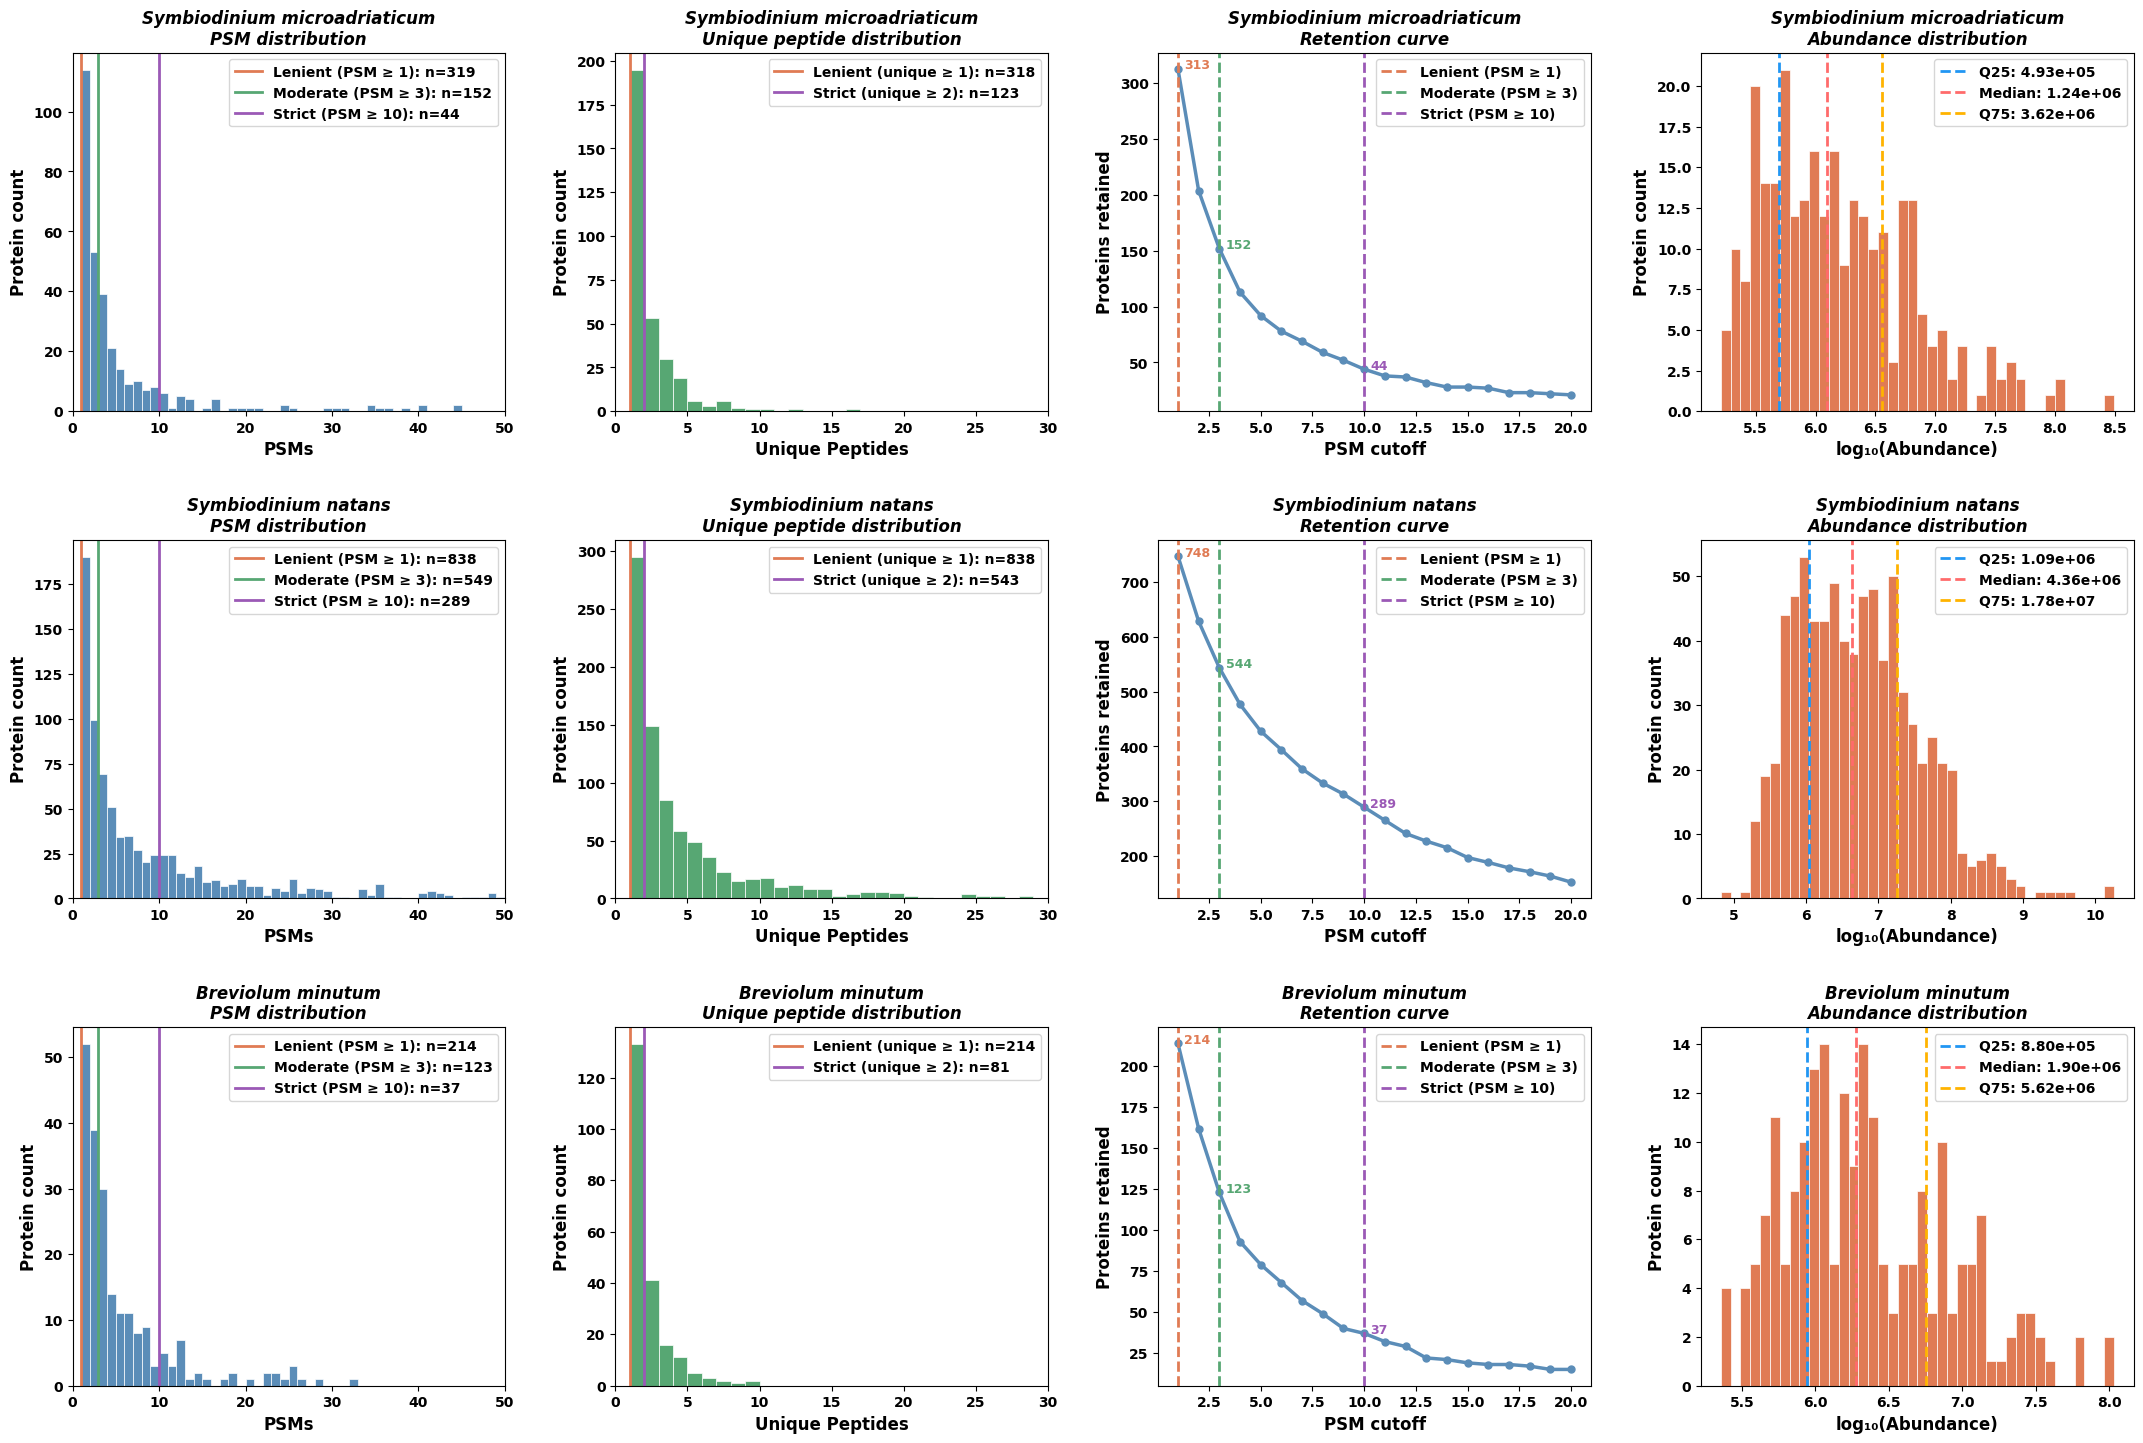

Saved: threshold_diagnostics .png / .svg / .pdf


In [ ]:
# =========================================================
# DIAGNOSTIC: threshold sensitivity — supplementary figure
# 3 strains × 4 panels: PSM dist | Unique peptide dist |
#                        Retention curve | Abundance dist
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

project_path = os.path.join(base, "Prediction_vs_Detection", "MS_data")
outdir = os.path.join(project_path, "*Overlap*")

ms_files = {
    "Smic": os.path.join(outdir, "Smic_MS_mapped.tsv"),
    "Snat": os.path.join(outdir, "Snat_MS_mapped.tsv"),
    "Bmin": os.path.join(outdir, "Bmin_MS_mapped.tsv"),
}

SPECIES_NAMES = {
    "Smic": "Symbiodinium microadriaticum",
    "Snat": "Symbiodinium natans",
    "Bmin": "Breviolum minutum",
}

# Threshold cutoffs to annotate
PSM_CUTOFFS      = [(1, "#E07B54", "Lenient (PSM ≥ 1)"),
                    (3, "#57A773", "Moderate (PSM ≥ 3)"),
                    (10, "#9B59B6", "Strict (PSM ≥ 10)")]
UNIQUE_CUTOFFS   = [(1, "#E07B54", "Lenient (unique ≥ 1)"),
                    (2, "#9B59B6", "Strict (unique ≥ 2)")]
ABUND_QUANTILES  = [(0.25, "#2196F3", "Q25"),
                    (0.50, "#FF6B6B", "Median"),
                    (0.75, "#FFB300", "Q75")]

def choose_abundance_col(df):
    cols = [c for c in df.columns if str(c).startswith("Abundance:")]
    return cols[0] if cols else None

def bold_ax(ax):
    """Make all text elements on an axis bold."""
    for item in ([ax.title, ax.xaxis.label, ax.yaxis.label] +
                 ax.get_xticklabels() + ax.get_yticklabels()):
        item.set_fontweight("bold")
    legend = ax.get_legend()
    if legend:
        for text in legend.get_texts():
            text.set_fontweight("bold")

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.size"]    = 11

fig, axes = plt.subplots(3, 4, figsize=(22, 15))

for row, (strain, path) in enumerate(ms_files.items()):
    df = pd.read_csv(path, sep="\t")

    for c in ["# PSMs", "# Unique Peptides", "Exp. q-value: Combined"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    abund_col = choose_abundance_col(df)
    if abund_col:
        df[abund_col] = pd.to_numeric(df[abund_col], errors="coerce")

    hc = (df["Protein FDR Confidence: Combined"].astype(str).eq("High")
          if "Protein FDR Confidence: Combined" in df.columns
          else pd.Series(True, index=df.index))
    qv = (df["Exp. q-value: Combined"].fillna(np.inf) <= 0.01
          if "Exp. q-value: Combined" in df.columns
          else pd.Series(True, index=df.index))

    # ── Panel 1: PSM distribution ─────────────────────────
    ax = axes[row, 0]
    psm = df["# PSMs"].dropna()
    max_bin = min(int(psm.max()) + 2, 52)
    ax.hist(psm, bins=range(1, max_bin),
            color="#5B8DB8", edgecolor="white", linewidth=0.5)
    for cutoff, col, label in PSM_CUTOFFS:
        n = (psm >= cutoff).sum()
        ax.axvline(cutoff, color=col, linewidth=2,
                   label=f"{label}: n={n:,}")
    ax.set_xlabel("PSMs", fontsize=12, fontweight="bold")
    ax.set_ylabel("Protein count", fontsize=12, fontweight="bold")
    ax.set_title(f"{SPECIES_NAMES[strain]}\nPSM distribution",
                 fontweight="bold", fontsize=12, fontstyle="italic")
    ax.set_xlim(0, 50)
    ax.tick_params(labelsize=10)
    ax.legend(fontsize=10)
    bold_ax(ax)

    # ── Panel 2: Unique peptides distribution ─────────────
    ax = axes[row, 1]
    up = df["# Unique Peptides"].dropna()
    max_bin = min(int(up.max()) + 2, 30)
    ax.hist(up, bins=range(1, max_bin),
            color="#57A773", edgecolor="white", linewidth=0.5)
    for cutoff, col, label in UNIQUE_CUTOFFS:
        n = (up >= cutoff).sum()
        ax.axvline(cutoff, color=col, linewidth=2,
                   label=f"{label}: n={n:,}")
    ax.set_xlabel("Unique Peptides", fontsize=12, fontweight="bold")
    ax.set_ylabel("Protein count", fontsize=12, fontweight="bold")
    ax.set_title(f"{SPECIES_NAMES[strain]}\nUnique peptide distribution",
                 fontweight="bold", fontsize=12, fontstyle="italic")
    ax.set_xlim(0, 30)
    ax.tick_params(labelsize=10)
    ax.legend(fontsize=10)
    bold_ax(ax)

    # ── Panel 3: Retention curve vs PSM cutoff ────────────
    ax = axes[row, 2]
    cutoffs  = range(1, 21)
    retained = []
    for c in cutoffs:
        mask = hc & qv & (df["# PSMs"].fillna(0) >= c)
        retained.append(mask.sum())

    ax.plot(list(cutoffs), retained,
            color="#5B8DB8", linewidth=2.5, marker="o", markersize=5)
    for cutoff, col, label in PSM_CUTOFFS:
        idx = cutoff - 1
        ax.axvline(cutoff, color=col, linewidth=2,
                   linestyle="--", label=label)
        ax.annotate(f"{retained[idx]:,}",
                    xy=(cutoff, retained[idx]),
                    xytext=(cutoff + 0.3, retained[idx]),
                    fontsize=9, color=col, fontweight="bold")
    ax.set_xlabel("PSM cutoff", fontsize=12, fontweight="bold")
    ax.set_ylabel("Proteins retained", fontsize=12, fontweight="bold")
    ax.set_title(f"{SPECIES_NAMES[strain]}\nRetention curve",
                 fontweight="bold", fontsize=12, fontstyle="italic")
    ax.tick_params(labelsize=10)
    ax.legend(fontsize=10)
    bold_ax(ax)

    # ── Panel 4: Abundance distribution ───────────────────
    ax = axes[row, 3]
    if abund_col and df[abund_col].dropna().shape[0] > 0:
        abund = df[abund_col].dropna()
        log_abund = np.log10(abund[abund > 0])

        ax.hist(log_abund, bins=40,
                color="#E07B54", edgecolor="white", linewidth=0.5)

        for q, col, label in ABUND_QUANTILES:
            val     = abund[abund > 0].quantile(q)
            log_val = np.log10(val)
            ax.axvline(log_val, color=col, linewidth=2,
                       linestyle="--",
                       label=f"{label}: {val:.2e}")

        ax.set_xlabel("log₁₀(Abundance)", fontsize=12, fontweight="bold")
        ax.set_ylabel("Protein count",    fontsize=12, fontweight="bold")
        ax.set_title(f"{SPECIES_NAMES[strain]}\nAbundance distribution",
                     fontweight="bold", fontsize=12, fontstyle="italic")
        ax.tick_params(labelsize=10)
        ax.legend(fontsize=10)
        bold_ax(ax)
    else:
        ax.text(0.5, 0.5, "No abundance\ndata available",
                ha="center", va="center", fontsize=12,
                fontweight="bold", transform=ax.transAxes)
        ax.axis("off")

    # Console summary
    print(f"\n{'─'*60}")
    print(f"{SPECIES_NAMES[strain]}")
    print(f"{'─'*60}")
    print(f"{'Threshold':<30} {'Retained':>10}")
    print(f"{'─'*60}")
    for cutoff, _, label in PSM_CUTOFFS:
        mask = hc & qv & (df["# PSMs"].fillna(0) >= cutoff)
        print(f"{label:<30} {mask.sum():>10,}")
    if abund_col:
        abund = df[abund_col].dropna()
        for q, _, label in ABUND_QUANTILES:
            val = abund[abund > 0].quantile(q)
            mask = hc & qv & (df["# PSMs"].fillna(0) >= 10) & \
                   (df["# Unique Peptides"].fillna(0) >= 2) & \
                   (df[abund_col].fillna(-np.inf) >= val)
            print(f"Strict + abund {label:<16} {mask.sum():>10,}")

plt.tight_layout(pad=2.5)

for ext, dpi in [("png", 600), ("svg", None), ("pdf", None)]:
    kw = {"dpi": dpi} if dpi else {}
    plt.savefig(
        os.path.join(outdir, f"threshold_diagnostics.{ext}"),
        bbox_inches="tight", **kw
    )
plt.show()
print("Saved: threshold_diagnostics .png / .svg / .pdf")

In [ ]:
# =============================================================
# BLOCK 2-2: SET THRESHOLDS AND COMPARE DIFFERENT OVERLAPS
# =============================================================

import os
import pandas as pd
import numpy as np

project_path = os.path.join(base, "Prediction_vs_Detection", "MS_data")
outdir = os.path.join(project_path, "*Overlap*")

# =========================
# INPUT OVERLAP FILES
# =========================
MS_MAPPED_FILES = {
    "Smic": os.path.join(outdir, "Smic_MS_mapped.tsv"),
    "Snat": os.path.join(outdir, "Snat_MS_mapped.tsv"),
    "Bmin": os.path.join(outdir, "Bmin_MS_mapped.tsv"),
}

# =========================
# THRESHOLD SETTINGS
# Edit these freely
# =========================
THRESHOLD_SETS = {
    "lenient": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 1,
        "min_unique_peptides": 1,
        "use_abundance": False,
        "abundance_quantile": None,
    },
    "moderate": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 3,
        "min_unique_peptides": 1,
        "use_abundance": False,
        "abundance_quantile": None,
    },
    "strict": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 10,
        "min_unique_peptides": 2,
        "use_abundance": False,
        "abundance_quantile": None,
    },
    "strict_plus_abundance": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 10,
        "min_unique_peptides": 2,
        "use_abundance": True,
        "abundance_quantile": 0.75,   # Q75
    },
}

# =========================
# HELPERS
# =========================
def choose_abundance_col(df):
    abundance_cols = [c for c in df.columns if c.startswith("Abundance:")]
    return abundance_cols[0] if abundance_cols else None


def apply_threshold(df, cfg):
    x = df.copy()

    # numeric conversion
    for c in ["Exp. q-value: Combined", "# PSMs", "# Unique Peptides"]:
        if c in x.columns:
            x[c] = pd.to_numeric(x[c], errors="coerce")

    abundance_col = choose_abundance_col(x)
    if abundance_col is not None:
        x[abundance_col] = pd.to_numeric(x[abundance_col], errors="coerce")

    keep = pd.Series(True, index=x.index)

    if cfg["require_high_confidence"] and "Protein FDR Confidence: Combined" in x.columns:
        keep &= x["Protein FDR Confidence: Combined"].astype(str).eq("High")

    if "Exp. q-value: Combined" in x.columns and cfg["max_qvalue"] is not None:
        keep &= x["Exp. q-value: Combined"].fillna(np.inf) <= cfg["max_qvalue"]

    if "# PSMs" in x.columns and cfg["min_psm"] is not None:
        keep &= x["# PSMs"].fillna(0) >= cfg["min_psm"]

    if "# Unique Peptides" in x.columns and cfg["min_unique_peptides"] is not None:
        keep &= x["# Unique Peptides"].fillna(0) >= cfg["min_unique_peptides"]

    abundance_cutoff = None
    if cfg["use_abundance"] and abundance_col is not None and cfg["abundance_quantile"] is not None:
        abundance_cutoff = x[abundance_col].dropna().quantile(cfg["abundance_quantile"])
        keep &= x[abundance_col].fillna(-np.inf) >= abundance_cutoff

    y = x[keep].copy()
    y["threshold_name"] = [k for k, v in THRESHOLD_SETS.items() if v == cfg][0]

    return y, abundance_col, abundance_cutoff


# =========================
# MAIN
# =========================
OVERLAP_FILES = {
    ("Smic", "pred_sp+"): os.path.join(outdir, "Smic_pred_sp+_MS_vs_prediction_overlap.tsv"),
    ("Smic", "pred_sp-"): os.path.join(outdir, "Smic_pred_sp-_MS_vs_prediction_overlap.tsv"),
    ("Snat", "pred_sp+"): os.path.join(outdir, "Snat_pred_sp+_MS_vs_prediction_overlap.tsv"),
    ("Snat", "pred_sp-"): os.path.join(outdir, "Snat_pred_sp-_MS_vs_prediction_overlap.tsv"),
    ("Bmin", "pred_sp+"): os.path.join(outdir, "Bmin_pred_sp+_MS_vs_prediction_overlap.tsv"),
    ("Bmin", "pred_sp-"): os.path.join(outdir, "Bmin_pred_sp-_MS_vs_prediction_overlap.tsv"),
}

summary_rows = []

for strain, ms_path in MS_MAPPED_FILES.items():
    # Load the FULL MS table — quantile computed here
    ms_df = pd.read_csv(ms_path, sep="\t")

    for sec_type in ["pred_sp+", "pred_sp-"]:
        # Get the seq_hashes that are in the SP overlap
        overlap_df = pd.read_csv(OVERLAP_FILES[(strain, sec_type)], sep="\t")
        overlap_hashes = set(overlap_df["seq_hash"].dropna().astype(str))
        total_overlap = len(overlap_hashes)

        print(f"\n{'='*70}")
        print(f"{strain} | {sec_type}  —  original overlap: {total_overlap}")
        print(f"{'='*70}")

        for thresh_name, cfg in THRESHOLD_SETS.items():
            # Apply threshold to FULL MS table (same population as Block 4-2)
            filtered, abundance_col, abundance_cutoff = apply_threshold(ms_df, cfg)
            passed_hashes = set(filtered["seq_hash"].dropna().astype(str))

            # Intersect with the SP overlap hashes
            final_hashes = overlap_hashes & passed_hashes
            final_df = overlap_df[overlap_df["seq_hash"].isin(final_hashes)].copy()
            final_df["threshold_name"] = thresh_name

            out_file = os.path.join(outdir,
                f"{strain}_{sec_type}_overlap_{thresh_name}.tsv")
            final_df.to_csv(out_file, sep="\t", index=False)

            summary_rows.append({
                "strain":              strain,
                "secretome_type":        sec_type,
                "threshold_name":        thresh_name,
                "overlap_before_filter": total_overlap,
                "overlap_after_filter":  len(final_df),
                "retained_pct":          round(len(final_df) / total_overlap * 100, 2)
                                         if total_overlap else 0,
                "abundance_column":      abundance_col,
                "abundance_cutoff":      abundance_cutoff,
                "max_qvalue":            cfg["max_qvalue"],
                "min_psm":               cfg["min_psm"],
                "min_unique_peptides":   cfg["min_unique_peptides"],
            })

            print(f"  {thresh_name}: {len(final_df)} retained")

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(
    os.path.join(outdir, "overlap_threshold_comparison_summary.tsv"),
    sep="\t", index=False)
print("\nSaved summary.")
print(summary_df)


Smic | pred_sp+  —  original overlap: 2
  lenient: 2 retained
  moderate: 1 retained
  strict: 1 retained
  strict_plus_abundance: 0 retained

Smic | pred_sp-  —  original overlap: 2
  lenient: 1 retained
  moderate: 0 retained
  strict: 0 retained
  strict_plus_abundance: 0 retained

Snat | pred_sp+  —  original overlap: 87
  lenient: 81 retained
  moderate: 61 retained
  strict: 28 retained
  strict_plus_abundance: 18 retained

Snat | pred_sp-  —  original overlap: 23
  lenient: 20 retained
  moderate: 14 retained
  strict: 8 retained
  strict_plus_abundance: 5 retained

Bmin | pred_sp+  —  original overlap: 10
  lenient: 10 retained
  moderate: 7 retained
  strict: 1 retained
  strict_plus_abundance: 1 retained

Bmin | pred_sp-  —  original overlap: 2
  lenient: 2 retained
  moderate: 1 retained
  strict: 0 retained
  strict_plus_abundance: 0 retained

Saved summary.
   strain secretome_type         threshold_name  overlap_before_filter  \
0    Smic       pred_sp+                le

# Block 3 - Proteins shared by all strains

In [ ]:
# ===================================================================
# BLOCK 3: SHARED OVERLAP SEQUENCES ACROSS ALL THREE STRAINS
# ===================================================================

import os
import pandas as pd

# =========================
# PATHS
# =========================

project_path = os.path.join(base, "MS_data")
outdir = os.path.join(project_path, "*Overlap*")

strains = ["Smic", "Snat", "Bmin"]
secretome_types = ["pred_sp+", "pred_sp-"]

# =========================================================
# PART 1: COMMON OVERLAP SEQUENCES WITHIN EACH SECRETOME TYPE
# =========================================================
summary_rows = []

for sec_type in secretome_types:
    dfs = {}
    seq_sets = {}

    print("\n" + "=" * 70)
    print(f"SECRETOME TYPE: {sec_type}")
    print("=" * 70)

    for strain in strains:
        f = os.path.join(outdir, f"{strain}_{sec_type}_MS_vs_prediction_overlap.tsv")
        df = pd.read_csv(f, sep="\t")
        dfs[strain] = df
        seq_sets[strain] = set(df["seq_hash"].dropna().astype(str))

        print(f"{strain}: {len(seq_sets[strain]):,} overlap sequences")

    shared_hashes = set.intersection(*seq_sets.values())
    print(f"Shared overlap sequences across all 3 strains ({sec_type}): {len(shared_hashes):,}")

    shared_rows = []
    for strain in strains:
        sub = dfs[strain][dfs[strain]["seq_hash"].isin(shared_hashes)].copy()
        sub["shared_scope"] = f"all3_{sec_type}"
        shared_rows.append(sub)

    shared_df = pd.concat(shared_rows, ignore_index=True)
    shared_file = os.path.join(outdir, f"ALL3_shared_overlap_sequences_{sec_type}.tsv")
    shared_df.to_csv(shared_file, sep="\t", index=False)

    print(f"Saved: {shared_file}")

    summary_rows.append({
        "secretome_type": sec_type,
        "shared_overlap_sequences_all3": len(shared_hashes)
    })

# =========================================================
# PART 2: COMMON OVERLAP SEQUENCES ACROSS ALL OVERLAPS COMBINED
# (pred_sp+ and pred_sp- pooled within each strain)
# =========================================================
print("\n" + "=" * 70)
print("POOLED OVERLAPS: pred_sp+ and pred_sp- combined")
print("=" * 70)

dfs_all = {}
seq_sets_all = {}

for strain in strains:
    frames = []
    for sec_type in secretome_types:
        f = os.path.join(outdir, f"{strain}_{sec_type}_MS_vs_prediction_overlap.tsv")
        df = pd.read_csv(f, sep="\t")
        df["source_secretome_type"] = sec_type
        frames.append(df)

    pooled = pd.concat(frames, ignore_index=True).drop_duplicates(subset=["seq_hash", "pred_id", "ms_id_raw"])
    dfs_all[strain] = pooled
    seq_sets_all[strain] = set(pooled["seq_hash"].dropna().astype(str))

    print(f"{strain}: {len(seq_sets_all[strain]):,} pooled overlap sequences")

shared_hashes_all = set.intersection(*seq_sets_all.values())
print(f"Shared pooled overlap sequences across all 3 strains: {len(shared_hashes_all):,}")

shared_rows_all = []
for strain in strains:
    sub = dfs_all[strain][dfs_all[strain]["seq_hash"].isin(shared_hashes_all)].copy()
    sub["shared_scope"] = "all3_pooled"
    shared_rows_all.append(sub)

shared_df_all = pd.concat(shared_rows_all, ignore_index=True)
shared_file_all = os.path.join(outdir, "ALL3_shared_overlap_sequences_pooled.tsv")
shared_df_all.to_csv(shared_file_all, sep="\t", index=False)

print(f"Saved: {shared_file_all}")

# =========================================================
# PART 3: SUMMARY
# =========================================================
summary_rows.append({
    "secretome_type": "pooled",
    "shared_overlap_sequences_all3": len(shared_hashes_all)
})

summary_df = pd.DataFrame(summary_rows)
summary_file = os.path.join(outdir, "ALL3_shared_overlap_sequences_summary.tsv")
summary_df.to_csv(summary_file, sep="\t", index=False)

print("\nSummary:")
print(summary_df)
print(f"Saved: {summary_file}")


SECRETOME TYPE: pred_sp+
Smic: 2 overlap sequences
Snat: 87 overlap sequences
Bmin: 10 overlap sequences
Shared overlap sequences across all 3 strains (pred_sp+): 0
Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/ALL3_shared_overlap_sequences_pred_sp+.tsv

SECRETOME TYPE: pred_sp-
Smic: 2 overlap sequences
Snat: 23 overlap sequences
Bmin: 2 overlap sequences
Shared overlap sequences across all 3 strains (pred_sp-): 0
Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/ALL3_shared_overlap_sequences_pred_sp-.tsv

POOLED OVERLAPS: pred_sp+ and pred_sp- combined
Smic: 4 pooled overlap sequences
Snat: 110 pooled overlap sequences
Bmin: 12 pooled overlap sequences
Shared pooled overlap sequences across all 3 strains: 0
Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/ALL3_shared_overlap_sequences_pooled.tsv

Summary:
  secretome_type  shared_overlap_sequences_all3
0       pred_

# Block 4 - Venn diagram

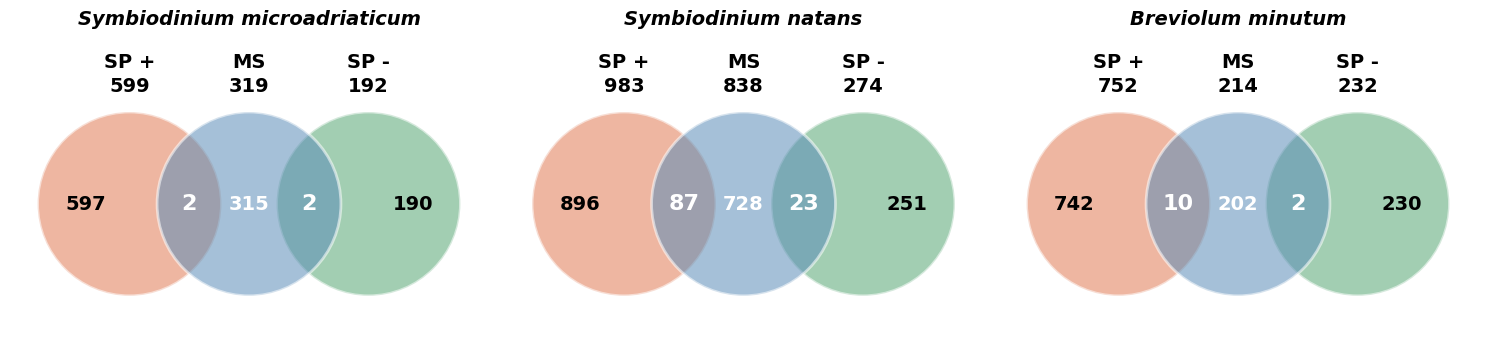

Done.


In [ ]:
# =========================================================
# BLOCK: 4-1 overall panels × 3 strains
# Chain layout: SP+ (left) — MS (centre) — SP- (right)
# =========================================================

import os, re, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

project_path = os.path.join(base, "MS_data")
outdir = os.path.join(project_path, "*Overlap*")
os.makedirs(outdir, exist_ok=True)

DATASETS = [
    {"strain": "Smic",
     "mapped_ms_table": os.path.join(outdir, "Smic_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(base, "Smic_jgi", "09_final", "Smic_jgi_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(base, "Smic_jgi", "09_final", "Smic_jgi_SP_neg_secretome_final.faa")},
    {"strain": "Snat",
     "mapped_ms_table": os.path.join(outdir, "Snat_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(base, "Snat", "09_final", "Snat_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(base, "Snat", "09_final", "Snat_SP_neg_secretome_final.faa")},
    {"strain": "Bmin",
     "mapped_ms_table": os.path.join(outdir, "Bmin_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(base, "Bmin", "09_final", "Bmin_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(base, "Bmin", "09_final", "Bmin_SP_neg_secretome_final.faa")},
]
SPECIES_NAMES = {
    "Smic": "Symbiodinium microadriaticum",
    "Snat": "Symbiodinium natans",
    "Bmin": "Breviolum minutum",
}
C_SP_PLUS  = "#E07B54"
C_MS     = "#5B8DB8"
C_SP_MINUS = "#57A773"

def _clean(seq):
    if pd.isna(seq): return None
    return re.sub(r"\s+", "", str(seq).strip().upper().replace("*", ""))

def _hash(seq):
    s = _clean(seq)
    return hashlib.md5(s.encode()).hexdigest() if s else None

def read_fasta_hashes(path):
    seqs, cur, buf = [], None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line: continue
            if line.startswith(">"):
                if cur is not None: seqs.append("".join(buf))
                cur, buf = line[1:].split()[0], []
            else:
                buf.append(line)
    if cur is not None: seqs.append("".join(buf))
    return {_hash(s) for s in seqs if _hash(s)}

def get_ms_hashes(path):
    df = pd.read_csv(path, sep="\t")
    return set(df["seq_hash"].dropna().astype(str))

def draw_chain_venn(ax, A, B, C, title):
    """
    Draw SP+(A) — MS(B) — SP-(C) as three equal overlapping circles
    in a horizontal chain. A and C do not overlap.
    """
    R   = 1.0    # circle radius (equal for all)
    sep = 1.3    # centre-to-centre distance (< 2R → overlap exists)

    cx_A, cx_B, cx_C = -sep, 0.0, sep
    cy = 0.0

    # ── Circles (draw order: A, C, B so MS sits on top at edges) ──
    for cx, col in [(cx_A, C_SP_PLUS), (cx_C, C_SP_MINUS), (cx_B, C_MS)]:
        ax.add_patch(mpatches.Circle(
            (cx, cy), R,
            facecolor=col, edgecolor="white",
            linewidth=2.0, alpha=0.55, zorder=2
        ))

    # ── Counts ────────────────────────────────────────────────────
    n_A_only = len(A - B - C)
    n_B_only = len(B - A - C)
    n_C_only = len(C - A - B)
    n_AB     = len(A & B)      # SP+ ∩ MS  (no triple possible)
    n_BC     = len(B & C)      # MS  ∩ SP-

    # ── Set labels + totals above each circle ─────────────────────
    for cx, name, n in [(cx_A, "SP +", len(A)),
                        (cx_B, "MS",  len(B)),
                        (cx_C, "SP -", len(C))]:
        ax.text(cx, cy + R + 0.18, f"{name}\n{n:,}",
                ha="center", va="bottom",
                fontsize=14, fontweight="bold", linespacing=1.3)

    # ── Region counts ─────────────────────────────────────────────
    # Exclusive regions — nudged toward outer arc
    ax.text(cx_A - R * 0.48, cy, f"{n_A_only:,}",
            ha="center", va="center", fontsize=14, fontweight="bold", zorder=5)
    ax.text(cx_B,             cy, f"{n_B_only:,}",
            ha="center", va="center", fontsize=14, fontweight="bold",
            color="white", zorder=5)
    ax.text(cx_C + R * 0.48, cy, f"{n_C_only:,}",
            ha="center", va="center", fontsize=14, fontweight="bold", zorder=5)

    # Intersection regions — midpoint between centres
    ax.text((cx_A + cx_B) / 2, cy, f"{n_AB:,}",
            ha="center", va="center", fontsize=16, fontweight="bold",
            color="white", zorder=5)
    ax.text((cx_B + cx_C) / 2, cy, f"{n_BC:,}",
            ha="center", va="center", fontsize=16, fontweight="bold",
            color="white", zorder=5)

    ax.set_xlim(-2.6, 2.6)
    ax.set_ylim(-1.6, 1.8)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontstyle="italic", fontweight="bold",
                 fontsize=14, pad=10)

# ── Main ──────────────────────────────────────────────────────────
plt.rcParams["svg.fonttype"] = "none"
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
summary_rows = []

for ax, ds in zip(axes, DATASETS):
    strain = ds["strain"]
    A = read_fasta_hashes(ds["sp_plus_fasta"])
    B = get_ms_hashes(ds["mapped_ms_table"])
    C = read_fasta_hashes(ds["sp_minus_fasta"])

    draw_chain_venn(ax, A, B, C, SPECIES_NAMES[strain])

    summary_rows.append({
        "strain": strain,
        "SP +": len(A), "MS": len(B), "SP -": len(C),
        "SP+_only": len(A - B - C),
        "MS_only":  len(B - A - C),
        "SP-_only": len(C - A - B),
        "SP+_MS":   len(A & B),
        "MS_SP-":   len(B & C),
    })

plt.tight_layout()

for ext, dpi in [("png", 600), ("svg", None), ("pdf", None)]:
    kw = {"dpi": dpi} if dpi else {}
    plt.savefig(os.path.join(outdir, f"predict_vs_detect_venn3.{ext}"),
                bbox_inches="tight", **kw)
plt.show()

pd.DataFrame(summary_rows).to_csv(
    os.path.join(outdir, "predict_vs_detect_venn3_summary.tsv"),
    sep="\t", index=False)
print("Done.")

Smic:  SP+=599  MS=319  SP-=192
Snat:  SP+=983  MS=838  SP-=274
Bmin:  SP+=752  MS=214  SP-=232


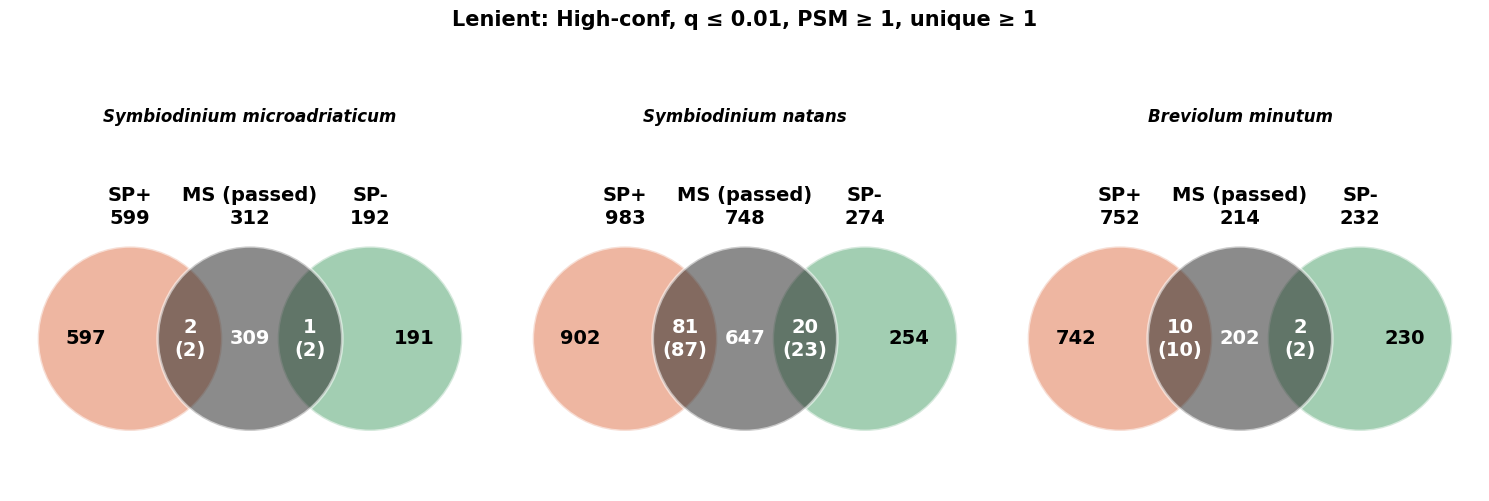

Saved: threshold_lenient


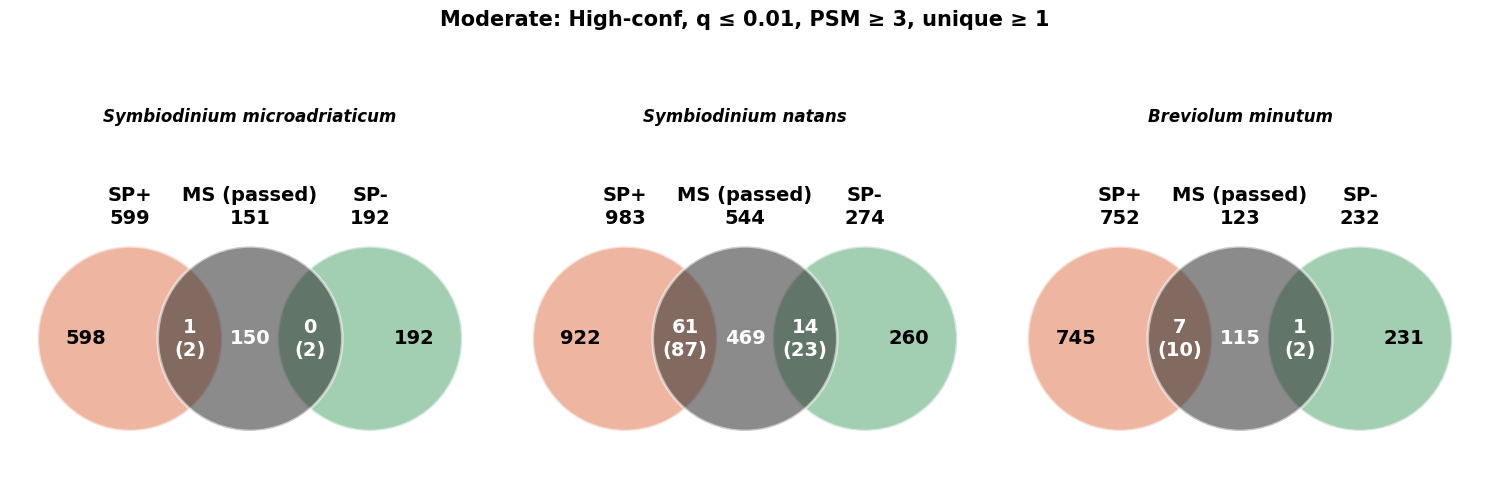

Saved: threshold_moderate


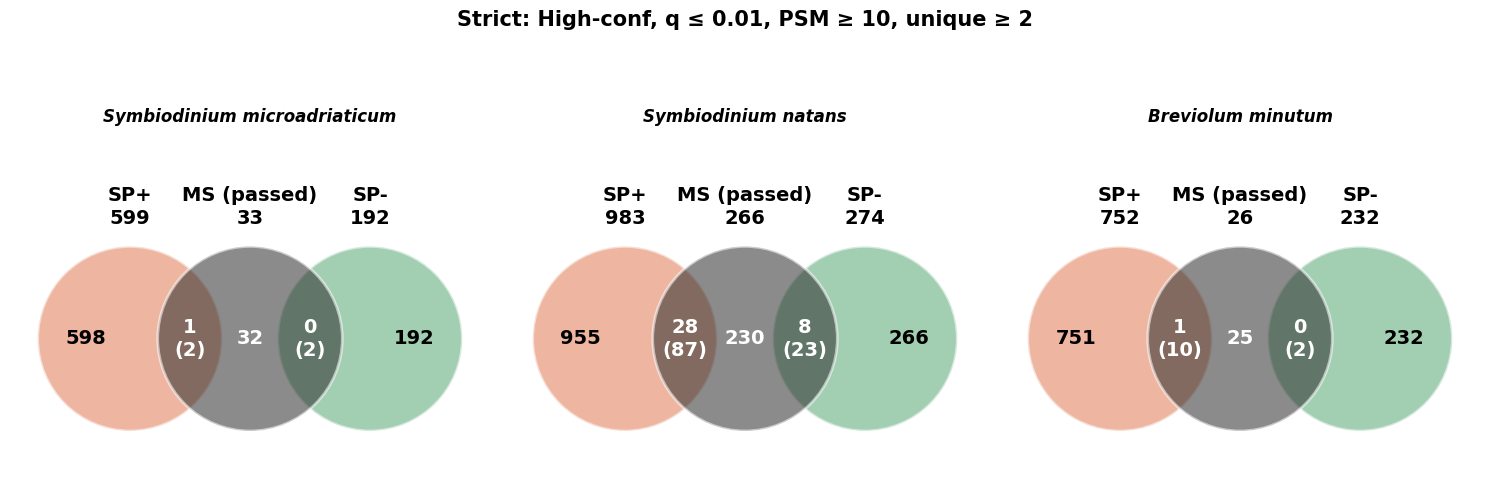

Saved: threshold_strict


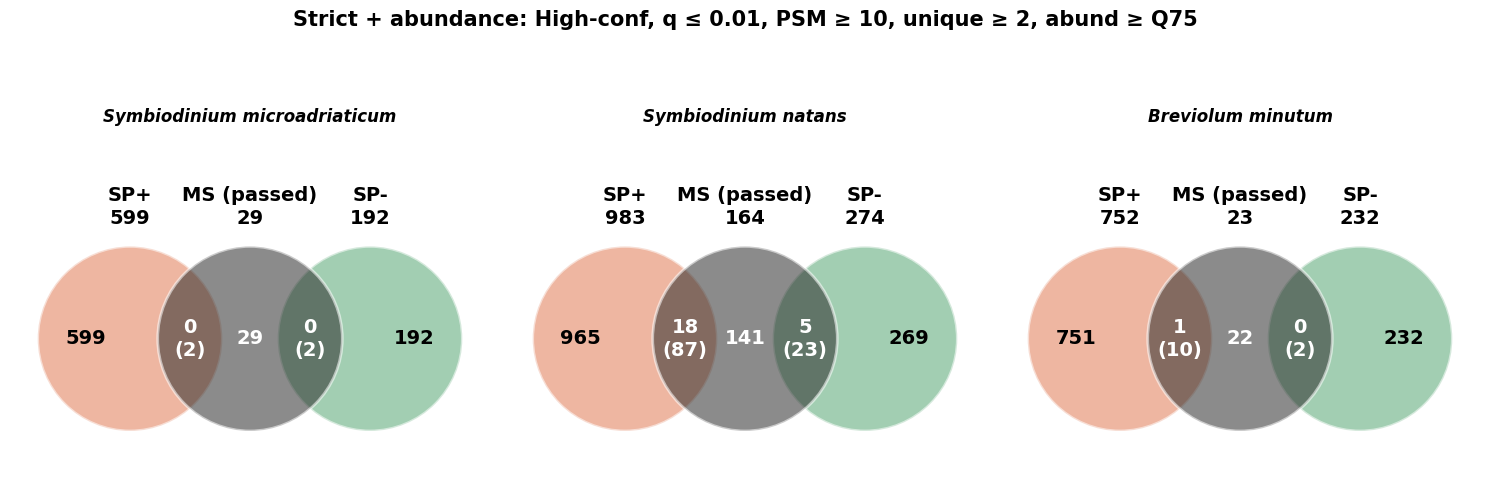

Saved: threshold_strict_plus_abundance
Done.


In [ ]:
# =========================================================
# BLOCK 4-2: threshold figures — one figure per threshold
# Each figure: 1 × 3 panels (one per strain)
# Figure size matches the overall overlap figure (15 × 5.5)
# =========================================================

import os, re, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.font_manager import FontProperties

project_path = os.path.join(base, "Prediction_vs_Detection")
outdir = os.path.join(project_path, "MS_data", "*Overlap*")
os.makedirs(outdir, exist_ok=True)

DATASETS = [
    {"strain": "Smic",
     "mapped_ms_table": os.path.join(outdir, "Smic_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(project_path, "Smic_jgi", "09_final", "Smic_jgi_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(project_path, "Smic_jgi", "09_final", "Smic_jgi_SP_neg_secretome_final.faa")},
    {"strain": "Snat",
     "mapped_ms_table": os.path.join(outdir, "Snat_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(project_path, "Snat", "09_final", "Snat_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(project_path, "Snat", "09_final", "Snat_SP_neg_secretome_final.faa")},
    {"strain": "Bmin",
     "mapped_ms_table": os.path.join(outdir, "Bmin_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(project_path, "Bmin", "09_final", "Bmin_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(project_path, "Bmin", "09_final", "Bmin_SP_neg_secretome_final.faa")},
]

THRESHOLD_SETS = {
    "lenient": {
        "require_high_confidence": True, "max_qvalue": 0.01,
        "min_psm": 1, "min_unique_peptides": 1,
        "use_abundance": False, "abundance_quantile": None,
    },
    "moderate": {
        "require_high_confidence": True, "max_qvalue": 0.01,
        "min_psm": 3, "min_unique_peptides": 1,
        "use_abundance": False, "abundance_quantile": None,
    },
    "strict": {
        "require_high_confidence": True, "max_qvalue": 0.01,
        "min_psm": 10, "min_unique_peptides": 2,
        "use_abundance": False, "abundance_quantile": None,
    },
    "strict_plus_abundance": {
        "require_high_confidence": True, "max_qvalue": 0.01,
        "min_psm": 10, "min_unique_peptides": 2,
        "use_abundance": True, "abundance_quantile": 0.75,
    },
}
THRESHOLD_ORDER = ["lenient", "moderate", "strict", "strict_plus_abundance"]

THRESHOLD_LABEL = {
    "lenient":               "Lenient: High-conf, q ≤ 0.01, PSM ≥ 1, unique ≥ 1",
    "moderate":              "Moderate: High-conf, q ≤ 0.01, PSM ≥ 3, unique ≥ 1",
    "strict":                "Strict: High-conf, q ≤ 0.01, PSM ≥ 10, unique ≥ 2",
    "strict_plus_abundance": "Strict + abundance: High-conf, q ≤ 0.01, PSM ≥ 10, unique ≥ 2, abund ≥ Q75",
}

SPECIES_NAMES = {
    "Smic": "Symbiodinium microadriaticum",
    "Snat": "Symbiodinium natans",
    "Bmin": "Breviolum minutum",
}

C_SP_PLUS  = "#E07B54"
C_MS_PASS  = "#2C2C2C"
C_SP_MINUS = "#57A773"

plt.rcParams["svg.fonttype"] = "none"

# ── Helpers ───────────────────────────────────────────────
def _clean(seq):
    if pd.isna(seq): return None
    return re.sub(r"\s+", "", str(seq).strip().upper().replace("*", ""))

def _hash(seq):
    s = _clean(seq)
    return hashlib.md5(s.encode()).hexdigest() if s else None

def read_fasta_hashes(path):
    seqs, cur, buf = [], None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line: continue
            if line.startswith(">"):
                if cur is not None: seqs.append("".join(buf))
                cur, buf = line[1:].split()[0], []
            else:
                buf.append(line)
    if cur is not None: seqs.append("".join(buf))
    return {_hash(s) for s in seqs if _hash(s)}

def get_ms_df(path):
    df = pd.read_csv(path, sep="\t")
    if "seq_hash" not in df.columns:
        raise ValueError(f"'seq_hash' not found in {path}")
    return df

def choose_abundance_col(df):
    cols = [c for c in df.columns if str(c).startswith("Abundance:")]
    return cols[0] if cols else None

def apply_threshold(df, cfg):
    x = df.copy()
    for c in ["Exp. q-value: Combined", "# PSMs", "# Unique Peptides"]:
        if c in x.columns:
            x[c] = pd.to_numeric(x[c], errors="coerce")
    abund_col = choose_abundance_col(x)
    if abund_col:
        x[abund_col] = pd.to_numeric(x[abund_col], errors="coerce")

    keep = pd.Series(True, index=x.index)
    if cfg["require_high_confidence"] and "Protein FDR Confidence: Combined" in x.columns:
        keep &= x["Protein FDR Confidence: Combined"].astype(str).eq("High")
    if "Exp. q-value: Combined" in x.columns:
        keep &= x["Exp. q-value: Combined"].fillna(np.inf) <= cfg["max_qvalue"]
    if "# PSMs" in x.columns:
        keep &= x["# PSMs"].fillna(0) >= cfg["min_psm"]
    if "# Unique Peptides" in x.columns:
        keep &= x["# Unique Peptides"].fillna(0) >= cfg["min_unique_peptides"]
    if cfg["use_abundance"] and abund_col and cfg["abundance_quantile"] is not None:
        cutoff = x[abund_col].dropna().quantile(cfg["abundance_quantile"])
        keep &= x[abund_col].fillna(-np.inf) >= cutoff

    return set(x.loc[keep, "seq_hash"].dropna().astype(str))

# ── Panel drawing (species name only — no threshold in title) ──
def draw_panel(ax, strain, sp_plus, ms_all, ms_passed, sp_minus):
    R   = 1.0
    sep = 1.30
    cx_sp, cx_ms, cx_spm, cy = -sep, 0.0, sep, 0.0

    for cx, col in [(cx_sp,  C_SP_PLUS),
                    (cx_spm, C_SP_MINUS),
                    (cx_ms,  C_MS_PASS)]:
        ax.add_patch(Circle((cx, cy), R,
                            facecolor=col, edgecolor="white",
                            linewidth=2.0, alpha=0.55, zorder=2))

    sp_ms_passed  = sp_plus  & ms_passed
    spm_ms_passed = sp_minus & ms_passed
    sp_ms_all     = sp_plus  & ms_all
    spm_ms_all    = sp_minus & ms_all

    n_sp_only  = len(sp_plus   - ms_passed)
    n_ms_only  = len(ms_passed - sp_plus - sp_minus)
    n_spm_only = len(sp_minus  - ms_passed)

    # Labels above circles
    for cx, name, n in [(cx_sp,  "SP+",       len(sp_plus)),
                        (cx_ms,  "MS (passed)", len(ms_passed)),
                        (cx_spm, "SP-",       len(sp_minus))]:
        ax.text(cx, cy + R + 0.20, f"{name}\n{n:,}",
                ha="center", va="bottom", fontsize=14,
                fontweight="bold", linespacing=1.3, zorder=6)

    # Exclusive counts
    ax.text(cx_sp  - R * 0.48, cy, f"{n_sp_only:,}",
            ha="center", va="center", fontsize=14,
            fontweight="bold", zorder=6)
    ax.text(cx_ms,              cy, f"{n_ms_only:,}",
            ha="center", va="center", fontsize=14,
            fontweight="bold", color="white", zorder=6)
    ax.text(cx_spm + R * 0.48, cy, f"{n_spm_only:,}",
            ha="center", va="center", fontsize=14,
            fontweight="bold", zorder=6)

    # Overlap counts: passed (overall)
    ax.text((cx_sp + cx_ms)  / 2, cy,
            f"{len(sp_ms_passed):,}\n({len(sp_ms_all):,})",
            ha="center", va="center", fontsize=14,
            fontweight="bold", color="white",
            linespacing=1.3, zorder=6)
    ax.text((cx_ms + cx_spm) / 2, cy,
            f"{len(spm_ms_passed):,}\n({len(spm_ms_all):,})",
            ha="center", va="center", fontsize=14,
            fontweight="bold", color="white",
            linespacing=1.3, zorder=6)

    ax.set_xlim(-2.6, 2.6)
    ax.set_ylim(-1.65, 2.20)
    ax.set_aspect("equal")
    ax.axis("off")

    # Species name only — italic, no threshold text
    ax.set_title(SPECIES_NAMES[strain],
                 fontstyle="italic", fontweight="bold",
                 fontsize=12, pad=10)

# ── Precompute ────────────────────────────────────────────
records = []
for ds in DATASETS:
    strain   = ds["strain"]
    sp_plus  = read_fasta_hashes(ds["sp_plus_fasta"])
    sp_minus = read_fasta_hashes(ds["sp_minus_fasta"])
    ms_df    = get_ms_df(ds["mapped_ms_table"])
    ms_all   = set(ms_df["seq_hash"].dropna().astype(str))

    records.append({
        "strain":        strain,
        "sp_plus":       sp_plus,
        "sp_minus":      sp_minus,
        "ms_all":        ms_all,
        "ms_df":         ms_df,
        "passed_by_thr": {thr: apply_threshold(ms_df, THRESHOLD_SETS[thr])
                          for thr in THRESHOLD_ORDER},
    })
    print(f"{strain}:  SP+={len(sp_plus):,}  MS={len(ms_all):,}  SP-={len(sp_minus):,}")

# ── One figure per threshold ──────────────────────────────
summary_rows = []

for thr in THRESHOLD_ORDER:

    # Same size as overall overlap figure
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))

    # Threshold label once at the top of the figure
    fig.suptitle(THRESHOLD_LABEL[thr],
                 fontsize=15, fontweight="bold", y=1.02)

    for ax, rec in zip(axes, records):
        ms_passed = rec["passed_by_thr"][thr]

        draw_panel(ax, rec["strain"],
                   rec["sp_plus"], rec["ms_all"],
                   ms_passed, rec["sp_minus"])

        summary_rows.append({
            "threshold":     thr,
            "strain":        rec["strain"],
            "SP+":           len(rec["sp_plus"]),
            "MS_all":        len(rec["ms_all"]),
            "MS_passed":     len(ms_passed),
            "SP-":           len(rec["sp_minus"]),
            "SP+∩MS_passed": len(rec["sp_plus"]  & ms_passed),
            "SP+∩MS_all":    len(rec["sp_plus"]  & rec["ms_all"]),
            "SP-∩MS_passed": len(rec["sp_minus"] & ms_passed),
            "SP-∩MS_all":    len(rec["sp_minus"] & rec["ms_all"]),
        })

    plt.tight_layout()

    for ext, dpi in [("png", 600), ("svg", None), ("pdf", None)]:
        kw = {"dpi": dpi} if dpi else {}
        plt.savefig(
            os.path.join(outdir, f"threshold_{thr}.{ext}"),
            bbox_inches="tight", **kw
        )
    plt.show()
    print(f"Saved: threshold_{thr}")

# ── Summary table ─────────────────────────────────────────
pd.DataFrame(summary_rows).to_csv(
    os.path.join(outdir, "threshold_summary.tsv"),
    sep="\t", index=False)
print("Done.")

# (Alternative) UpSet plot for overlap

/tmp/ipykernel_3535/3166537435.py:225: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


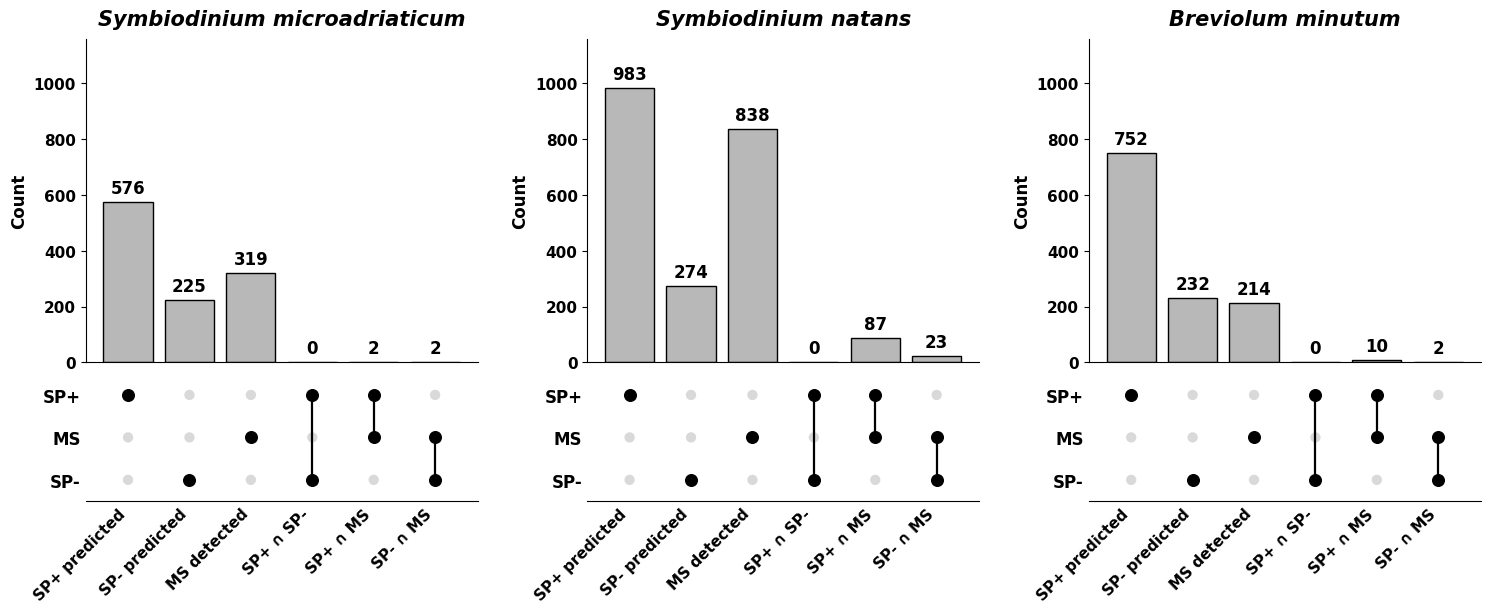

Saved:
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/predict_vs_detect_upset_style.png
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/predict_vs_detect_upset_style.svg
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/predict_vs_detect_upset_style.pdf
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/predict_vs_detect_upset_style_summary.tsv


In [ ]:
# =========================================================
# BLOCK: UPSET-STYLE EXACT INTERSECTION PLOT
# 3 panels: Smic / Snat / Bmin
# Sets: SP+, MS, SP-
# Exact sequence-based intersections
# Same y-axis range across panels
# =========================================================

import os
import re
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.font_manager import FontProperties

# =========================
# PATHS
# =========================
project_path = os.path.join(base, "MS_data")
outdir = os.path.join(project_path, "*Overlap*")
os.makedirs(outdir, exist_ok=True)

DATASETS = [
    {
        "strain": "Smic",
        "mapped_ms_table": os.path.join(outdir, "Smic_MS_mapped.tsv"),
        "sp_plus_fasta":   os.path.join(base, "Smic", "09_final", "Smic_SP_pos_secretome_final.faa"),
        "sp_minus_fasta":  os.path.join(base, "Smic", "09_final", "Smic_SP_neg_secretome_final.faa"),
    },
    {
        "strain": "Snat",
        "mapped_ms_table": os.path.join(outdir, "Snat_MS_mapped.tsv"),
        "sp_plus_fasta":   os.path.join(base, "Snat", "09_final", "Snat_SP_pos_secretome_final.faa"),
        "sp_minus_fasta":  os.path.join(base, "Snat", "09_final", "Snat_SP_neg_secretome_final.faa"),
    },
    {
        "strain": "Bmin",
        "mapped_ms_table": os.path.join(outdir, "Bmin_MS_mapped.tsv"),
        "sp_plus_fasta":   os.path.join(base, "Bmin", "09_final", "Bmin_SP_pos_secretome_final.faa"),
        "sp_minus_fasta":  os.path.join(base, "Bmin", "09_final", "Bmin_SP_neg_secretome_final.faa"),
    },
]

SPECIES_NAMES = {
    "Smic": "Symbiodinium microadriaticum",
    "Snat": "Symbiodinium natans",
    "Bmin": "Breviolum minutum",
}

# =========================
# STYLE
# =========================
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.size"] = 12

title_fp = FontProperties(style="italic", weight="bold", size=15)
label_fs = 12
num_fs = 16
tick_fs = 11

bar_color = "#B8B8B8"
dot_color = "black"
line_color = "black"
guide_dot_color = "#D9D9D9"

# =========================
# HELPERS
# =========================
def _clean(seq):
    if pd.isna(seq):
        return None
    return re.sub(r"\s+", "", str(seq).strip().upper().replace("*", ""))

def _hash(seq):
    s = _clean(seq)
    return hashlib.md5(s.encode()).hexdigest() if s else None

def read_fasta_hashes(path):
    seqs, cur, buf = [], None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if cur is not None:
                    seqs.append("".join(buf))
                cur, buf = line[1:].split()[0], []
            else:
                buf.append(line)
    if cur is not None:
        seqs.append("".join(buf))
    return {_hash(s) for s in seqs if _hash(s)}

def get_ms_hashes(path):
    df = pd.read_csv(path, sep="\t")
    return set(df["seq_hash"].dropna().astype(str))

def compute_exact_intersections(sp_plus, ms, sp_minus):
    """
    Returns exact intersections in user-requested x-axis order:
      SP+ predicted
      SP- predicted
      MS detected
      SP+ ∩ SP-
      SP+ ∩ MS
      SP- ∩ MS
    """
    combos = [
        ("SP+ predicted", (1, 0, 0), len(sp_plus)),
        ("SP- predicted", (0, 0, 1), len(sp_minus)),
        ("MS detected",   (0, 1, 0), len(ms)),
        ("SP+ ∩ SP-",     (1, 0, 1), len(sp_plus & sp_minus)),
        ("SP+ ∩ MS",      (1, 1, 0), len(sp_plus & ms)),
        ("SP- ∩ MS",      (0, 1, 1), len(ms & sp_minus)),
    ]
    return combos

def draw_upset_panel(fig, outer_spec, title, combos, ymax):
    inner = gridspec.GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer_spec,
        height_ratios=[3.3, 1.3], hspace=0.05
    )

    ax_bar = fig.add_subplot(inner[0])
    ax_mat = fig.add_subplot(inner[1], sharex=ax_bar)

    labels = [x[0] for x in combos]
    memberships = [x[1] for x in combos]
    counts = [x[2] for x in combos]
    x = list(range(len(combos)))

    # ---- bar plot ----
    ax_bar.bar(x, counts, color=bar_color, edgecolor="black", linewidth=1.0)
    for xi, c in zip(x, counts):
        ax_bar.text(
            xi,
            c + max(0.5, ymax * 0.015),
            str(c),
            ha="center",
            va="bottom",
            fontsize=num_fs - 4,
            fontweight="bold"
        )

    ax_bar.set_title(title, fontproperties=title_fp, pad=10)
    ax_bar.set_ylabel("Count", fontsize=label_fs, fontweight="bold")
    ax_bar.set_ylim(0, ymax)
    ax_bar.spines["top"].set_visible(False)
    ax_bar.spines["right"].set_visible(False)
    ax_bar.tick_params(axis="y", labelsize=tick_fs)
    for lbl in ax_bar.get_yticklabels():
        lbl.set_fontweight("bold")
    ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)

    # ---- matrix ----
    rows = ["SP+", "MS", "SP-"]
    y_pos = [2, 1, 0]

    for xi in x:
        for yy in y_pos:
            ax_mat.scatter(xi, yy, s=55, facecolor=guide_dot_color, edgecolor="none", zorder=1)

    for xi, member in zip(x, memberships):
        active_y = []
        for present, yy in zip(member, y_pos):
            if present:
                ax_mat.scatter(xi, yy, s=70, facecolor=dot_color, edgecolor="black", zorder=3)
                active_y.append(yy)
        if len(active_y) >= 2:
            ax_mat.plot([xi, xi], [min(active_y), max(active_y)], color=line_color, lw=1.6, zorder=2)

    ax_mat.set_yticks(y_pos)
    ax_mat.set_yticklabels(rows, fontsize=label_fs, fontweight="bold")
    ax_mat.set_xticks(x)
    ax_mat.set_xticklabels(labels, rotation=45, ha="right", fontsize=tick_fs, fontweight="bold")
    ax_mat.spines["top"].set_visible(False)
    ax_mat.spines["right"].set_visible(False)
    ax_mat.spines["left"].set_visible(False)
    ax_mat.tick_params(axis="y", length=0)
    ax_mat.tick_params(axis="x", length=0)
    ax_mat.set_ylim(-0.5, 2.5)

# =========================
# PRECOMPUTE
# =========================
all_combos = []
summary_rows = []

for ds in DATASETS:
    strain = ds["strain"]
    sp_plus  = read_fasta_hashes(ds["sp_plus_fasta"])
    ms       = get_ms_hashes(ds["mapped_ms_table"])
    sp_minus = read_fasta_hashes(ds["sp_minus_fasta"])

    combos = compute_exact_intersections(sp_plus, ms, sp_minus)
    all_combos.append((strain, combos))

    for label, member, count in combos:
        summary_rows.append({
            "strain": strain,
            "intersection": label,
            "count": count
        })

global_max = max(count for _, combos in all_combos for _, _, count in combos)
ymax = max(5, int(global_max * 1.18))

# =========================
# MAIN FIGURE
# =========================
fig = plt.figure(figsize=(18, 6))
outer = gridspec.GridSpec(1, 3, wspace=0.28)

for i, (strain, combos) in enumerate(all_combos):
    draw_upset_panel(
        fig,
        outer[i],
        SPECIES_NAMES[strain],
        combos,
        ymax=ymax
    )

plt.tight_layout()

png_file = os.path.join(outdir, "predict_vs_detect_upset_style.png")
svg_file = os.path.join(outdir, "predict_vs_detect_upset_style.svg")
pdf_file = os.path.join(outdir, "predict_vs_detect_upset_style.pdf")

plt.savefig(png_file, dpi=600, bbox_inches="tight")
plt.savefig(svg_file, bbox_inches="tight")
plt.savefig(pdf_file, bbox_inches="tight")
plt.show()

summary_df = pd.DataFrame(summary_rows)
summary_file = os.path.join(outdir, "predict_vs_detect_upset_style_summary.tsv")
summary_df.to_csv(summary_file, sep="\t", index=False)

print("Saved:")
print(png_file)
print(svg_file)
print(pdf_file)
print(summary_file)

## UpSet + Thresholds

/tmp/ipykernel_3535/307517800.py:325: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


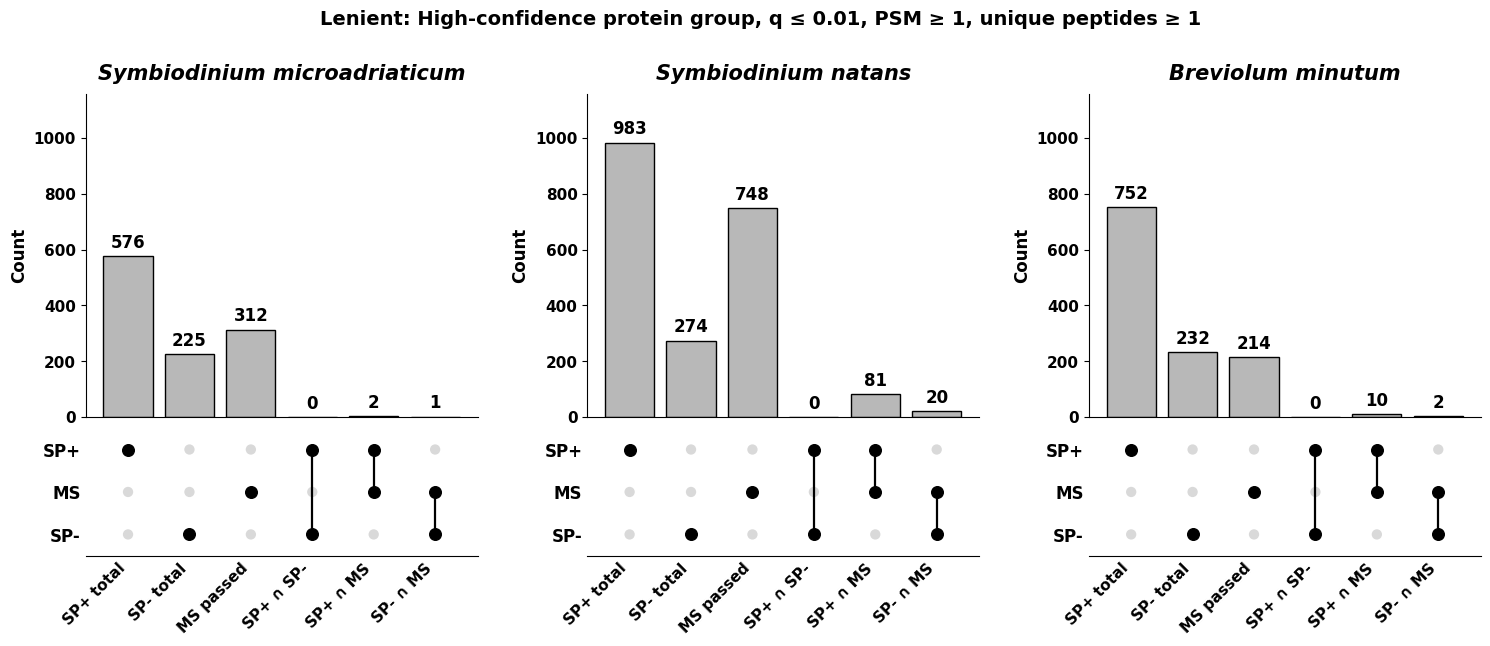

Saved:
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_lenient.png
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_lenient.svg
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_lenient.pdf


/tmp/ipykernel_3535/307517800.py:325: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


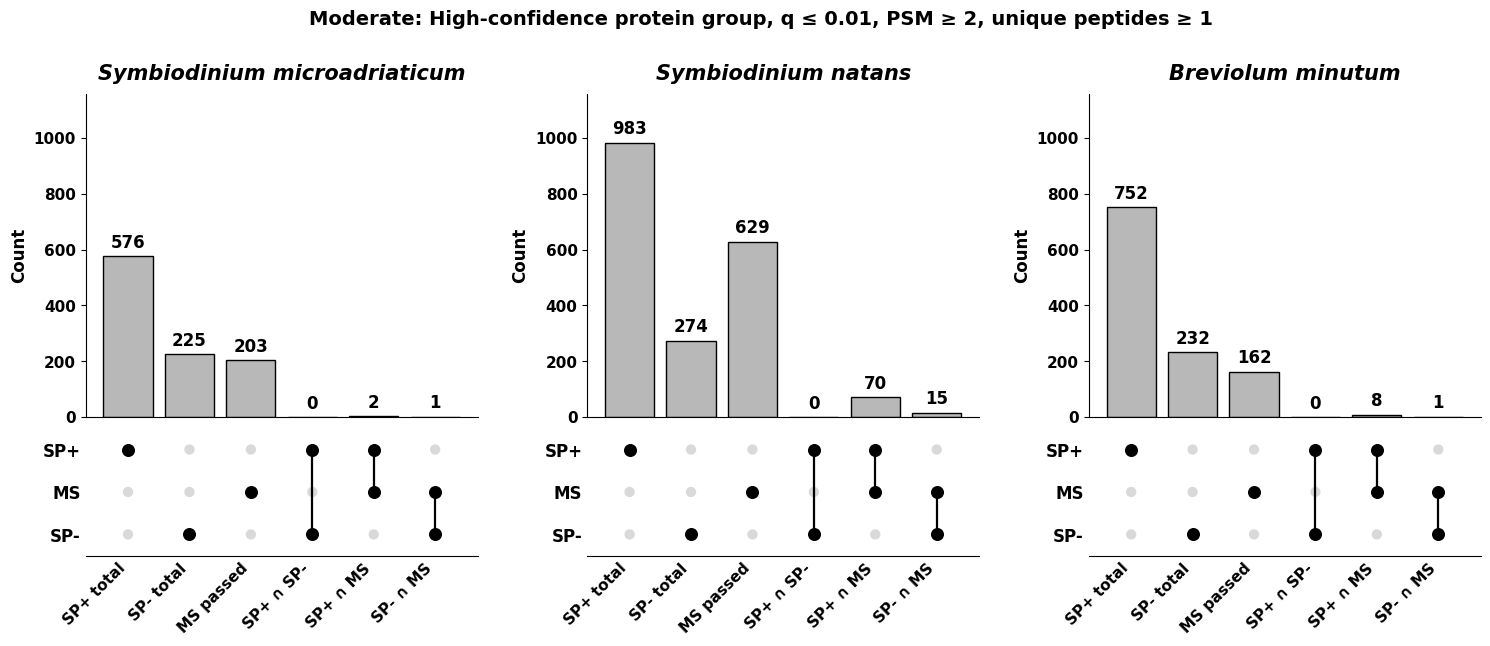

Saved:
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_moderate.png
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_moderate.svg
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_moderate.pdf


/tmp/ipykernel_3535/307517800.py:325: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


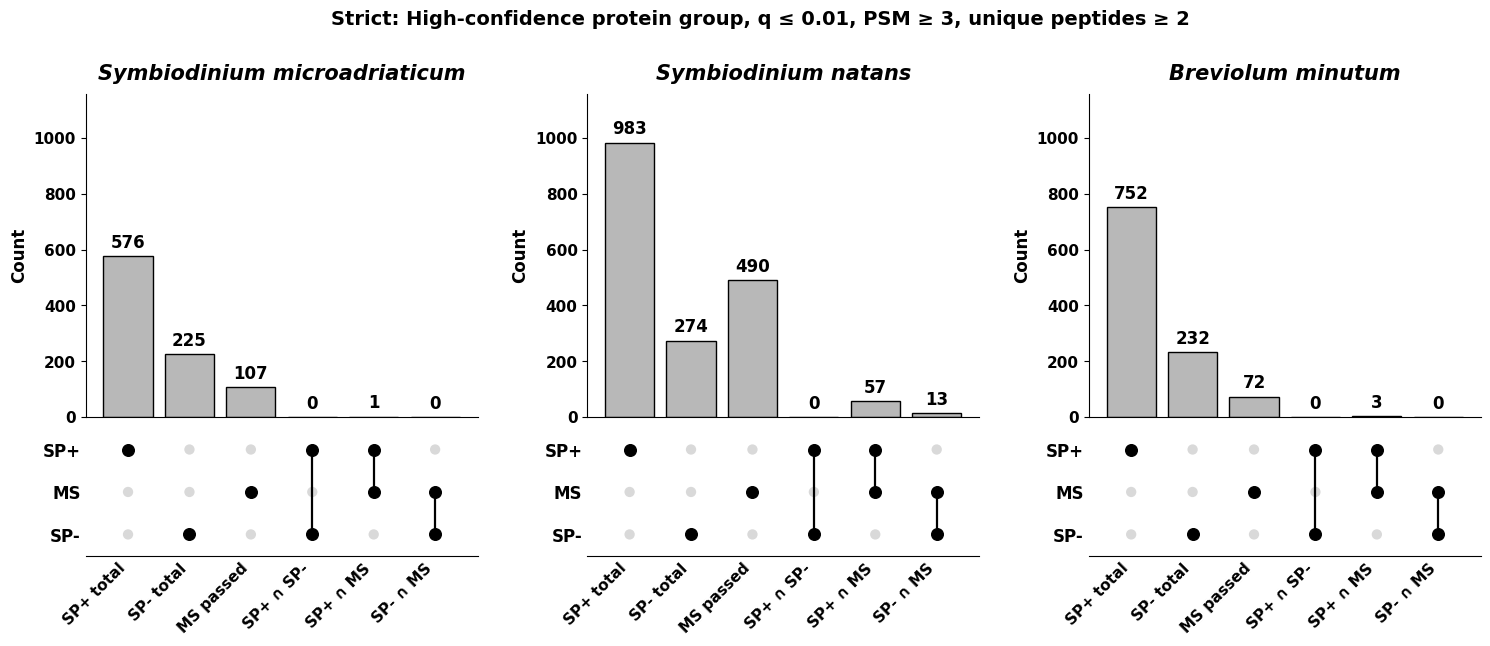

Saved:
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_strict.png
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_strict.svg
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_strict.pdf


/tmp/ipykernel_3535/307517800.py:325: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


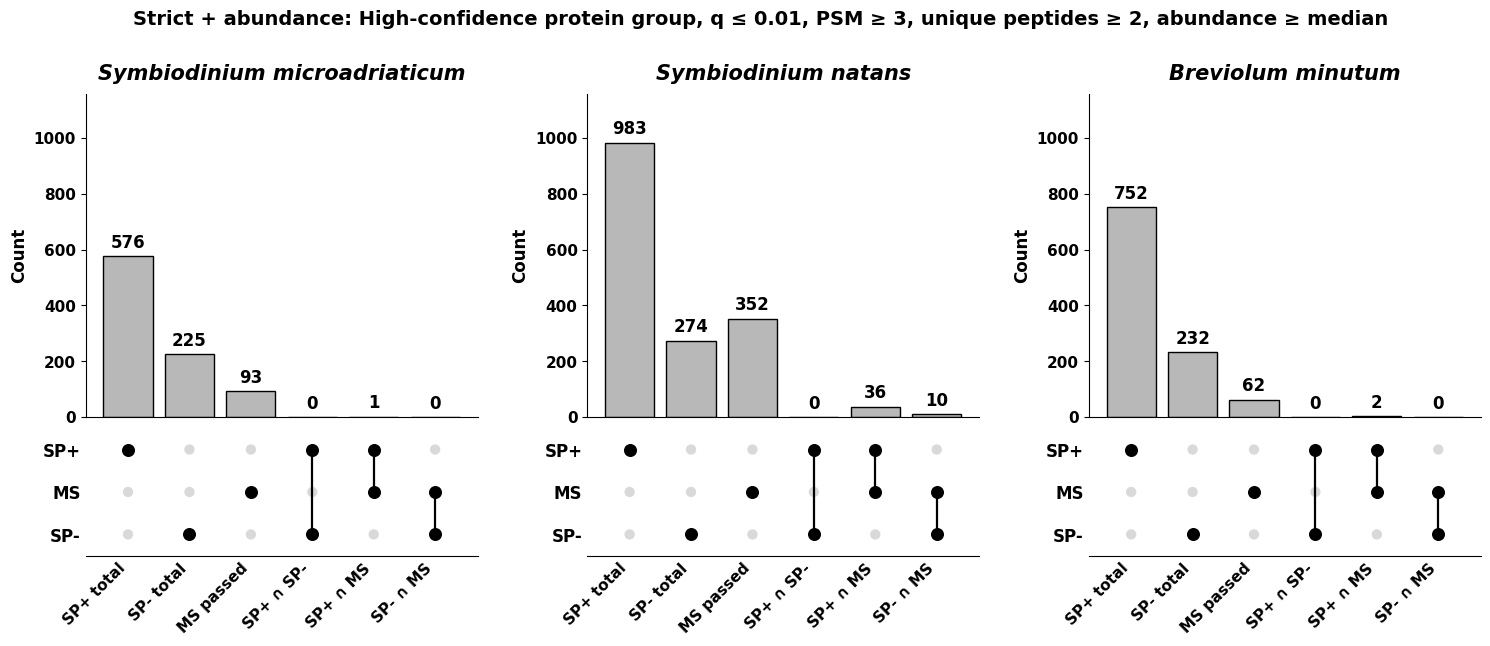

Saved:
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_strict_plus_abundance.png
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_strict_plus_abundance.svg
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_strict_plus_abundance.pdf
Saved summary: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/threshold_upset_fixed_sets_summary.tsv


In [ ]:
# =========================================================
# BLOCK: FIXED SP+ / SP- THRESHOLD PANELS
# One separate figure per threshold
# 3 strain panels per figure
#
# Bars:
#   SP+ total
#   SP- total
#   MS passed
#   SP+ ∩ SP-
#   SP+ ∩ MS passed
#   SP- ∩ MS passed
#
# SP+ and SP- stay fixed across thresholds
# =========================================================

import os
import re
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.font_manager import FontProperties

# =========================
# PATHS
# =========================
project_path = os.path.join(base, "MS_data")
outdir = os.path.join(project_path, "*Overlap*")
os.makedirs(outdir, exist_ok=True)

DATASETS = [
    {
        "strain": "Smic",
        "mapped_ms_table": os.path.join(outdir, "Smic_MS_mapped.tsv"),
        "sp_plus_fasta":   os.path.join(base, "Smic", "09_final", "Smic_SP_pos_secretome_final.faa"),
        "sp_minus_fasta":  os.path.join(base, "Smic", "09_final", "Smic_SP_neg_secretome_final.faa"),
    },
    {
        "strain": "Snat",
        "mapped_ms_table": os.path.join(outdir, "Snat_MS_mapped.tsv"),
        "sp_plus_fasta":   os.path.join(base, "Snat", "09_final", "Snat_SP_pos_secretome_final.faa"),
        "sp_minus_fasta":  os.path.join(base, "Snat", "09_final", "Snat_SP_neg_secretome_final.faa"),
    },
    {
        "strain": "Bmin",
        "mapped_ms_table": os.path.join(outdir, "Bmin_MS_mapped.tsv"),
        "sp_plus_fasta":   os.path.join(base, "Bmin", "09_final", "Bmin_SP_pos_secretome_final.faa"),
        "sp_minus_fasta":  os.path.join(base, "Bmin", "09_final", "Bmin_SP_neg_secretome_final.faa"),
    },
]

THRESHOLD_SETS = {
    "lenient": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 1,
        "min_unique_peptides": 1,
        "use_abundance": False,
        "abundance_quantile": None,
    },
    "moderate": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 2,
        "min_unique_peptides": 1,
        "use_abundance": False,
        "abundance_quantile": None,
    },
    "strict": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 3,
        "min_unique_peptides": 2,
        "use_abundance": False,
        "abundance_quantile": None,
    },
    "strict_plus_abundance": {
        "require_high_confidence": True,
        "max_qvalue": 0.01,
        "min_psm": 3,
        "min_unique_peptides": 2,
        "use_abundance": True,
        "abundance_quantile": 0.50,
    },
}

THRESHOLD_ORDER = ["lenient", "moderate", "strict", "strict_plus_abundance"]

THRESHOLD_TITLE = {
    "lenient": "Lenient: High-confidence protein group, q ≤ 0.01, PSM ≥ 1, unique peptides ≥ 1",
    "moderate": "Moderate: High-confidence protein group, q ≤ 0.01, PSM ≥ 2, unique peptides ≥ 1",
    "strict": "Strict: High-confidence protein group, q ≤ 0.01, PSM ≥ 3, unique peptides ≥ 2",
    "strict_plus_abundance": "Strict + abundance: High-confidence protein group, q ≤ 0.01, PSM ≥ 3, unique peptides ≥ 2, abundance ≥ median",
}

SPECIES_NAMES = {
    "Smic": "Symbiodinium microadriaticum",
    "Snat": "Symbiodinium natans",
    "Bmin": "Breviolum minutum",
}

# =========================
# STYLE
# =========================
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.size"] = 12

title_fp = FontProperties(style="italic", weight="bold", size=15)
label_fs = 12
num_fs = 16
tick_fs = 11

bar_color = "#B8B8B8"
dot_color = "black"
line_color = "black"
guide_dot_color = "#D9D9D9"

# =========================
# HELPERS
# =========================
def _clean(seq):
    if pd.isna(seq):
        return None
    return re.sub(r"\s+", "", str(seq).strip().upper().replace("*", ""))

def _hash(seq):
    s = _clean(seq)
    return hashlib.md5(s.encode()).hexdigest() if s else None

def read_fasta_hashes(path):
    seqs, cur, buf = [], None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if cur is not None:
                    seqs.append("".join(buf))
                cur, buf = line[1:].split()[0], []
            else:
                buf.append(line)
    if cur is not None:
        seqs.append("".join(buf))
    return {_hash(s) for s in seqs if _hash(s)}

def get_ms_df(path):
    df = pd.read_csv(path, sep="\t")
    if "seq_hash" not in df.columns:
        raise ValueError(f"'seq_hash' not found in {path}")
    return df

def choose_abundance_col(df):
    abundance_cols = [c for c in df.columns if str(c).startswith("Abundance:")]
    return abundance_cols[0] if abundance_cols else None

def apply_threshold_to_ms(df, cfg):
    x = df.copy()

    for c in ["Exp. q-value: Combined", "# PSMs", "# Unique Peptides"]:
        if c in x.columns:
            x[c] = pd.to_numeric(x[c], errors="coerce")

    abundance_col = choose_abundance_col(x)
    if abundance_col is not None:
        x[abundance_col] = pd.to_numeric(x[abundance_col], errors="coerce")

    keep = pd.Series(True, index=x.index)

    if cfg["require_high_confidence"] and "Protein FDR Confidence: Combined" in x.columns:
        keep &= x["Protein FDR Confidence: Combined"].astype(str).eq("High")

    if cfg["max_qvalue"] is not None and "Exp. q-value: Combined" in x.columns:
        keep &= x["Exp. q-value: Combined"].fillna(np.inf) <= cfg["max_qvalue"]

    if cfg["min_psm"] is not None and "# PSMs" in x.columns:
        keep &= x["# PSMs"].fillna(0) >= cfg["min_psm"]

    if cfg["min_unique_peptides"] is not None and "# Unique Peptides" in x.columns:
        keep &= x["# Unique Peptides"].fillna(0) >= cfg["min_unique_peptides"]

    if cfg["use_abundance"]:
        abundance_col = choose_abundance_col(x)
        if abundance_col is not None and cfg["abundance_quantile"] is not None:
            cutoff = x[abundance_col].dropna().quantile(cfg["abundance_quantile"])
            keep &= x[abundance_col].fillna(-np.inf) >= cutoff

    return x[keep].copy()

def compute_fixed_set_bars(sp_plus, ms_passed, sp_minus):
    """
    Fixed SP+ and SP- totals, threshold-dependent MS bars.
    This is NOT an exclusive partition.
    """
    combos = [
        ("SP+ total",       (1, 0, 0), len(sp_plus)),
        ("SP- total",       (0, 0, 1), len(sp_minus)),
        ("MS passed",       (0, 1, 0), len(ms_passed)),
        ("SP+ ∩ SP-",       (1, 0, 1), len(sp_plus & sp_minus)),
        ("SP+ ∩ MS",        (1, 1, 0), len(sp_plus & ms_passed)),
        ("SP- ∩ MS",        (0, 1, 1), len(sp_minus & ms_passed)),
    ]
    return combos

def draw_upset_panel(fig, outer_spec, title, combos, ymax):
    inner = gridspec.GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer_spec,
        height_ratios=[3.3, 1.3], hspace=0.05
    )

    ax_bar = fig.add_subplot(inner[0])
    ax_mat = fig.add_subplot(inner[1], sharex=ax_bar)

    labels = [x[0] for x in combos]
    memberships = [x[1] for x in combos]
    counts = [x[2] for x in combos]
    x = list(range(len(combos)))

    # bars
    ax_bar.bar(x, counts, color=bar_color, edgecolor="black", linewidth=1.0)
    for xi, c in zip(x, counts):
        ax_bar.text(
            xi,
            c + max(0.5, ymax * 0.015),
            str(c),
            ha="center",
            va="bottom",
            fontsize=num_fs - 4,
            fontweight="bold"
        )

    ax_bar.set_title(title, fontproperties=title_fp, pad=10)
    ax_bar.set_ylabel("Count", fontsize=label_fs, fontweight="bold")
    ax_bar.set_ylim(0, ymax)
    ax_bar.spines["top"].set_visible(False)
    ax_bar.spines["right"].set_visible(False)
    ax_bar.tick_params(axis="y", labelsize=tick_fs)
    for lbl in ax_bar.get_yticklabels():
        lbl.set_fontweight("bold")
    ax_bar.tick_params(axis="x", bottom=False, labelbottom=False)

    # matrix
    rows = ["SP+", "MS", "SP-"]
    y_pos = [2, 1, 0]

    for xi in x:
        for yy in y_pos:
            ax_mat.scatter(xi, yy, s=55, facecolor=guide_dot_color, edgecolor="none", zorder=1)

    for xi, member in zip(x, memberships):
        active_y = []
        for present, yy in zip(member, y_pos):
            if present:
                ax_mat.scatter(xi, yy, s=70, facecolor=dot_color, edgecolor="black", zorder=3)
                active_y.append(yy)
        if len(active_y) >= 2:
            ax_mat.plot([xi, xi], [min(active_y), max(active_y)], color=line_color, lw=1.6, zorder=2)

    ax_mat.set_yticks(y_pos)
    ax_mat.set_yticklabels(rows, fontsize=label_fs, fontweight="bold")
    ax_mat.set_xticks(x)
    ax_mat.set_xticklabels(labels, rotation=45, ha="right", fontsize=tick_fs, fontweight="bold")
    ax_mat.spines["top"].set_visible(False)
    ax_mat.spines["right"].set_visible(False)
    ax_mat.spines["left"].set_visible(False)
    ax_mat.tick_params(axis="y", length=0)
    ax_mat.tick_params(axis="x", length=0)
    ax_mat.set_ylim(-0.5, 2.5)

# =========================
# PRELOAD STATIC SETS
# =========================
base_records = []
for ds in DATASETS:
    base_records.append({
        "strain": ds["strain"],
        "sp_plus": read_fasta_hashes(ds["sp_plus_fasta"]),
        "sp_minus": read_fasta_hashes(ds["sp_minus_fasta"]),
        "ms_df": get_ms_df(ds["mapped_ms_table"]),
    })

summary_rows = []

# =========================
# MAIN
# =========================
for thr in THRESHOLD_ORDER:
    threshold_records = []
    local_max = 0

    for rec in base_records:
        strain = rec["strain"]
        sp_plus = rec["sp_plus"]
        sp_minus = rec["sp_minus"]
        ms_passed_df = apply_threshold_to_ms(rec["ms_df"], THRESHOLD_SETS[thr])
        ms_passed = set(ms_passed_df["seq_hash"].dropna().astype(str))

        combos = compute_fixed_set_bars(sp_plus, ms_passed, sp_minus)
        threshold_records.append((strain, combos))

        local_max = max(local_max, max(c for _, _, c in combos))

        row = {"threshold": thr, "strain": strain}
        for label, _, count in combos:
            row[label] = count
        summary_rows.append(row)

    ymax = max(5, int(local_max * 1.18))

    fig = plt.figure(figsize=(18, 6))
    outer = gridspec.GridSpec(1, 3, wspace=0.28)

    for i, (strain, combos) in enumerate(threshold_records):
        draw_upset_panel(
            fig,
            outer[i],
            SPECIES_NAMES[strain],
            combos,
            ymax=ymax
        )

    fig.suptitle(THRESHOLD_TITLE[thr], fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()

    png_file = os.path.join(outdir, f"threshold_upset_fixed_sets_{thr}.png")
    svg_file = os.path.join(outdir, f"threshold_upset_fixed_sets_{thr}.svg")
    pdf_file = os.path.join(outdir, f"threshold_upset_fixed_sets_{thr}.pdf")

    plt.savefig(png_file, dpi=600, bbox_inches="tight")
    plt.savefig(svg_file, bbox_inches="tight")
    plt.savefig(pdf_file, bbox_inches="tight")
    plt.show()

    print("Saved:")
    print(png_file)
    print(svg_file)
    print(pdf_file)

summary_df = pd.DataFrame(summary_rows)
summary_file = os.path.join(outdir, "threshold_upset_fixed_sets_summary.tsv")
summary_df.to_csv(summary_file, sep="\t", index=False)
print(f"Saved summary: {summary_file}")

Summary:
  strain secretome_type  count       mean  median        std  min  max
0   Bmin       pred_sp+     10   6.700000     5.0   9.153627    1   32
1   Bmin       pred_sp-      2   2.000000     2.0   1.414214    1    3
2   Smic       pred_sp+      2   7.000000     7.0   7.071068    2   12
3   Smic       pred_sp-      2  21.000000    21.0  26.870058    2   40
4   Snat       pred_sp+     87  19.724138     5.0  73.583158    1  670
5   Snat       pred_sp-     23  20.913043     5.0  42.123102    1  180
Saved summary: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/overlap_PSM_distribution_summary.tsv


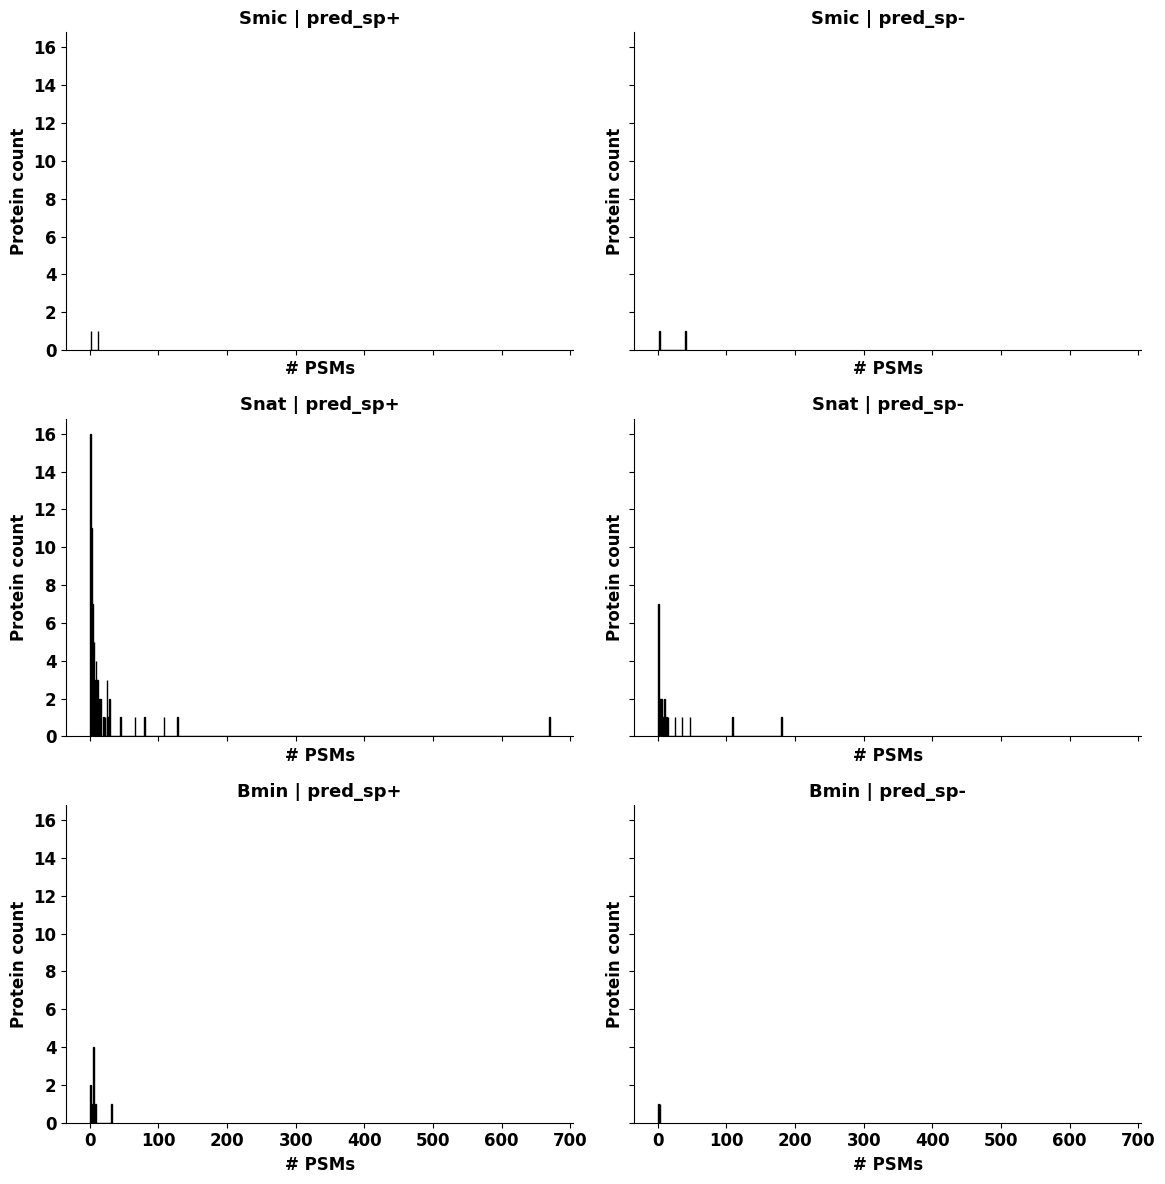

Saved histogram panel:
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/overlap_PSM_histograms.png
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/overlap_PSM_histograms.svg
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/overlap_PSM_histograms.pdf


/tmp/ipykernel_32206/3309794959.py:136: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


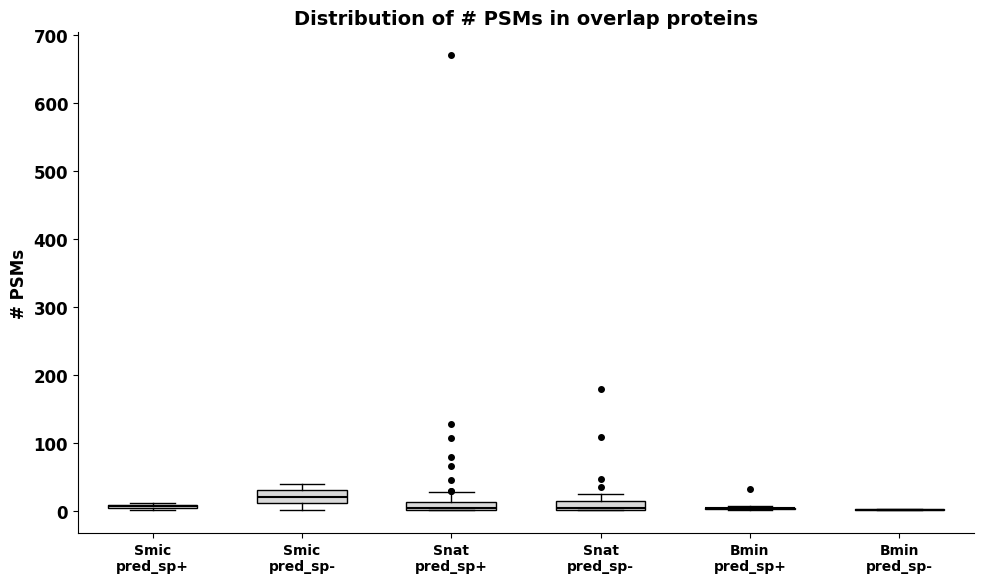

Saved boxplot:
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/overlap_PSM_boxplot.png
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/overlap_PSM_boxplot.svg
/content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/overlap_PSM_boxplot.pdf


In [ ]:
# =========================================================
# BLOCK: PLOT # PSMs DISTRIBUTION OF OVERLAP PROTEINS
# For:
#   Smic / Snat / Bmin
#   pred_sp+ / pred_sp-
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# PATHS
# =========================
project_path = os.path.join(base, "MS_data")
outdir = os.path.join(project_path, "*Overlap*")
os.makedirs(outdir, exist_ok=True)

strains = ["Smic", "Snat", "Bmin"]
secretome_types = ["pred_sp+", "pred_sp-"]

# =========================
# STYLE
# =========================
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.size"] = 12

# =========================
# LOAD OVERLAP FILES
# =========================
all_rows = []

for strain in strains:
    for sec_type in secretome_types:
        f = os.path.join(outdir, f"{strain}_{sec_type}_MS_vs_prediction_overlap.tsv")
        if not os.path.exists(f):
            print(f"[WARNING] File not found: {f}")
            continue

        df = pd.read_csv(f, sep="\t")

        if "# PSMs" not in df.columns:
            print(f"[WARNING] '# PSMs' not found in: {f}")
            continue

        df["# PSMs"] = pd.to_numeric(df["# PSMs"], errors="coerce")
        df = df[df["# PSMs"].notna()].copy()

        df["strain"] = strain
        df["secretome_type"] = sec_type

        all_rows.append(df[["strain", "secretome_type", "# PSMs"]])

if len(all_rows) == 0:
    raise ValueError("No valid overlap files with '# PSMs' found.")

plot_df = pd.concat(all_rows, ignore_index=True)

# optional combined group label
plot_df["group"] = plot_df["strain"] + "\n" + plot_df["secretome_type"]

# =========================
# SUMMARY TABLE
# =========================
summary_df = (
    plot_df
    .groupby(["strain", "secretome_type"])["# PSMs"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reset_index()
)

summary_file = os.path.join(outdir, "overlap_PSM_distribution_summary.tsv")
summary_df.to_csv(summary_file, sep="\t", index=False)

print("Summary:")
print(summary_df)
print(f"Saved summary: {summary_file}")

# =========================
# FIGURE 1: HISTOGRAM PANEL
# =========================
fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True, sharey=True)
axes = axes.flatten()

panel_order = [(s, t) for s in strains for t in secretome_types]

for ax, (strain, sec_type) in zip(axes, panel_order):
    sub = plot_df[(plot_df["strain"] == strain) & (plot_df["secretome_type"] == sec_type)].copy()

    if len(sub) == 0:
        ax.set_axis_off()
        continue

    max_psm = int(sub["# PSMs"].max())
    bins = np.arange(-0.5, max_psm + 1.5, 1)

    ax.hist(sub["# PSMs"], bins=bins, edgecolor="black")
    ax.set_title(f"{strain} | {sec_type}", fontsize=13, fontweight="bold")
    ax.set_xlabel("# PSMs", fontsize=12, fontweight="bold")
    ax.set_ylabel("Protein count", fontsize=12, fontweight="bold")

    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()

hist_png = os.path.join(outdir, "overlap_PSM_histograms.png")
hist_svg = os.path.join(outdir, "overlap_PSM_histograms.svg")
hist_pdf = os.path.join(outdir, "overlap_PSM_histograms.pdf")

plt.savefig(hist_png, dpi=600, bbox_inches="tight")
plt.savefig(hist_svg, bbox_inches="tight")
plt.savefig(hist_pdf, bbox_inches="tight")
plt.show()

print("Saved histogram panel:")
print(hist_png)
print(hist_svg)
print(hist_pdf)

# =========================
# FIGURE 2: BOXPLOT PANEL
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

box_order = [f"{s}\n{t}" for s in strains for t in secretome_types]
box_data = [
    plot_df.loc[plot_df["group"] == grp, "# PSMs"].dropna().values
    for grp in box_order
]

bp = ax.boxplot(
    box_data,
    labels=box_order,
    patch_artist=True,
    widths=0.6
)

for patch in bp["boxes"]:
    patch.set_facecolor("#D9D9D9")
    patch.set_edgecolor("black")

for median in bp["medians"]:
    median.set_color("black")
    median.set_linewidth(1.5)

for whisker in bp["whiskers"]:
    whisker.set_color("black")

for cap in bp["caps"]:
    cap.set_color("black")

for flier in bp["fliers"]:
    flier.set_markeredgecolor("black")
    flier.set_markerfacecolor("black")
    flier.set_markersize(4)

ax.set_ylabel("# PSMs", fontsize=12, fontweight="bold")
ax.set_title("Distribution of # PSMs in overlap proteins", fontsize=14, fontweight="bold")

for lbl in ax.get_xticklabels():
    lbl.set_fontweight("bold")
    lbl.set_fontsize(10)

for lbl in ax.get_yticklabels():
    lbl.set_fontweight("bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

box_png = os.path.join(outdir, "overlap_PSM_boxplot.png")
box_svg = os.path.join(outdir, "overlap_PSM_boxplot.svg")
box_pdf = os.path.join(outdir, "overlap_PSM_boxplot.pdf")

plt.savefig(box_png, dpi=600, bbox_inches="tight")
plt.savefig(box_svg, bbox_inches="tight")
plt.savefig(box_pdf, bbox_inches="tight")
plt.show()

print("Saved boxplot:")
print(box_png)
print(box_svg)
print(box_pdf)

# Block 5 - Annotation for overlaps

In [ ]:
# =========================================================
# DIAGNOSTIC: Check protein ID format consistency
# Compares FASTA IDs vs eggNOG IDs vs InterPro IDs
# =========================================================

for ds in DATASETS:
    strain = ds["strain"]
    print(f"\n{'='*65}")
    print(f"{strain} — ID format check")
    print(f"{'='*65}")

    # ── FASTA IDs ─────────────────────────────────────────
    for label, path in [("SP+ FASTA", ds["sp_plus_fasta"]),
                         ("SP- FASTA", ds["sp_minus_fasta"])]:
        ids = []
        with open(path) as f:
            for line in f:
                if line.startswith(">"):
                    ids.append(line[1:].strip().split()[0])
                if len(ids) == 5: break
        print(f"\n  {label} (first 5):")
        for i in ids: print(f"    {repr(i)}")

    # ── eggNOG IDs ────────────────────────────────────────
    egg_path = ANNOT[strain]["eggnog"]
    if os.path.exists(egg_path):
        egg_ids = []
        with open(egg_path) as f:
            for line in f:
                if line.startswith("#") or not line.strip(): continue
                egg_ids.append(line.split("\t")[0].strip())
                if len(egg_ids) == 5: break
        print(f"\n  eggNOG query IDs (first 5):")
        for i in egg_ids: print(f"    {repr(i)}")
    else:
        print(f"\n  eggNOG file not found: {egg_path}")

    # ── InterPro IDs ──────────────────────────────────────
    ipr_path = ANNOT[strain]["interpro"]
    if os.path.exists(ipr_path):
        ipr_ids = []
        with open(ipr_path) as f:
            for line in f:
                if not line.strip(): continue
                ipr_ids.append(line.split("\t")[0].strip())
                if len(ipr_ids) == 5: break
        print(f"\n  InterPro protein IDs (first 5):")
        for i in ipr_ids: print(f"    {repr(i)}")
    else:
        print(f"\n  InterPro file not found: {ipr_path}")

    # ── Overlap check ─────────────────────────────────────
    # Load full ID sets and test actual intersection size
    h2id_sp  = read_fasta_id_hash(ds["sp_plus_fasta"])
    h2id_spm = read_fasta_id_hash(ds["sp_minus_fasta"])
    fasta_ids = set(h2id_sp.values()) | set(h2id_spm.values())

    if os.path.exists(egg_path):
        egg_df  = load_eggnog(egg_path)
        egg_set = set(egg_df["protein_id"].dropna())
        matched = fasta_ids & egg_set
        print(f"\n  eggNOG match rate: {len(matched):,} / {len(fasta_ids):,} "
              f"({100*len(matched)/max(len(fasta_ids),1):.1f}%)")
        if len(matched) == 0:
            # Try stripping common prefixes/suffixes to suggest fix
            fasta_ex  = next(iter(fasta_ids))
            egg_ex    = next(iter(egg_set))
            print(f"  Example FASTA ID : {repr(fasta_ex)}")
            print(f"  Example eggNOG ID: {repr(egg_ex)}")

    if os.path.exists(ipr_path):
        ipr_df  = load_interpro(ipr_path)
        ipr_set = set(ipr_df["protein_id"].dropna())
        matched = fasta_ids & ipr_set
        print(f"\n  InterPro match rate: {len(matched):,} / {len(fasta_ids):,} "
              f"({100*len(matched)/max(len(fasta_ids),1):.1f}%)")
        if len(matched) == 0:
            fasta_ex = next(iter(fasta_ids))
            ipr_ex   = next(iter(ipr_set))
            print(f"  Example FASTA ID    : {repr(fasta_ex)}")
            print(f"  Example InterPro ID : {repr(ipr_ex)}")


Smic — ID format check

  SP+ FASTA (first 5):
    'jgi_Symmic1_10032_rna1416'
    'jgi_Symmic1_10144_rna37261'
    'jgi_Symmic1_10149_rna37266'
    'jgi_Symmic1_10240_rna37327'
    'jgi_Symmic1_10377_rna37426'

  SP- FASTA (first 5):
    'jgi_Symmic1_10010_rna1394'
    'jgi_Symmic1_10518_rna9477'
    'jgi_Symmic1_10668_rna37555'
    'jgi_Symmic1_10725_rna37612'
    'jgi_Symmic1_1077_rna31326'

  eggNOG query IDs (first 5):
    'jgi|Symmic1|10009|rna1393'
    'jgi|Symmic1|10011|rna1395'
    'jgi|Symmic1|10018|rna1402'
    'jgi|Symmic1|10020|rna1404'
    'jgi|Symmic1|10021|rna1405'

  InterPro protein IDs (first 5):
    'jgi|Symmic1|12748|rna38723'
    'jgi|Symmic1|12748|rna38723'
    'jgi|Symmic1|12748|rna38723'
    'jgi|Symmic1|12748|rna38723'
    'jgi|Symmic1|12748|rna38723'

  eggNOG match rate: 0 / 791 (0.0%)
  Example FASTA ID : 'jgi_Symmic1_15176_rna39641'
  Example eggNOG ID: 'jgi|Symmic1|34172|rna24195'

  InterPro match rate: 0 / 791 (0.0%)
  Example FASTA ID    : 'jgi_Symmic

In [ ]:
# =========================================================
# BLOCK 5: Annotation table for ALL threshold overlapped proteins
# Output 1: per-strain per-threshold TSV
# Output 2: combined TSV across all strains and thresholds
# =========================================================

import os, re, hashlib
import numpy as np
import pandas as pd
from IPython.display import display

ann_path     = os.path.join(base, "8_Annotation_results")
project_path = os.path.join(base, "Prediction_vs_Detection")
outdir       = os.path.join(project_path, "MS_data", "*Overlap*")

ANNOT = {
    "Smic": {
        "eggnog":   os.path.join(ann_path, "Smic_jgi.emapper.annotations"),
        "interpro": os.path.join(ann_path, "Symmic_jgi_noStar.faa.tsv"),
    },
    "Snat": {
        "eggnog":   os.path.join(ann_path, "Snat_background_eggnog.emapper.annotations"),
        "interpro": os.path.join(ann_path, "Snat_background_interproscan.tsv"),
    },
    "Bmin": {
        "eggnog":   os.path.join(ann_path, "Bmin_background_eggnog.emapper.annotations"),
        "interpro": os.path.join(ann_path, "Bmin_background_interproscan.tsv"),
    },
}

DATASETS = [
    {"strain": "Smic",
     "mapped_ms_table": os.path.join(outdir, "Smic_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(project_path, "Smic_jgi", "09_final", "Smic_jgi_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(project_path, "Smic_jgi", "09_final", "Smic_jgi_SP_neg_secretome_final.faa")},
    {"strain": "Snat",
     "mapped_ms_table": os.path.join(outdir, "Snat_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(project_path, "Snat", "09_final", "Snat_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(project_path, "Snat", "09_final", "Snat_SP_neg_secretome_final.faa")},
    {"strain": "Bmin",
     "mapped_ms_table": os.path.join(outdir, "Bmin_MS_mapped.tsv"),
     "sp_plus_fasta":   os.path.join(project_path, "Bmin", "09_final", "Bmin_SP_pos_secretome_final.faa"),
     "sp_minus_fasta":  os.path.join(project_path, "Bmin", "09_final", "Bmin_SP_neg_secretome_final.faa")},
]

# ── Helpers ───────────────────────────────────────────────
def clean_protein_id(x):
    if pd.isna(x): return None
    s = str(x).strip().split()[0]

    # ── Smic: FASTA uses underscores, annotations use pipes ──
    # jgi_Symmic1_10032_rna1416  →  jgi|Symmic1|10032|rna1416
    if s.startswith("jgi_"):
        s = s.replace("_", "|", 3)   # replace first 3 underscores only
        # jgi_Symmic1_10032_rna1416 has exactly 3 underscores to replace

    # ── Bmin: FASTA has a spurious backslash before trailing number ──
    # symbB...size812218|\1  →  symbB...size812218|1
    if s.startswith("symbB"):
        s = s.replace("\\", "")

    return s

def _clean(seq):
    if pd.isna(seq): return None
    return re.sub(r"\s+", "", str(seq).strip().upper().replace("*", ""))

def _hash(seq):
    s = _clean(seq)
    return hashlib.md5(s.encode()).hexdigest() if s else None

def read_fasta_id_hash(path):
    mapping = {}
    cur, buf = None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line: continue
            if line.startswith(">"):
                if cur is not None:
                    h = _hash("".join(buf))
                    if h: mapping[h] = cur
                cur = clean_protein_id(line[1:].split()[0])
                buf = []
            else:
                buf.append(line)
    if cur is not None:
        h = _hash("".join(buf))
        if h: mapping[h] = cur
    return mapping

def load_eggnog(path):
    header, raw_rows = None, []
    with open(path) as f:
        for line in f:
            if line.startswith("#query"):
                header = line.lstrip("#").rstrip("\n").split("\t")
            elif not line.startswith("#") and line.strip():
                raw_rows.append(line.rstrip("\n").split("\t"))
    if header is None:
        header = [f"col{i}" for i in range(len(raw_rows[0]))]
    df = pd.DataFrame(raw_rows, columns=header[:len(raw_rows[0])])
    df = df.rename(columns={"query": "protein_id"})
    df["protein_id"] = df["protein_id"].map(clean_protein_id)
    keep = {
        "protein_id":     "protein_id",
        "Preferred_name": "eggnog_gene_name",
        "Description":    "eggnog_description",
        "COG_category":   "COG_category",
        "eggNOG_OGs":     "eggnog_OGs",
        "KEGG_ko":        "KEGG_ko",
        "PFAMs":          "Pfam",
    }
    available = {k: v for k, v in keep.items() if k in df.columns}
    return df[list(available.keys())].rename(columns=available)

def load_interpro(path):
    cols = ["protein_id", "md5", "length", "analysis",
            "accession", "description", "start", "end",
            "evalue", "status", "date",
            "ipr_accession", "ipr_description", "GO", "pathway"]
    df = pd.read_csv(path, sep="\t", header=None,
                     names=cols[:15], usecols=range(15),
                     low_memory=False, on_bad_lines="skip")
    df["protein_id"] = df["protein_id"].map(clean_protein_id)

    def join_unique(s):
        vals = s.dropna().astype(str)
        vals = vals[vals.str.strip().ne("") & vals.str.strip().ne("-")]
        return "; ".join(sorted(set(vals))) if len(vals) else ""

    return df.groupby("protein_id", as_index=False).agg(
        interpro_accessions  = ("ipr_accession",   join_unique),
        interpro_descriptions= ("ipr_description", join_unique),
        GO_terms             = ("GO",              join_unique),
    )

COL_ORDER = [
    "strain", "threshold", "protein_id", "SP_type",
    "eggnog_gene_name", "eggnog_description", "COG_category",
    "eggnog_OGs", "KEGG_ko", "Pfam",
    "interpro_accessions", "interpro_descriptions", "GO_terms",
]

# ── Preload annotations once per strain (expensive) ───────
print("Loading annotation files...")
ANNOT_CACHE = {}
for strain, paths in ANNOT.items():
    egg = load_eggnog(paths["eggnog"]) if os.path.exists(paths["eggnog"]) else None
    ipr = load_interpro(paths["interpro"]) if os.path.exists(paths["interpro"]) else None
    ANNOT_CACHE[strain] = {"eggnog": egg, "interpro": ipr}
    print(f"  {strain}: eggNOG={'✓' if egg is not None else '✗'}  "
          f"InterPro={'✓' if ipr is not None else '✗'}")

# ── Main loop: all strains × all thresholds ───────────────
all_tables = []

for ds in DATASETS:
    strain   = ds["strain"]
    h2id_sp  = read_fasta_id_hash(ds["sp_plus_fasta"])
    h2id_spm = read_fasta_id_hash(ds["sp_minus_fasta"])
    ms_df    = pd.read_csv(ds["mapped_ms_table"], sep="\t")
    ms_all   = set(ms_df["seq_hash"].dropna().astype(str))

    sp_plus_hashes  = set(h2id_sp.keys())
    sp_minus_hashes = set(h2id_spm.keys())

    print(f"\n{'='*65}")
    print(f"{strain}")
    print(f"{'='*65}")

    for thr in THRESHOLD_ORDER:
        ms_passed      = apply_threshold(ms_df, THRESHOLD_SETS[thr])
        overlap_hashes = (sp_plus_hashes | sp_minus_hashes) & ms_passed

        # Resolve hashes → protein IDs with SP type
        rows = []
        for h in overlap_hashes:
            if h in h2id_sp:
                rows.append({"seq_hash": h,
                             "protein_id": h2id_sp[h],
                             "SP_type": "SP+"})
            if h in h2id_spm:
                rows.append({"seq_hash": h,
                             "protein_id": h2id_spm[h],
                             "SP_type": "SP-"})

        if not rows:
            print(f"  [{thr}] No overlapping proteins found — skipping")
            continue

        df = (pd.DataFrame(rows)
                .drop_duplicates(subset=["protein_id"])
                .drop(columns=["seq_hash"]))

        # Merge annotations
        egg = ANNOT_CACHE[strain]["eggnog"]
        ipr = ANNOT_CACHE[strain]["interpro"]
        if egg is not None:
            df = df.merge(egg, on="protein_id", how="left")
        if ipr is not None:
            df = df.merge(ipr, on="protein_id", how="left")

        # Add identifiers
        df.insert(0, "threshold", thr)
        df.insert(0, "strain",    strain)

        # Keep only columns that exist
        final_cols = [c for c in COL_ORDER if c in df.columns]
        df = df[final_cols].sort_values(["SP_type", "protein_id"])

        n_sp  = (df["SP_type"] == "SP+").sum()
        n_spm = (df["SP_type"] == "SP-").sum()
        print(f"  [{thr}]  SP+={n_sp:,}  SP-={n_spm:,}  total={len(df):,}")

        # Save per-strain per-threshold TSV
        out_file = os.path.join(
            outdir, f"{strain}_overlap_{thr}_annotated.tsv")
        df.to_csv(out_file, sep="\t", index=False)

        all_tables.append(df)

        # Preview top 10 for Snat strict
        if strain == "Snat" and thr == "strict":
            print(f"\n  Preview — Snat strict, top 10:")
            display(df.head(10))

# ── No-threshold overlap annotation table ─────────────────
print("\nBuilding no-threshold overlap annotation table...")
no_thresh_tables = []

for ds in DATASETS:
    strain   = ds["strain"]
    h2id_sp  = read_fasta_id_hash(ds["sp_plus_fasta"])
    h2id_spm = read_fasta_id_hash(ds["sp_minus_fasta"])
    ms_df    = pd.read_csv(ds["mapped_ms_table"], sep="\t")
    ms_all   = set(ms_df["seq_hash"].dropna().astype(str))

    sp_plus_hashes  = set(h2id_sp.keys())
    sp_minus_hashes = set(h2id_spm.keys())

    # All detected MS proteins — no threshold applied
    overlap_hashes = (sp_plus_hashes | sp_minus_hashes) & ms_all

    rows = []
    for h in overlap_hashes:
        if h in h2id_sp:
            rows.append({"protein_id": h2id_sp[h],  "SP_type": "SP+"})
        if h in h2id_spm:
            rows.append({"protein_id": h2id_spm[h], "SP_type": "SP-"})

    if not rows:
        print(f"  [{strain}] No overlapping proteins found — skipping")
        continue

    df = (pd.DataFrame(rows)
            .drop_duplicates(subset=["protein_id"]))

    # Merge annotations
    egg = ANNOT_CACHE[strain]["eggnog"]
    ipr = ANNOT_CACHE[strain]["interpro"]
    if egg is not None:
        df = df.merge(egg, on="protein_id", how="left")
    if ipr is not None:
        df = df.merge(ipr, on="protein_id", how="left")

    df.insert(0, "threshold", "none")
    df.insert(0, "strain",    strain)

    final_cols = [c for c in COL_ORDER if c in df.columns]
    df = df[final_cols].sort_values(["SP_type", "protein_id"])

    n_sp  = (df["SP_type"] == "SP+").sum()
    n_spm = (df["SP_type"] == "SP-").sum()
    print(f"  {strain}:  SP+={n_sp:,}  SP-={n_spm:,}  total={len(df):,}")

    # Save per-strain
    out_file = os.path.join(outdir, f"{strain}_overlap_no_threshold_annotated.tsv")
    df.to_csv(out_file, sep="\t", index=False)
    print(f"  Saved: {out_file}")

    no_thresh_tables.append(df)

# Combined no-threshold table
no_thresh_combined = pd.concat(no_thresh_tables, ignore_index=True)
no_thresh_file = os.path.join(outdir, "ALL_overlap_no_threshold_annotated.tsv")
no_thresh_combined.to_csv(no_thresh_file, sep="\t", index=False)
print(f"\nSaved combined no-threshold table: {no_thresh_file}")
print(f"  {len(no_thresh_combined):,} rows × {len(no_thresh_combined.columns)} columns")

# ── Combined table across all strains and thresholds ──────
combined = pd.concat(all_tables, ignore_index=True)
combined_file = os.path.join(outdir, "ALL_overlap_annotated.tsv")
combined.to_csv(combined_file, sep="\t", index=False)

print(f"\n{'='*65}")
print(f"Combined table: {len(combined):,} rows × {len(combined.columns)} columns")
print(f"Saved: {combined_file}")
print(f"{'='*65}")
print(combined.groupby(["strain", "threshold", "SP_type"])
              .size().reset_index(name="n_proteins").to_string(index=False))

Loading annotation files...
  Smic: eggNOG=✓  InterPro=✓
  Snat: eggNOG=✓  InterPro=✓
  Bmin: eggNOG=✓  InterPro=✓

Smic
  [lenient]  SP+=2  SP-=1  total=3
  [moderate]  SP+=1  SP-=0  total=1
  [strict]  SP+=1  SP-=0  total=1
  [strict_plus_abundance] No overlapping proteins found — skipping

Snat
  [lenient]  SP+=81  SP-=20  total=101
  [moderate]  SP+=61  SP-=14  total=75
  [strict]  SP+=28  SP-=8  total=36

  Preview — Snat strict, top 10:


,strain,threshold,protein_id,SP_type,eggnog_gene_name,eggnog_description,COG_category,eggnog_OGs,KEGG_ko,Pfam,interpro_accessions,interpro_descriptions,GO_terms
17,Snat,strict,CAE6922516.1,SP+,-,Protein of unknown function (DUF1501),S,"COG5267@1|root,2QSGJ@2759|Eukaryota,2XF2W@2836...",-,"DUF1501,DUF1800",IPR010869; IPR014917; IPR036400,Cytochrome b5-like heme/steroid binding domain...,
14,Snat,strict,CAE6938728.1,SP+,-,"cellulose 1,4-beta-cellobiosidase activity",G,"2C38W@1|root,2QPHV@2759|Eukaryota","ko:K01225,ko:K19357","CBM_1,Glyco_hydro_7",IPR000254; IPR001722; IPR013320; IPR035971; IP...,Cellulose-binding domain; Cellulose-binding do...,GO:0004553(InterPro)|GO:0005975(InterPro); GO:...
18,Snat,strict,CAE6961745.1,SP+,-,Cadmium carbonic anhydrase repeat,S,"2EIE5@1|root,2SNUS@2759|Eukaryota",-,CdCA1,IPR018883,Delta carbonic anhydrase,
23,Snat,strict,CAE7212679.1,SP+,-,-,-,"2CZMN@1|root,2SAXR@2759|Eukaryota",-,-,NaN,NaN,NaN
10,Snat,strict,CAE7214293.1,SP+,-,Domain found in Notch and Lin-12,O,"KOG3538@1|root,KOG3538@2759|Eukaryota,3YHNT@57...",-,"Notch,TSP_1",IPR000884; IPR036383; IPR044004; IPR051418,Spondin-like TSP1 domain; Spondin/Thrombospond...,GO:0007155(PANTHER)|GO:0031012(PANTHER)
28,Snat,strict,CAE7218070.1,SP+,-,Belongs to the glycosyl hydrolase 7 (cellulase...,G,"2C38W@1|root,2QPHV@2759|Eukaryota,38HWR@33154|...","ko:K01225,ko:K19357","CBM_1,Glyco_hydro_7",IPR001722; IPR013320; IPR037019,Concanavalin A-like lectin/glucanase domain su...,GO:0004553(InterPro)|GO:0005975(InterPro)
26,Snat,strict,CAE7231276.1,SP+,-,MAM and LDL-receptor class A domain-containing...,T,"COG0515@1|root,KOG1095@2759|Eukaryota,38GM4@33...",-,"Ldl_recept_a,MAM",IPR000998; IPR001506; IPR002889; IPR006026; IP...,Carbohydrate-binding WSC; Concanavalin A-like ...,GO:0004222(InterPro)|GO:0006508(InterPro); GO:...
2,Snat,strict,CAE7246594.1,SP+,MARCO,Macrophage receptor with collagenous structure,T,"28PZC@1|root,2QWN1@2759|Eukaryota,39R6Z@33154|...",ko:K13884,"Collagen,SRCR",IPR001190; IPR015915; IPR036772,Kelch-type beta-propeller; SRCR domain; SRCR-l...,GO:0004252(PANTHER)|GO:0005886(PANTHER)|GO:003...
34,Snat,strict,CAE7252521.1,SP+,-,Filamin/ABP280 repeat,Z,"COG5069@1|root,KOG0518@2759|Eukaryota,3X8C7@55...",ko:K04437,"CH,Filamin",IPR000742; IPR001298; IPR013783; IPR014756; IP...,CalX-like domain superfamily; EGF-like domain;...,GO:0005515(InterPro)
16,Snat,strict,CAE7274357.1,SP+,NaN,NaN,NaN,NaN,NaN,NaN,,,


  [strict_plus_abundance]  SP+=18  SP-=5  total=23

Bmin
  [lenient]  SP+=10  SP-=2  total=12
  [moderate]  SP+=7  SP-=1  total=8
  [strict]  SP+=1  SP-=0  total=1
  [strict_plus_abundance]  SP+=1  SP-=0  total=1

Building no-threshold overlap annotation table...
  Smic:  SP+=2  SP-=2  total=4
  Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/Smic_overlap_no_threshold_annotated.tsv
  Snat:  SP+=87  SP-=23  total=110
  Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/Snat_overlap_no_threshold_annotated.tsv
  Bmin:  SP+=10  SP-=2  total=12
  Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/Bmin_overlap_no_threshold_annotated.tsv

Saved combined no-threshold table: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/ALL_overlap_no_threshold_annotated.tsv
  126 rows × 13 columns

Combined table: 262 rows × 13 columns
Saved: /content/drive/MyDriv

## 5-1 - S. natans overlap categorize

Loaded 110 proteins from Snat_overlap_no_threshold_annotated.tsv
  SP+: 87  SP-: 23

Category summary (12 categories):
                                     Category  n_proteins  n_unique_pfam  proportion
                                        Other          85             47    0.772727
     ECM / adhesion / extracellular scaffolds          12              7    0.109091
                          Glycosyl hydrolases           8              7    0.072727
   Lectin / cysteine-rich recognition modules           7              6    0.063636
Ig-like / receptor-like extracellular modules           6              5    0.054545
              Phosphatases / phosphoesterases           4              2    0.036364
                                Unknown / DUF           4              5    0.036364
         Serine proteases / carboxypeptidases           4              3    0.036364
                Signal transduction / sensing           2              3    0.018182
            Pore-forming / cyto

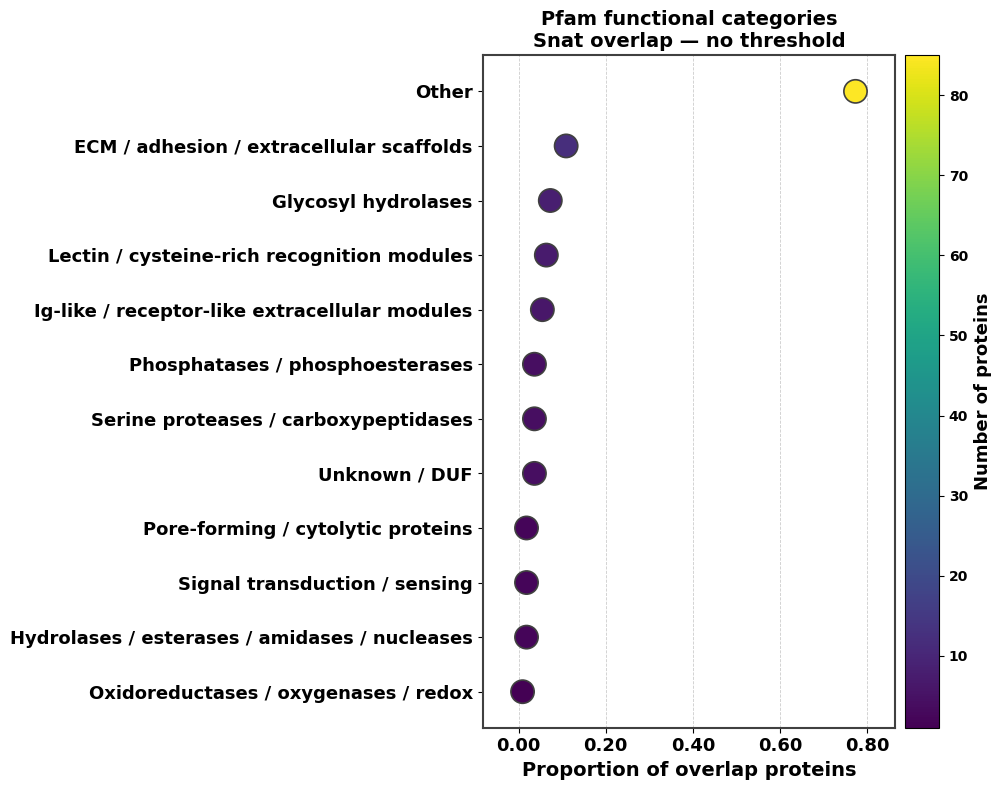

Saved: Snat_no_threshold_Pfam_categories .pdf / .svg / .png


In [ ]:
# =========================================================
# BLOCK: Pfam category dot plot for Snat overlap proteins
# Adapts Block 2-7 category rules to the overlap table
# x-axis: proportion of proteins in each category
# colour:  number of proteins
# shape:   SP+ vs SP- shown as separate rows (or combined)
# =========================================================

import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import FormatStrFormatter

project_path = os.path.join(base, "Prediction_vs_Detection")
outdir       = os.path.join(project_path, "MS_data", "*Overlap*")


# ── Settings ──────────────────────────────────────────────
TARGET_STRAIN    = "Snat"
TARGET_THRESHOLD = "no_threshold"   # "no_threshold" / "lenient" / "moderate" / "strict" / "strict_plus_abundance"
SP_MODE          = "combined"       # "combined" / "split"  (split = separate rows per SP type)

FIGSIZE      = (10, 8)
DOT_SIZE     = 280
EDGE_COLOR   = "0.25"
EDGE_LW      = 1.2
SPINE_COLOR  = "0.25"
SPINE_LW     = 1.5
TICK_FS      = 13
LABEL_FS     = 14
TITLE_FS     = 14

# ── Category rules (identical to Block 2-7) ───────────────
rules = [
    ("ECM / adhesion / extracellular scaffolds",
     r"(somatomedin_?b|thrombospondin|tsp_?1|spondin|spond_n|g8\b|mam\b|fibronectin|fn3|laminin|tenascin|vwa\b"
     r"|collagen|fasciclin|filamin|fibrinogen|calx.?beta|teneurin|egf_ca|g2f\b"
     r"|somatomedin|spond)"),
    ("Ig-like / receptor-like extracellular modules",
     r"(ig.like|ipt.?tig|\btig\b|i.set\b|ig_3\b|f5_f8_type_c|f5.8.type|pan\b|pan_4|pkd\b"
     r"|ldl_recept|cub\b|sushi\b|reeler\b|manec\b|notch\b|anf_receptor|putative.ig"
     r"|\begf\b(?!_ca)|bact_surface_ig)"),
    ("Lectin / cysteine-rich recognition modules",
     r"(lectin|ricin|concanavalin|shk\b|peritrophin|chitin|b_lectin|pa14\b|cbm_"
     r"|furin.like|kunitz|h_lectin\b|lectin_c\b)"),
    ("Sulfatases / sulfotransferases",
     r"(sulfatas|sulfatase_c|fge.sulfatase)"),
    ("Metalloproteases",
     r"(astacin|leishmanolysin|aspzincin|peptidase_m8\b|peptidase_m12|peptidase_m14\b"
     r"|peptidase_m28\b|peptidase_m35\b|peptidase_m76\b|metalloprotease"
     r"|lysine.specific.metallo|lysine.metallo|metallo.endopeptidase)"),
    ("Aspartyl proteases",
     r"(aspartyl.protease|a1_propeptide|\basp\b)"),
    ("Cysteine proteases",
     r"(peptidase_c1\b|peptidase_c13\b|papain|inhibitor_i29|i29\b)"),
    ("Serine proteases / carboxypeptidases",
     r"(trypsin|peptidase_s8\b|peptidase_s10\b|peptidase_s28\b|serine.carboxypeptidase"
     r"|peptidase_s1\b)"),
    ("Protease-associated domains / regulators",
     r"(cathepsin.propeptide|propeptide_c1|p_proprotein|s8_pro.domain|\bpa.domain\b"
     r"|pa\b.*domain|propeptide\b|gf_recep)"),
    ("Pore-forming / cytolytic proteins",
     r"(mac.perforin|macpf\b|perforin|hemolysin|haemolysin|hemolys|toxin)"),
    ("Glycosyl hydrolases",
     r"(glyco_hydro|glycosyl.hydrolase|gh\d+\b"
     r"|alpha.mannosidase|alpha.mann|alpha.galactosidase|alpha.amylase"
     r"|melibiase|glucanase|cellulase|glucosidase|glyco_hydro_3\b|glyco_hydro_7\b"
     r"|glyco_hydro_16\b|glyco_hydro_18\b|glyco_hydro_20\b|glyco_hydro_28\b"
     r"|glyco_hydro_31\b|glyco_hydro_38\b|glyco_hydro_47\b|glyco_hydro_59\b"
     r"|glyco_hydro_72\b|glyco_hydro_81\b|glyco_hydro_95\b|malt_amylase"
     r"|glycohydro_20b2|amylase|fn3.like.*glyco|lpmo_10\b)"),
    ("Glycosyltransferases",
     r"(glyco_transf|glycosyltransferase|galactosyltransferase|exostosin|fringe"
     r"|galactosyl_t|glyco_transf_1[5-9]|glyco_transf_90|glyco_transf_17"
     r"|glycosyl.transferase.family|glycolipid.*mannosyl|mannosyltransferase)"),
    ("Carbohydrate-binding modules",
     r"(cbm_\d|cellulose.binding|sugar.binding|carbohydrate.binding|chitin_bind|cbm_14)"),
    ("Sulfotransferases / methyltransferases",
     r"(methyltransf|lysine.methyltransferase|methyl.transferase|sulfotransfer"
     r"|sulfotransf|o.methyltransferase|farnesoic.*methyl)"),
    ("Phosphatases / phosphoesterases",
     r"(metallophos|phosphatase|phosphoesterase|pgap1|calcineurin.like.phosphoesterase"
     r"|phou.domain|phosphatidate.phosphatase|app1_cat)"),
    ("Hydrolases / esterases / amidases / nucleases",
     r"(nucleoside.hydrolase|iu_nuc_hydro|inosine.uridine|carboxylesterase|coesterase"
     r"|beta.lactamase|hydrolase.catalytic|amidohydro|dnase|nuclease|cbah"
     r"|choloylglycine|linear.amide)"),
    ("Lipid metabolism",
     r"(acyl.coa|phosphatidate|acid.amidase|lipid|glycolipid|apolipoprotein)"),
    ("Oxidoreductases / oxygenases / redox",
     r"(2og.feii_oxy|pyrid_oxidase|amino_oxidase|tyrosinase|thioredoxin|peroxidase"
     r"|oxidase|oxygenase|oxidoreductase|aldo_ket_red|aldo.keto.reductase"
     r"|flavin.*amine|amine.*oxidoreductase|gilt\b|gamma.interferon.*thiol"
     r"|pqq\b|pqq_2|cytochrome_cbb3|creg_beta)"),
    ("Antimicrobial / pathogenesis-related proteins",
     r"(thaumatin|defensin|pr.protein|pathogenesis.related)"),
    ("Signal transduction / sensing",
     r"(his.kinase|chemotaxis|methyl.accepting|kelch|beta.propeller|7tm_|anf_receptor"
     r"|rcc1|rcc1_2|alpha_kinase|tpr_\d|tpr.repeat|regulator.of.chromosome)"),
    ("Protein folding / chaperone / stress",
     r"(cyclophilin|sti1.hop|hsp20|alpha.crystallin|stress|surnod19)"),
    ("Mobile element / reverse transcriptase / helicase",
     r"(reverse.transcriptase|rna.dependent.dna.polymerase|helicase|retrotranspos|retroelement)"),
    ("Unknown / DUF",
     r"(domain.of.unknown.function|uncharacterized|\bduf\d+\b|duf\b|protein.of.unknown)"),
]

# ── Helpers ───────────────────────────────────────────────
def clean_text(x):
    if pd.isna(x): return ""
    x = str(x).strip()
    return "" if x in ("", "-", "nan") else x

def split_pfam_terms(x):
    x = clean_text(x)
    if not x: return []
    return [p.strip() for p in re.split(r"[,|;]\s*", x) if p.strip()]

def assign_category(pfam_term):
    text = pfam_term.lower()
    for cat, pat in rules:
        if re.search(pat, text):
            return cat
    return "Other"

# ── Load overlap annotation table ─────────────────────────
if TARGET_THRESHOLD == "no_threshold":
    ann_file = os.path.join(outdir,
        f"{TARGET_STRAIN}_overlap_no_threshold_annotated.tsv")
else:
    ann_file = os.path.join(outdir,
        f"{TARGET_STRAIN}_overlap_{TARGET_THRESHOLD}_annotated.tsv")

if not os.path.exists(ann_file):
    raise FileNotFoundError(f"Annotation file not found:\n  {ann_file}")

ann = pd.read_csv(ann_file, sep="\t", low_memory=False)
ann["Pfam"] = ann["Pfam"].fillna("").astype(str)
print(f"Loaded {len(ann):,} proteins from {os.path.basename(ann_file)}")
print(f"  SP+: {(ann['SP_type']=='SP+').sum():,}  "
      f"SP-: {(ann['SP_type']=='SP-').sum():,}")

# ── Explode Pfam terms per protein ────────────────────────
rows = []
for _, row in ann.iterrows():
    terms = split_pfam_terms(row["Pfam"])
    if not terms:
        # protein has no Pfam — still counts toward "Other"
        rows.append({
            "protein_id": row["protein_id"],
            "SP_type":    row["SP_type"],
            "Pfam_term":  "",
            "Category":   "Other",
        })
    else:
        for t in terms:
            rows.append({
                "protein_id": row["protein_id"],
                "SP_type":    row["SP_type"],
                "Pfam_term":  t,
                "Category":   assign_category(t),
            })

exp = pd.DataFrame(rows)

# Count unique proteins per category (not Pfam rows)
# to avoid inflating categories with many Pfam domains per protein
prot_cat = (exp.drop_duplicates(subset=["protein_id", "Category"])
               .groupby(["Category", "SP_type"])["protein_id"]
               .nunique()
               .reset_index(name="n_proteins"))

# Total proteins per SP type for proportion
totals = ann.groupby("SP_type")["protein_id"].nunique()

prot_cat["total"]      = prot_cat["SP_type"].map(totals)
prot_cat["proportion"] = prot_cat["n_proteins"] / prot_cat["total"]

# Also count unique Pfam terms per category (for dot size option)
pfam_cat = (exp[exp["Pfam_term"] != ""]
              .drop_duplicates(subset=["protein_id", "Pfam_term", "SP_type"])
              .groupby(["Category", "SP_type"])["Pfam_term"]
              .nunique()
              .reset_index(name="n_unique_pfam"))

prot_cat = prot_cat.merge(pfam_cat, on=["Category", "SP_type"], how="left")
prot_cat["n_unique_pfam"] = prot_cat["n_unique_pfam"].fillna(0).astype(int)

# ── Collapse or keep split by SP type ─────────────────────
if SP_MODE == "combined":
    plot_df = (prot_cat.groupby("Category")
                        .agg(n_proteins    = ("n_proteins",    "sum"),
                             n_unique_pfam = ("n_unique_pfam", "sum"))
                        .reset_index())
    total_all = ann["protein_id"].nunique()
    plot_df["proportion"] = plot_df["n_proteins"] / total_all
    hue_col   = "n_proteins"
    hue_label = "Number of proteins"
else:
    # SP_MODE == "split": label category as "Category (SP+)" etc.
    prot_cat["Category_sp"] = (prot_cat["Category"] + "\n(" +
                                prot_cat["SP_type"] + ")")
    plot_df   = prot_cat.rename(columns={"Category_sp": "Category"})
    hue_col   = "n_proteins"
    hue_label = "Number of proteins"

# Sort by proportion ascending for horizontal dot plot
plot_df = (plot_df[plot_df["proportion"] > 0]
             .sort_values("proportion", ascending=True)
             .reset_index(drop=True))

# ── Save category summary ─────────────────────────────────
cat_out = os.path.join(outdir,
    f"{TARGET_STRAIN}_{TARGET_THRESHOLD}_Pfam_category_summary.tsv")
plot_df.to_csv(cat_out, sep="\t", index=False)
print(f"\nCategory summary ({len(plot_df)} categories):")
print(plot_df.sort_values("proportion", ascending=False).to_string(index=False))

# ── Dot plot ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=FIGSIZE)

norm = mcolors.Normalize(vmin=plot_df[hue_col].min(),
                         vmax=plot_df[hue_col].max())
cmap = plt.get_cmap("viridis")

sc = ax.scatter(
    plot_df["proportion"],
    plot_df["Category"],
    c=plot_df[hue_col],
    cmap=cmap,
    norm=norm,
    s=DOT_SIZE,
    edgecolors=EDGE_COLOR,
    linewidths=EDGE_LW,
    zorder=3
)

ax.set_xlabel("Proportion of overlap proteins", fontsize=LABEL_FS, fontweight="bold")
ax.set_title(
    f"Pfam functional categories\n"
    f"{TARGET_STRAIN} overlap — {TARGET_THRESHOLD.replace('_', ' ')}",
    fontsize=TITLE_FS, fontweight="bold"
)
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.tick_params(axis="both", labelsize=TICK_FS)
for lab in ax.get_xticklabels() + ax.get_yticklabels():
    lab.set_fontweight("bold")
for sp in ax.spines.values():
    sp.set_color(SPINE_COLOR)
    sp.set_linewidth(SPINE_LW)

ax.margins(x=0.12, y=0.06)
ax.grid(axis="x", linestyle="--", linewidth=0.6, color="0.80", zorder=0)

cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label(hue_label, fontsize=13, fontweight="bold")
for lab in cbar.ax.get_yticklabels():
    lab.set_fontweight("bold")

plt.tight_layout()

stem = f"{TARGET_STRAIN}_{TARGET_THRESHOLD}_Pfam_categories"
for ext, dpi in [("pdf", None), ("svg", None), ("png", 600)]:
    kw = {"dpi": dpi} if dpi else {}
    fig.savefig(os.path.join(outdir, f"{stem}.{ext}"),
                bbox_inches="tight", **kw)
plt.show()
plt.close(fig)
print(f"Saved: {stem} .pdf / .svg / .png")

In [ ]:
pip -q install goatools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 11.9 MB/s eta 0:00:00


/content/drive/MyDrive/UTokyo/Proteome/go-basic.obo: fmt(1.2) rel(2026-03-25) 41,853 Terms
Loaded 110 proteins  SP+=87  SP-=23

SP+ — 26 terms across {'Biological Process': 10, 'Molecular Function': 10, 'Cellular Component': 6}


/tmp/ipykernel_1751/935224664.py:243: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


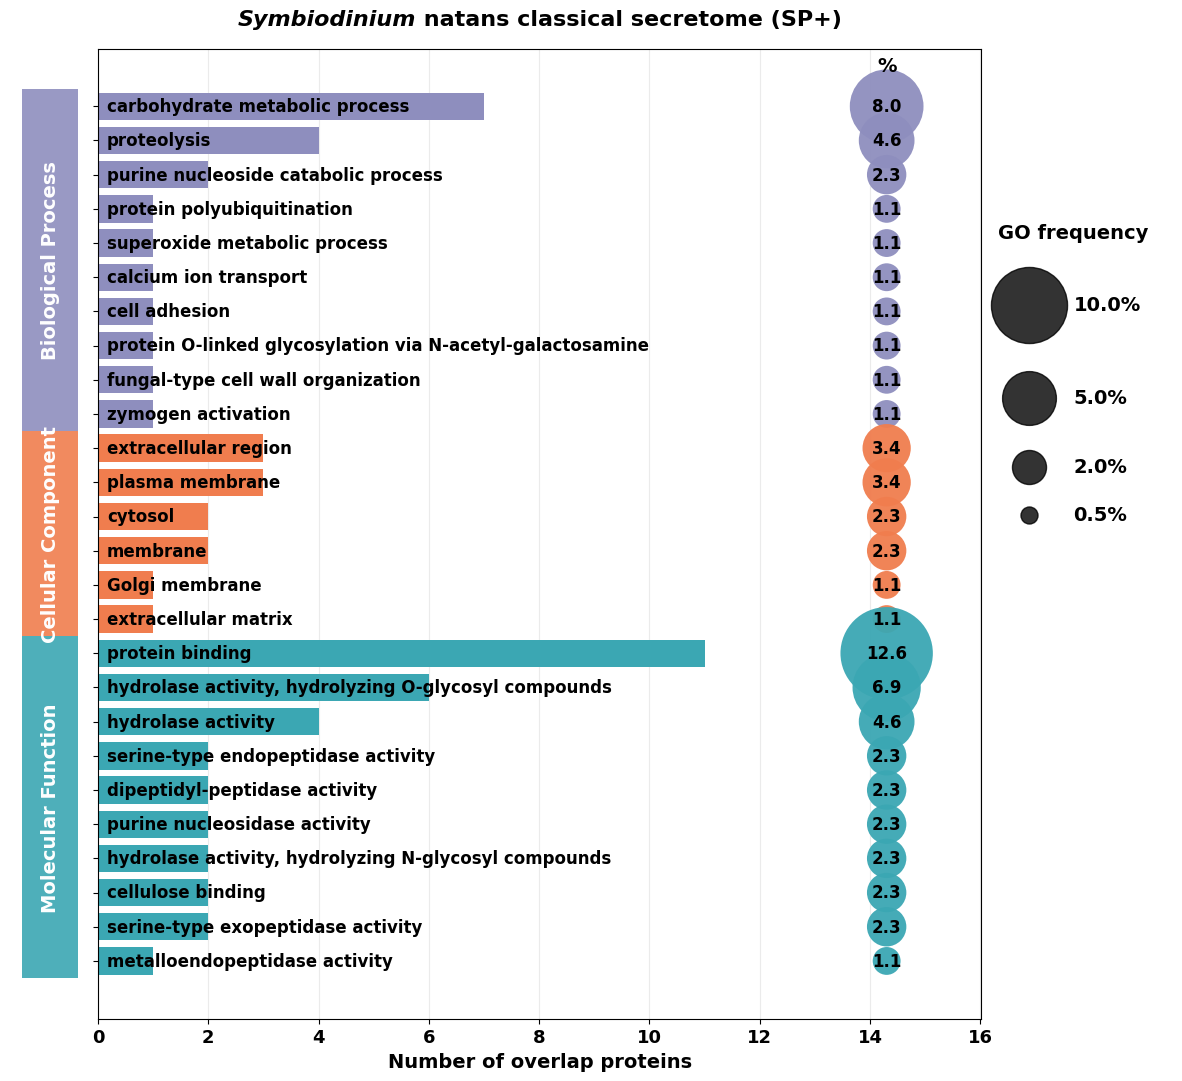

Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/Snat_no_threshold_SPplus_GO_freq .pdf/.svg/.png

SP- — 12 terms across {'Molecular Function': 6, 'Biological Process': 4, 'Cellular Component': 2}


/tmp/ipykernel_1751/935224664.py:243: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


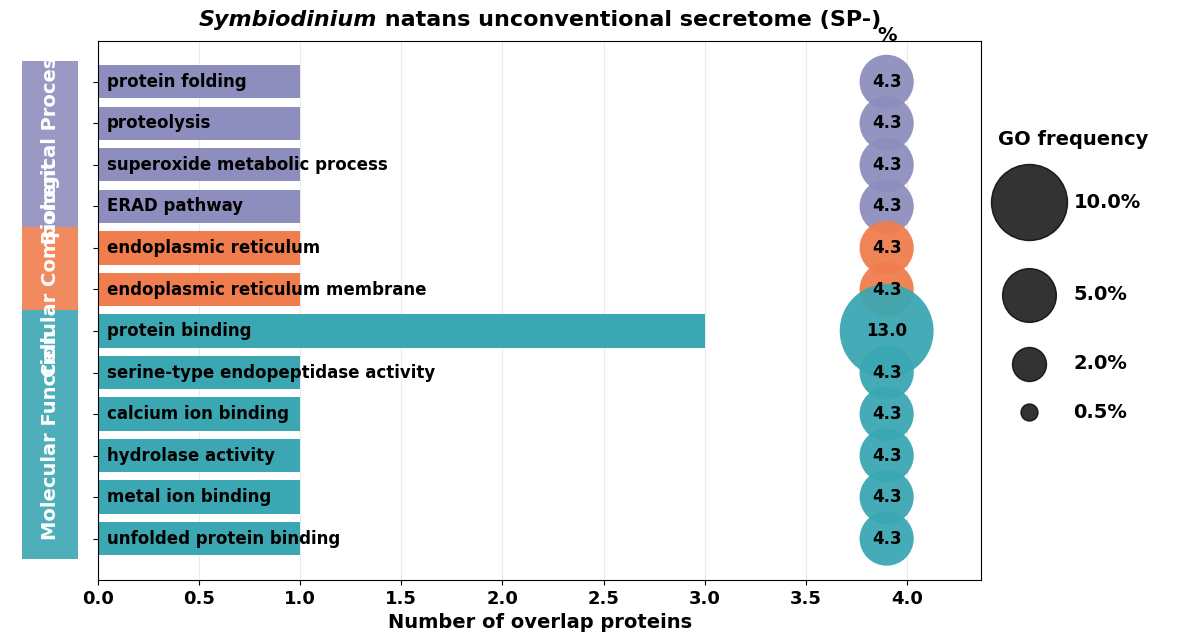

Saved: /content/drive/MyDrive/UTokyo/Proteome/Prediction_vs_Detection/MS_data/*Overlap*/Snat_no_threshold_SPminus_GO_freq .pdf/.svg/.png
Done.


In [ ]:
# =========================================================
# BLOCK: GO frequency dot plot for Snat overlap proteins
# SP+ and SP- as separate figures, same style as Block 3-3
# Uses GO_terms from InterPro in the overlap annotation TSV
# =========================================================

import os, re, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import Rectangle
from goatools.obo_parser import GODag

project_path = os.path.join(base, "Prediction_vs_Detection")
outdir    = os.path.join(project_path, "MS_data", "*Overlap*")
OBO_PATH     = os.path.join(base, "go-basic.obo")

TARGET_STRAIN    = "Snat"
TARGET_THRESHOLD = "no_threshold"
TOP_N_PER_ONTOLOGY = 10
MIN_PROTEIN_COUNT  = 1   # minimum proteins with that GO term to show

# ── Figure style (identical to Block 3-3) ─────────────────
BASE_FIG_W   = 15
MIN_FIG_H    = 6
ROW_H        = 0.40
TITLE_FS     = 16
LABEL_FS     = 14
TERM_FS      = 12
TICK_FS      = 13
BUBBLE_SCALE = 350

ONTO_COLORS = {
    "Biological Process": "#8E8EBE",
    "Cellular Component": "#F07D4E",
    "Molecular Function": "#3BA7B3",
    "NA": "#999999",
}
ONTO_ORDER = ["Biological Process", "Cellular Component", "Molecular Function"]

# ── Helpers ───────────────────────────────────────────────
def ensure_obo(path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return
    for url in ["https://purl.obolibrary.org/obo/go/go-basic.obo",
                "https://raw.githubusercontent.com/geneontology/go-ontology/master/go-basic.obo"]:
        r = subprocess.run(["wget", "-q", "-O", path, url])
        if r.returncode == 0 and os.path.getsize(path) > 1_000_000:
            return
    raise RuntimeError("Could not download go-basic.obo — upload manually.")

def ns_to_full(ns):
    return {"biological_process": "Biological Process",
            "cellular_component": "Cellular Component",
            "molecular_function": "Molecular Function"}.get(ns, "NA")

def build_go_freq_table(ann_df, godag, sp_type):
    sub     = ann_df[ann_df["SP_type"] == sp_type].copy()
    n_total = sub["protein_id"].nunique()

    rows = []
    for _, row in sub.iterrows():
        raw   = str(row.get("GO_terms", "")) if not pd.isna(row.get("GO_terms", np.nan)) else ""
        # split on | or ; (both appear in the stored string)
        parts = re.split(r"[|;]\s*", raw)
        terms = set()
        for p in parts:
            p = p.strip()
            # strip trailing source annotation e.g. (InterPro), (PANTHER)
            p = re.sub(r"\(.*?\)$", "", p).strip()
            if p.startswith("GO:"):
                terms.add(p)
        for t in terms:
            rows.append({"protein_id": row["protein_id"], "GO": t})

    if not rows:
        return pd.DataFrame()

    exp    = pd.DataFrame(rows).drop_duplicates()
    counts = exp.groupby("GO")["protein_id"].nunique().reset_index(name="n_proteins")
    counts = counts[counts["n_proteins"] >= MIN_PROTEIN_COUNT].copy()

    names, ontos = [], []
    for go in counts["GO"]:
        if go in godag:
            names.append(godag[go].name)
            ontos.append(ns_to_full(godag[go].namespace))
        else:
            names.append(go)
            ontos.append("NA")
    counts["Description"] = names
    counts["ONTOLOGY"]    = ontos
    counts["focal_freq"]  = counts["n_proteins"] / n_total
    counts["n_total"]     = n_total
    counts = counts[counts["ONTOLOGY"].isin(ONTO_ORDER)].copy()
    return counts

def pick_top(df, top_n):
    out = []
    for onto in ONTO_ORDER:
        sub = df[df["ONTOLOGY"] == onto].copy()
        if sub.empty: continue
        sub = sub.sort_values(["n_proteins", "focal_freq"],
                              ascending=[False, False]).head(top_n)
        out.append(sub)
    return pd.concat(out, ignore_index=True) if out else df.iloc[0:0]

def plot_go_freq(df_plot, title, sp_label, out_prefix):
    df_plot = df_plot.copy()
    df_plot["freq_pct"] = df_plot["focal_freq"] * 100.0
    df_plot["x"]        = df_plot["n_proteins"].astype(float)

    df_plot["ONTOLOGY"] = pd.Categorical(df_plot["ONTOLOGY"],
                                          categories=ONTO_ORDER, ordered=True)
    df_plot = df_plot.sort_values(["ONTOLOGY", "x", "freq_pct"],
                                   ascending=[True, False, False]).reset_index(drop=True)
    df_plot["y"] = np.arange(len(df_plot))[::-1]

    ranges = []
    for onto in ONTO_ORDER:
        idx = df_plot.index[df_plot["ONTOLOGY"].astype(str) == onto].tolist()
        if not idx: continue
        y0 = df_plot.loc[idx[-1], "y"] - 0.5
        y1 = df_plot.loc[idx[0],  "y"] + 0.5
        ranges.append((onto, y0, y1))

    fig_h = max(MIN_FIG_H, ROW_H * len(df_plot) + 2.2)
    fig = plt.figure(figsize=(BASE_FIG_W, fig_h))
    gs  = gridspec.GridSpec(1, 3, width_ratios=[0.07, 0.77, 0.16], wspace=0.02)

    ax_strip = fig.add_subplot(gs[0, 0])
    ax       = fig.add_subplot(gs[0, 1], sharey=ax_strip)
    ax_leg   = fig.add_subplot(gs[0, 2])
    ax_leg.axis("off")

    bar_colors = [ONTO_COLORS.get(o, ONTO_COLORS["NA"])
                  for o in df_plot["ONTOLOGY"].astype(str)]
    ax.barh(df_plot["y"], df_plot["x"],
            color=bar_colors, edgecolor="none", zorder=2)

    ax.set_yticks(df_plot["y"])
    ax.set_yticklabels([""] * len(df_plot))
    for yy, label in zip(df_plot["y"].values,
                          df_plot["Description"].astype(str)):
        ax.text(0.01, yy, label,
                transform=ax.get_yaxis_transform(),
                ha="left", va="center",
                fontsize=TERM_FS, fontweight="bold", color="black", zorder=3)

    ax.set_xlabel("Number of overlap proteins", fontsize=LABEL_FS, fontweight="bold")
    ax.grid(axis="x", linestyle="-", alpha=0.25, zorder=1)
    ax.set_axisbelow(True)
    for tick in ax.get_xticklabels():
        tick.set_fontsize(TICK_FS); tick.set_fontweight("bold")

    # ── Title with italic genus ────────────────────────────
    m = re.match(r"(.*?)(Symbiodinium|Breviolum|Cladocopium|Durusdinium)(.*)", title)
    if m:
        prefix, genus, rest = m.group(1), m.group(2), m.group(3)
    else:
        prefix, genus, rest = "", title, ""

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    ax_bb    = ax.get_window_extent(renderer=renderer)

    def _w(t_obj):
        return t_obj.get_window_extent(renderer=renderer).width / ax_bb.width

    t_pre = ax.text(0, 1.02, prefix, transform=ax.transAxes,
                    fontsize=TITLE_FS, fontweight="bold", fontstyle="normal",
                    ha="left", va="bottom", clip_on=False, alpha=0)
    t_gen = ax.text(0, 1.02, genus,  transform=ax.transAxes,
                    fontsize=TITLE_FS, fontweight="bold", fontstyle="italic",
                    ha="left", va="bottom", clip_on=False, alpha=0)
    t_rst = ax.text(0, 1.02, rest,   transform=ax.transAxes,
                    fontsize=TITLE_FS, fontweight="bold", fontstyle="normal",
                    ha="left", va="bottom", clip_on=False, alpha=0)

    total_w = _w(t_pre) + _w(t_gen) + _w(t_rst)
    x0 = 0.5 - total_w / 2
    t_pre.set_position((x0,                    1.02)); t_pre.set_alpha(1)
    t_gen.set_position((x0 + _w(t_pre),        1.02)); t_gen.set_alpha(1)
    t_rst.set_position((x0 + _w(t_pre) + _w(t_gen), 1.02)); t_rst.set_alpha(1)

    # ── Bubble column (% frequency) ───────────────────────
    x_max    = float(df_plot["x"].max()) if len(df_plot) else 1.0
    bubble_x = x_max * 1.30
    freqs    = df_plot["freq_pct"].values
    sizes    = freqs * BUBBLE_SCALE

    ax.scatter(np.full(len(df_plot), bubble_x), df_plot["y"].values,
               s=sizes, c=bar_colors, edgecolors="none", alpha=0.95, zorder=3)
    for yy, ff in zip(df_plot["y"].values, freqs):
        ax.text(bubble_x, yy, f"{ff:.1f}",
                va="center", ha="center",
                fontsize=12, fontweight="bold", color="black", zorder=4)
    ax.text(bubble_x, df_plot["y"].max() + 0.9, "%",
            ha="center", va="bottom",
            fontsize=14, fontweight="bold", color="black", zorder=5)
    ax.set_xlim(0, bubble_x * 1.12)

    # ── Ontology strip ────────────────────────────────────
    ax_strip.set_xlim(0, 1)
    ax_strip.tick_params(axis="both", left=False, labelleft=False,
                         bottom=False, labelbottom=False)
    for sp in ax_strip.spines.values():
        sp.set_visible(False)
    for onto, y0, y1 in ranges:
        ax_strip.add_patch(Rectangle(
            (0.15, y0), 0.7, y1 - y0,
            facecolor=ONTO_COLORS.get(onto, ONTO_COLORS["NA"]),
            edgecolor="none", alpha=0.9))
        ax_strip.text(0.5, (y0 + y1) / 2, onto,
                      rotation=90, va="center", ha="center",
                      fontsize=14, fontweight="bold", color="white")

    # ── Legend ────────────────────────────────────────────
    legend_freqs = [0.5, 2.0, 5.0, 10.0]
    fig.canvas.draw()
    ax_h_pts   = ax_leg.get_window_extent().height * 72.0 / fig.dpi
    items      = [(v, v * 300, np.sqrt(v * 300 / np.pi)) for v in legend_freqs]
    items.sort(key=lambda x: x[0], reverse=True)
    y_top_pts  = 0.78 * ax_h_pts
    y_frac_pos = []
    y = y_top_pts
    for val, s_area, rad in items:
        y_frac_pos.append((y - rad) / ax_h_pts)
        y = y - rad * 2 - 14

    ax_leg.text(0.05, 0.80, "GO frequency",
                transform=ax_leg.transAxes,
                ha="left", va="bottom", fontsize=14, fontweight="bold")
    for (val, s_area, _), yf in zip(items, y_frac_pos):
        ax_leg.scatter([0.22], [yf], s=s_area, color="black", alpha=0.8,
                       transform=ax_leg.transAxes)
        ax_leg.text(0.46, yf, f"{val:.1f}%",
                    transform=ax_leg.transAxes,
                    ha="left", va="center",
                    fontsize=14, fontweight="bold", color="black")

    fig.tight_layout()
    for ext, dpi in [("pdf", None), ("svg", None), ("png", 600)]:
        kw = {"dpi": dpi} if dpi else {}
        fig.savefig(f"{out_prefix}.{ext}", bbox_inches="tight", **kw)
    plt.show()
    plt.close(fig)
    print(f"Saved: {out_prefix} .pdf/.svg/.png")

# ── Main ──────────────────────────────────────────────────
ensure_obo(OBO_PATH)
godag = GODag(OBO_PATH, optional_attrs=["namespace", "name"])

if TARGET_THRESHOLD == "no_threshold":
    ann_file = os.path.join(outdir,
        f"{TARGET_STRAIN}_overlap_no_threshold_annotated.tsv")
else:
    ann_file = os.path.join(outdir,
        f"{TARGET_STRAIN}_overlap_{TARGET_THRESHOLD}_annotated.tsv")

ann = pd.read_csv(ann_file, sep="\t", low_memory=False)
print(f"Loaded {len(ann):,} proteins  "
      f"SP+={( ann['SP_type']=='SP+').sum():,}  "
      f"SP-={(ann['SP_type']=='SP-').sum():,}")

SPECIES = {"Smic": "Symbiodinium microadriaticum",
           "Snat": "Symbiodinium natans",
           "Bmin": "Breviolum minutum"}

for sp_type, sp_label in [("SP+", "classical secretome (SP+)"),
                           ("SP-", "unconventional secretome (SP-)")]:

    freq_df = build_go_freq_table(ann, godag, sp_type)
    if freq_df.empty:
        print(f"[WARN] No GO terms for {TARGET_STRAIN} {sp_type} — skipping")
        continue

    plot_df = pick_top(freq_df, TOP_N_PER_ONTOLOGY)

    # Save table
    tbl_out = os.path.join(outdir,
        f"{TARGET_STRAIN}_{TARGET_THRESHOLD}_{sp_type.replace('+','plus').replace('-','minus')}_GO_freq.tsv")
    plot_df.to_csv(tbl_out, sep="\t", index=False)
    print(f"\n{sp_type} — {len(plot_df)} terms across "
          f"{plot_df['ONTOLOGY'].value_counts().to_dict()}")

    title = f"{SPECIES[TARGET_STRAIN]} {sp_label}"
    prefix = os.path.join(outdir,
        f"{TARGET_STRAIN}_{TARGET_THRESHOLD}_{sp_type.replace('+','plus').replace('-','minus')}_GO_freq")

    plot_go_freq(plot_df, title, sp_type, prefix)

print("Done.")

In [ ]:
# ── GO terms diagnostic ───────────────────────────────────

print("=== Checking GO_terms column in annotation table ===\n")

# 1. What does the column look like?
print(f"Column exists: {'GO_terms' in ann.columns}")
print(f"Non-null rows: {ann['GO_terms'].notna().sum()} / {len(ann)}")
print(f"Non-empty rows: {(ann['GO_terms'].fillna('').str.strip() != '').sum()} / {len(ann)}")

print("\nFirst 10 raw GO_terms values:")
for i, v in enumerate(ann["GO_terms"].fillna("").head(10)):
    print(f"  {repr(v)}")

# 2. Check the raw InterPro file for Snat directly
ipr_path = ANNOT["Snat"]["interpro"]
ipr_raw  = pd.read_csv(ipr_path, sep="\t", header=None,
                        names=["protein_id","md5","length","analysis",
                               "accession","description","start","end",
                               "evalue","status","date",
                               "ipr_accession","ipr_description","GO","pathway"],
                        usecols=range(15), low_memory=False, on_bad_lines="skip")

print(f"\n=== Raw InterPro file ===")
print(f"Total rows: {len(ipr_raw):,}")
print(f"Rows with GO terms: {ipr_raw['GO'].notna().sum():,}")
print(f"Non-empty GO: {(ipr_raw['GO'].fillna('').str.strip() != '').sum():,}")
print("\nFirst 10 raw GO column values:")
for v in ipr_raw["GO"].fillna("").head(10):
    print(f"  {repr(v)}")

# 3. Check a specific protein that is in the overlap
sample_id = ann["protein_id"].dropna().iloc[0]
print(f"\n=== InterPro rows for sample protein: {sample_id} ===")
ipr_raw["protein_id_clean"] = ipr_raw["protein_id"].map(clean_protein_id)
hits = ipr_raw[ipr_raw["protein_id_clean"] == sample_id]
print(f"Rows found: {len(hits)}")
if not hits.empty:
    print(hits[["protein_id_clean", "analysis", "ipr_accession",
                "ipr_description", "GO"]].to_string(index=False))

=== Checking GO_terms column in annotation table ===

Column exists: True
Non-null rows: 44 / 110
Non-empty rows: 44 / 110

First 10 raw GO_terms values:
  'GO:0005515(InterPro)|GO:0005576(InterPro)|GO:0006508(InterPro)'
  ''
  'GO:0004553(InterPro)|GO:0005975(InterPro); GO:0005576(InterPro)|GO:0005975(InterPro)|GO:0030248(InterPro)'
  ''
  ''
  ''
  ''
  ''
  'GO:0005261(PANTHER)|GO:0005886(PANTHER)|GO:0006816(PANTHER)'
  'GO:0016787(InterPro)'

=== Raw InterPro file ===
Total rows: 246,218
Rows with GO terms: 246,218
Non-empty GO: 246,218

First 10 raw GO column values:
  '-'
  '-'
  'GO:0005515(InterPro)'
  'GO:0005515(InterPro)'
  '-'
  '-'
  'GO:0005515(InterPro)'
  'GO:0005515(InterPro)'
  '-'
  '-'

=== InterPro rows for sample protein: CAE6916755.1 ===
Rows found: 3
protein_id_clean    analysis ipr_accession ipr_description                                                             GO
    CAE6916755.1      Gene3D             -               -                                   

## Visualization for overlaps

Mapped completeness (overlap proteins → final annotation):
  Smic : 4/4 mapped
  Snat : 110/110 mapped
  Bmin : 12/12 mapped
Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/data_pre/ALL_overlap_mapped_final_annotations.tsv
Smic: 7 Pfam domains plotted
Snat: 30 Pfam domains plotted
Bmin: 20 Pfam domains plotted


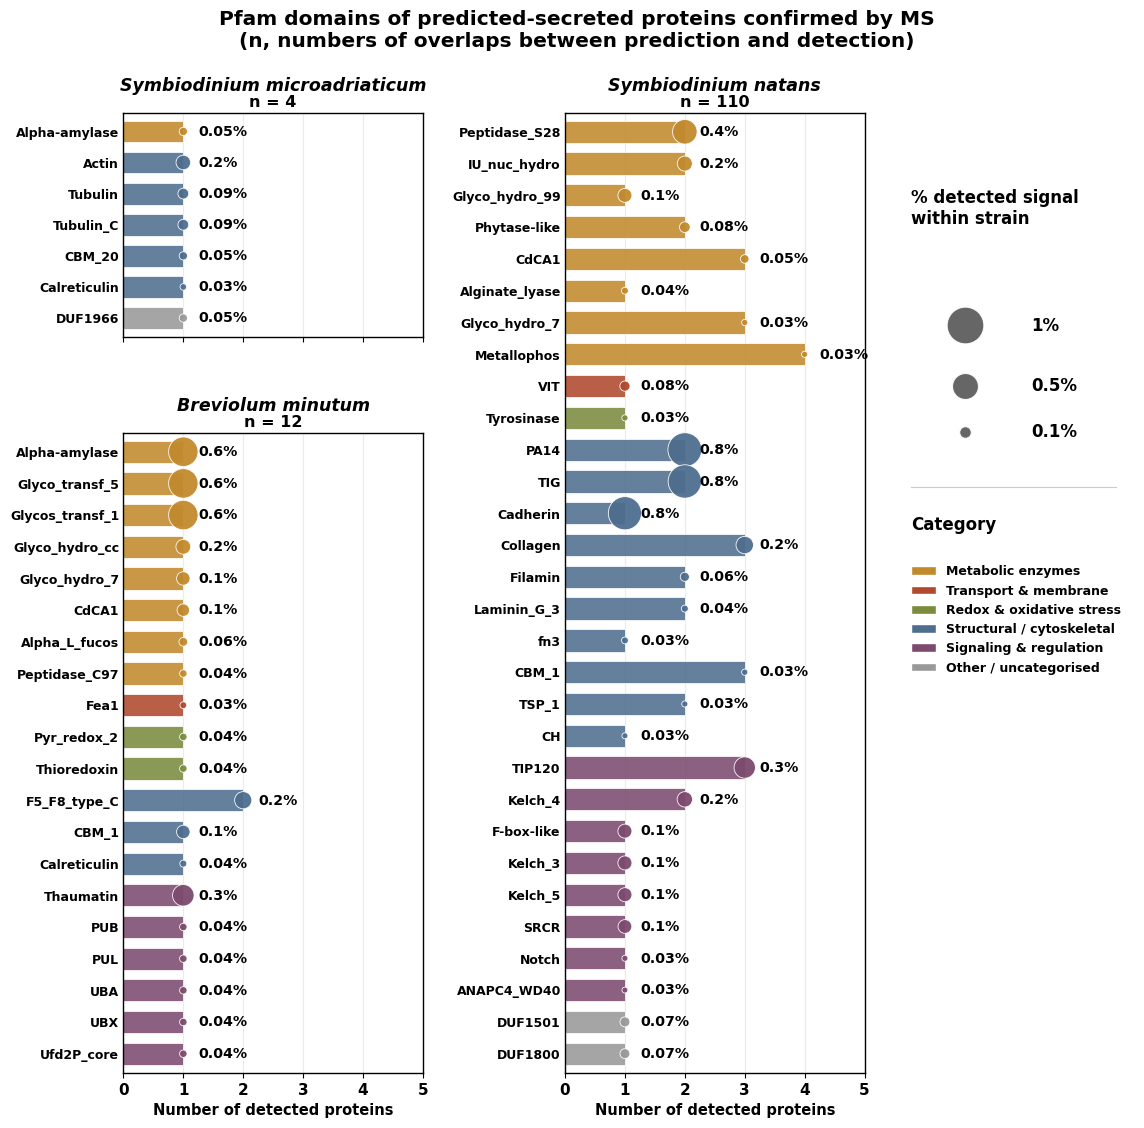

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/ALL_overlap_Pfam_perstrain .pdf/.svg/.png
Matched old effective subplot width: 3.00 inches


In [3]:
# ============================================================
# OVERLAP (predicted ∩ MS-detected) → Pfam panels, custom layout
#   Layout:  Smic (top-left) + Bmin (bottom-left) stacked;
#            Snat = tall full-height panel on the right.
#   Content: ALL Pfam domains for Smic and Bmin; TOP 50 for Snat.
#   Bar    = number of overlap proteins carrying the domain
#   Bubble = % within-strain detected signal (abundance fraction)
#   Bars are a uniform thickness across panels (row-proportional heights).
#   Assumes `base` is already defined.
# ============================================================

import os, glob, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ── paths ─────────────────────────────────────────────────
MS_DATA      = os.path.join(base, "Prediction_vs_Detection", "MS_data")
OVERLAP_GLOB = os.path.join(MS_DATA, "*Overlap*", "ALL_overlap_no_threshold_annotated.tsv")
MS_PATH      = os.path.join(base, "Publication", "data_pre", "ALL_MS_detected_annotated.tsv")
MAPPED_OUT   = os.path.join(base, "Publication", "data_pre", "ALL_overlap_mapped_final_annotations.tsv")
FIGDIR       = os.path.join(base, "Publication", "figures_pre")
os.makedirs(FIGDIR, exist_ok=True)
os.makedirs(os.path.dirname(MAPPED_OUT), exist_ok=True)

ov_files = glob.glob(OVERLAP_GLOB)
assert ov_files, f"overlap file not found: {OVERLAP_GLOB}"
OVERLAP_PATH = ov_files[0]

STRAINS = ["Smic", "Snat", "Bmin"]
SPECIES = {"Smic": "Symbiodinium microadriaticum",
           "Snat": "Symbiodinium natans",
           "Bmin": "Breviolum minutum"}
PER_STRAIN_TOP    = {"Smic": None, "Snat": 30, "Bmin": None}   # None = all domains
MIN_PROTEIN_COUNT = 1
MIN_GAP_ROWS      = 8     # vertical gap (legend lives here) between Smic and Bmin

ABUND_RE = re.compile(r"^Abundance(s)?:", re.I)

def clean_protein_id(x):
    if pd.isna(x): return None
    s = str(x).strip().split()[0]
    if s.startswith("jgi_"):
        s = s.replace("_", "|", 3)
    if s.startswith("symbB"):
        s = s.replace("\\", "")
    return s

def pick_abund_col(df):
    cols = [c for c in df.columns if ABUND_RE.search(str(c)) and "Count" not in str(c)]
    return cols[0] if cols else None

# ============================================================
# STEP 1 + 2 — extract overlap IDs and map to final annotations
# ============================================================
ov = pd.read_csv(OVERLAP_PATH, sep="\t", dtype=str)
ms = pd.read_csv(MS_PATH,      sep="\t", dtype=str)

def _norm(s):
    return str(s).strip().replace("\\", "") if pd.notna(s) else ""

def join_key(strain, s):
    s = _norm(s)
    return s.split("|")[0] if strain == "Bmin" else s

ov["_key"] = [join_key(st, pid) for st, pid in zip(ov["strain"], ov["protein_id"])]
ms_src = ms["annot_id"].where(ms["strain"] == "Snat", ms["protein_id"])
ms["_key"] = [join_key(st, s) for st, s in zip(ms["strain"], ms_src)]
ms_u = ms.drop_duplicates(subset=["strain", "_key"], keep="first")

final_cols = ["protein_id", "annot_id", "eggnog_gene_name", "eggnog_description",
              "COG_category", "eggnog_OGs", "KEGG_ko", "Pfam", "eggnog_GO",
              "interpro_accessions", "interpro_descriptions", "GO_terms"]
ms_keep = ms_u[["strain", "_key"] + final_cols].rename(
    columns={c: f"final_{c}" for c in final_cols})
left = ov[["strain", "threshold", "protein_id", "SP_type", "_key"]].rename(
    columns={"protein_id": "overlap_protein_id"})
merged = left.merge(ms_keep, on=["strain", "_key"], how="left").drop(columns="_key")
merged.to_csv(MAPPED_OUT, sep="\t", index=False)

print("Mapped completeness (overlap proteins → final annotation):")
for s in STRAINS:
    sub = merged[merged.strain == s]
    print(f"  {s:5s}: {sub['final_protein_id'].notna().sum()}/{len(sub)} mapped")
print("Saved:", MAPPED_OUT)

# ============================================================
# STEP 3 — within-strain abundance fraction (full-proteome denominator)
# ============================================================
def load_abund(strain):
    hits = glob.glob(os.path.join(MS_DATA, "**", f"{strain}_MS_mapped.tsv"), recursive=True)
    if not hits:
        print(f"  [warn] no {strain}_MS_mapped.tsv found → bubbles = 0 for {strain}")
        return {}
    m = pd.read_csv(hits[0], sep="\t", low_memory=False)
    acol = pick_abund_col(m)
    if acol is None or "ms_id_raw" not in m.columns:
        print(f"  [warn] {strain}: no abundance/ms_id_raw column → bubbles = 0")
        return {}
    m["__key"] = m["ms_id_raw"].map(clean_protein_id)
    m["__ab"]  = pd.to_numeric(m[acol], errors="coerce").clip(lower=0)
    total = m["__ab"].sum(skipna=True)
    per = m.groupby("__key")["__ab"].sum()
    return ((per / total) if total else per * 0.0).to_dict()

abund = {s: load_abund(s) for s in STRAINS}

# ============================================================
# STEP 4 — Pfam → category, build per-strain tables
# ============================================================
CAT_ORDER = ["Metabolic enzymes", "Transport & membrane",
             "Redox & oxidative stress", "Structural / cytoskeletal",
             "Signaling & regulation", "Other / uncategorised"]
PFAM_CAT_COLORS = {
    "Metabolic enzymes":         "#C28A2D",
    "Transport & membrane":      "#B0492E",
    "Redox & oxidative stress":  "#7A8B3E",
    "Structural / cytoskeletal": "#4E6E8E",
    "Signaling & regulation":    "#7C4A6E",
    "Other / uncategorised":     "#999999",
}

CATEGORY_BY_ID = {
    # --- Metabolic enzymes ---
    "Peptidase_C1": "Metabolic enzymes", "Peptidase_C2": "Metabolic enzymes",
    "Peptidase_C10": "Metabolic enzymes", "Peptidase_C97": "Metabolic enzymes",
    "Peptidase_M14": "Metabolic enzymes", "Peptidase_M43": "Metabolic enzymes",
    "Peptidase_S28": "Metabolic enzymes", "Asp": "Metabolic enzymes",
    "DNase_II": "Metabolic enzymes", "Reprolysin_4": "Metabolic enzymes",
    "Inhibitor_I69": "Metabolic enzymes", "Enolase_C": "Metabolic enzymes",
    "Enolase_N": "Metabolic enzymes", "Beta_helix": "Metabolic enzymes",
    "Gp_dh_C": "Metabolic enzymes", "Gp_dh_N": "Metabolic enzymes",
    "Sacchrp_dh_NADP": "Metabolic enzymes", "RuBisCO_large": "Metabolic enzymes",
    "RuBisCO_large_N": "Metabolic enzymes", "AMP-binding": "Metabolic enzymes",
    "GTP_EFTU": "Metabolic enzymes", "GTP_EFTU_D2": "Metabolic enzymes",
    "GTP_EFTU_D3": "Metabolic enzymes", "Alpha-amylase": "Metabolic enzymes",
    "Glyco_hydro_7": "Metabolic enzymes", "Glyco_hydro_2_C": "Metabolic enzymes",
    "Glyco_hydro_53": "Metabolic enzymes", "Glyco_hydro_cc": "Metabolic enzymes",
    "Metallophos": "Metabolic enzymes", "IU_nuc_hydro": "Metabolic enzymes",
    "Glyco_transf_5": "Metabolic enzymes", "Glycos_transf_1": "Metabolic enzymes",
    "CdA1": "Metabolic enzymes",
    "Alpha_L_fucos": "Metabolic enzymes",
    "Alginate_lyase": "Metabolic enzymes",
    "Phytase-like": "Metabolic enzymes",
    "CdCA1": "Metabolic enzymes",
    "Carbonic_anh_delta": "Metabolic enzymes",
    "GRDP-like": "Metabolic enzymes",        # Phenylacetate-CoA ligase associated
    "DUF1966": "Metabolic enzymes",          # Alpha-amylase domain variant
    "Inhibitor_I9": "Metabolic enzymes",     # Subtilisin propeptide inhibitor
    "Isochorismatase": "Metabolic enzymes",  # Isochorismatase hydrolase core
    "LPMO_10": "Metabolic enzymes",          # Lytic polysaccharide monooxygenase (AA10)
    "PA": "Metabolic enzymes",               # Protease-associated domain (Subtilisin)
    "PAE": "Metabolic enzymes",              # Pectinacetylesterase
    "PPC": "Metabolic enzymes",              # Peptidase C-terminal control domain
    "Pep_M12B_propep": "Metabolic enzymes",  # Reprolysin metalloprotease propeptide
    "Reprolysin": "Metabolic enzymes",       # Catalytic metallopeptidase
    "Trypsin": "Metabolic enzymes",          # Serine protease domain

    # --- Transport & membrane ---
    "ABC_tran": "Transport & membrane", "ABC_membrane": "Transport & membrane",
    "TIP12": "Transport & membrane",
    "Fea1": "Transport & membrane",
    "VIT": "Transport & membrane",
    "PD40": "Transport & membrane",          # Type IV secretion system component

    # --- Redox & oxidative stress ---
    "Sod_Fe_C": "Redox & oxidative stress", "Sod_Fe_N": "Redox & oxidative stress",
    "HSP70": "Redox & oxidative stress", "Thioredoxin": "Redox & oxidative stress",
    "Pyr_redox_2": "Redox & oxidative stress",
    "Tyrosinase": "Redox & oxidative stress",

    # --- Structural / cytoskeletal ---
    "Tubulin": "Structural / cytoskeletal", "Tubulin_C": "Structural / cytoskeletal",
    "Actin": "Structural / cytoskeletal", "TIG": "Structural / cytoskeletal",
    "fn3": "Structural / cytoskeletal", "G8": "Structural / cytoskeletal",
    "PA14": "Structural / cytoskeletal", "LLectin_C": "Structural / cytoskeletal",
    "RicinB_lectin_2": "Structural / cytoskeletal", "Sushi": "Structural / cytoskeletal",
    "Cohesin": "Structural / cytoskeletal", "Cadherin": "Structural / cytoskeletal",
    "Collagen": "Structural / cytoskeletal", "CBM_1": "Structural / cytoskeletal",
    "CBM_3": "Structural / cytoskeletal", "CBM_X2": "Structural / cytoskeletal",
    "CBM_20": "Structural / cytoskeletal", "Laminin_G_3": "Structural / cytoskeletal",
    "Calreticulin": "Structural / cytoskeletal", "Fibrinogen_C": "Structural / cytoskeletal",
    "F5_F8_type_C": "Structural / cytoskeletal", "Filamin": "Structural / cytoskeletal",
    "Big_4": "Structural / cytoskeletal",
    "MAM": "Structural / cytoskeletal",
    "TSP_1": "Structural / cytoskeletal",
    "CH": "Structural / cytoskeletal",             # Calponin Homology actin-binding
    "Chitin_bind_1": "Structural / cytoskeletal",  # Non-catalytic chitin binding module
    "DUF3338": "Structural / cytoskeletal",        # Validated actin-binding domain
    "FERM_C": "Structural / cytoskeletal",         # Cytoskeletal membrane anchor components
    "FERM_M": "Structural / cytoskeletal",
    "FERM_N": "Structural / cytoskeletal",
    "Ldl_recept_a": "Structural / cytoskeletal",   # Extracellular matrix ligand-binding repeat
    "X8": "Structural / cytoskeletal",             # Glucanase carbohydrate-binding module

    # --- Signaling & regulation ---
    "Pkinase": "Signaling & regulation", "cNMP_binding": "Signaling & regulation",
    "PP2C": "Signaling & regulation", "EF-hand_1": "Signaling & regulation",
    "EF-hand_5": "Signaling & regulation", "EF-hand_7": "Signaling & regulation",
    "Annexin": "Signaling & regulation", "I-set": "Signaling & regulation",
    "PKD_channel": "Signaling & regulation",
    "Thaumatin": "Signaling & regulation",
    "UBA": "Signaling & regulation",
    "UBX": "Signaling & regulation",
    "PUB": "Signaling & regulation",
    "PUL": "Signaling & regulation",
    "Ufd2P_core": "Signaling & regulation",
    "TIP120": "Signaling & regulation",
    "F-box-like": "Signaling & regulation",
    "Kelch_3": "Signaling & regulation",
    "Kelch_4": "Signaling & regulation",
    "Kelch_5": "Signaling & regulation",
    "SRCR": "Signaling & regulation",
    "Notch": "Signaling & regulation",
    "Ank_2": "Signaling & regulation",         # Ankyrin repeat signaling scaffolds
    "Ank_5": "Signaling & regulation",
    "ArfGap": "Signaling & regulation",        # Small GTPase regulator
    "BAR_3": "Signaling & regulation",         # Membrane curvature trafficking sensor
    "Ephrin_rec_like": "Signaling & regulation",# Receptor signaling architecture
    "FG-GAP_2": "Signaling & regulation",      # Receptor signaling interaction module
    "GPS": "Signaling & regulation",           # GPCR proteolysis signaling element
    "HemolysinCabind": "Signaling & regulation",# RTX toxin type calcium-binding loop
    "ILEI": "Signaling & regulation",          # Interleukin-like signaling peptide
    "NHL": "Signaling & regulation",           # E3 ligase recognition fold
    "PH": "Signaling & regulation",            # Pleckstrin homology signaling domain
    "PilJ": "Signaling & regulation",          # Chemotaxis regulatory transducer
    "REJ": "Signaling & regulation",           # Receptor for Egg Jelly (Polycystin loop)
    "TIR_2": "Signaling & regulation",         # Toll-Interleukin receptor immune module

    # --- Other / uncategorised ---
    "DUF5011": "Other / uncategorised", "DUF1966": "Other / uncategorised",
    "DUF1501": "Other / uncategorised",
    "DUF1800": "Other / uncategorised",
    "DUF305": "Other / uncategorised",
    "DUF4347": "Other / uncategorised",
    "Endotoxin_C": "Other / uncategorised",    # Delta endotoxin components
    "Endotoxin_N": "Other / uncategorised",
    "SBBP": "Other / uncategorised",           # Surface binding protein variant
    "YHYH": "Other / uncategorised",           # Uncharacterized extracellular module
}

CATEGORY_KEYWORDS = [
    ("Metabolic enzymes", [r"peptidase", r"protease", r"hydrolase", r"esterase",
        r"lipase", r"chitinase", r"glycos[iy]l", r"glyco_hydro", r"glyco_transf",
        r"amylase", r"transferase", r"isomerase", r"synthase", r"dehydrogenase",
        r"phosphatase", r"phospho", r"ligase", r"reductase(?!.*oxido)",
        r"rubisco", r"amp-binding", r"dnase", r"gtp_eftu", r"enolase", r"nuc_hydro",
        r"lyase", r"deacetylase", r"fucos", r"phytase", r"carbonic_anh", r"trypsin",
        r"lpmo", r"isochorismatase"]),

    ("Transport & membrane", [r"transport", r"channel", r"permease", r"abc[-_ ]?",
        r"slc[-_ ]?", r"mfs", r"porin", r"translocon", r"membrane", r"vit\b", r"fea1",
        r"secretion", r"pd40"]),

    ("Redox & oxidative stress", [r"peroxid", r"thiored", r"glutaredox", r"\bsod\b",
        r"sod_fe", r"oxidoreductase", r"superoxide", r"catalase", r"glutathione",
        r"hsp70", r"heat shock", r"pyr_redox", r"tyrosinase"]),

    ("Structural / cytoskeletal", [r"actin", r"tubulin", r"myosin", r"kinesin",
        r"collagen", r"egf", r"laminin", r"fibronectin", r"fibrinogen", r"fn3",
        r"cilium", r"flagell", r"cadherin", r"cohesin", r"lectin", r"\bg8\b",
        r"tig", r"pa14", r"cbm", r"sushi", r"calreticulin", r"ricin", r"filamin",
        r"mam\b", r"tsp[-_ ]?1", r"thrombospondin", r"ferm", r"chitin[-_ ]?bind", r"\bx8\b"]),

    ("Signaling & regulation", [r"kinase", r"pp2c", r"gpcr", r"7tm", r"calmodul",
        r"calcium[-_ ]?binding", r"ef[-_ ]?hand", r"receptor", r"sh[23]",
        r"ph domain", r"wd40", r"ankyrin", r"tpr", r"cnmp", r"annexin", r"i-set",
        r"pkd", r"thaumatin", r"ubiquitin", r"\buba\b", r"\bubx\b", r"\bpub\b",
        r"\bpul\b", r"ufd2p", r"f[-_ ]?box", r"kelch", r"tip120", r"srcr", r"notch",
        r"arfgap", r"\bbar\b", r"ilei", r"chemotaxis", r"pilj", r"\btir\b"])
]

def parse_eggnog_pfam(cell):
    if pd.isna(cell): return []
    s = str(cell).strip()
    if s in ("", "-"): return []
    return [t.strip() for t in s.split(",") if t.strip() and t.strip() != "-"]

def assign_category(name):
    k = str(name or "").strip()
    if k in CATEGORY_BY_ID:
        return CATEGORY_BY_ID[k]
    low = {kk.lower(): v for kk, v in CATEGORY_BY_ID.items()}
    if k.lower() in low:
        return low[k.lower()]
    for cat, pats in CATEGORY_KEYWORDS:
        if any(re.search(p, k, flags=re.I) for p in pats):
            return cat
    return "Other / uncategorised"

def strain_table(strain, top_n):
    sub = merged[merged.strain == strain].copy()
    sub["__key"] = sub["final_protein_id"].map(clean_protein_id)
    ab = abund.get(strain, {})
    rows = []
    for _, r in sub.iterrows():
        af = ab.get(r["__key"], 0.0)
        for nm in set(parse_eggnog_pfam(r.get("final_Pfam"))):
            rows.append({"protein": r["__key"], "Pfam": nm, "abund_frac": af})
    if not rows:
        return pd.DataFrame()
    long = pd.DataFrame(rows).drop_duplicates(["protein", "Pfam"])
    cnt = (long.groupby("Pfam")
                .agg(n_proteins=("protein", "nunique"),
                     sum_abund_frac=("abund_frac", "sum"))
                .reset_index())
    cnt = cnt[cnt["n_proteins"] >= MIN_PROTEIN_COUNT].copy()
    cnt["category"] = cnt["Pfam"].map(assign_category)
    cnt["category"] = pd.Categorical(cnt["category"], categories=CAT_ORDER, ordered=True)
    if top_n is not None:
        cnt = cnt.sort_values(["sum_abund_frac", "n_proteins"],
                              ascending=[False, False]).head(top_n)
    cnt = cnt.sort_values(["category", "sum_abund_frac", "n_proteins"],
                          ascending=[True, False, False]).reset_index(drop=True)
    return cnt

per_strain = {s: strain_table(s, PER_STRAIN_TOP[s]) for s in STRAINS}
n_overlap  = {s: len(merged[merged.strain == s]) for s in STRAINS}
n_smic, n_bmin, n_snat = (len(per_strain["Smic"]), len(per_strain["Bmin"]),
                          len(per_strain["Snat"]))
for s in STRAINS:
    print(f"{s}: {len(per_strain[s])} Pfam domains plotted")

# ============================================================
# STEP 5 — figure: previous 3-column subplot width + right legend
# ============================================================
plt.rcParams.update({
    "font.size": 11,
    "font.family": "DejaVu Sans",
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

# ── adaptive bubble-size ladder ─────────────────────────────
max_pct = max(
    (t["sum_abund_frac"].max() * 100 for t in per_strain.values() if not t.empty),
    default=10.0
)

LEGEND_PRESETS = {
    1:  [1, 0.5, 0.1],
    2:  [2, 1, 0.2],
    3:  [3, 1.5, 0.3],
    5:  [5, 2, 0.5],
    8:  [8, 4, 1],
    10: [10, 5, 1],
    12: [12, 6, 1],
    15: [15, 8, 2],
    20: [20, 10, 2],
    25: [25, 12, 3],
    30: [30, 15, 3],
    40: [40, 20, 5],
    50: [50, 25, 5]
}

legend_top  = next((v for v in sorted(LEGEND_PRESETS) if v >= max_pct), 50)
legend_vals = LEGEND_PRESETS[legend_top]
BUBBLE_SCALE = 700.0 / max(legend_vals)

# ── shared x-range across panels ────────────────────────────
xmax = max(
    (int(t["n_proteins"].max()) for t in per_strain.values() if not t.empty),
    default=1
)

# Larger x padding because now every bubble gets a number label
xpad = max(1, int(np.ceil(xmax * 0.18)))

# ── row grid: uniform bar thickness ─────────────────────────
LEFT_PANEL_GAP_ROWS = 2

n_smic_r = max(n_smic, 1)
n_bmin_r = max(n_bmin, 1)
n_snat_r = max(n_snat, 1)

left_rows = n_smic_r + LEFT_PANEL_GAP_ROWS + n_bmin_r
grid_rows = max(n_snat_r, left_rows)

gap_rows = max(LEFT_PANEL_GAP_ROWS, grid_rows - n_smic_r - n_bmin_r)
snat_pad = max(0, grid_rows - n_snat_r)

# ── match the previous 3-column subplot width ───────────────
# Previous plot settings:
#   PANEL_W = 4.7
#   fig_w = PANEL_W * 3 + 2.3
#   width_ratios = [1.0, 1.0, 1.0, 0.45]
#   wspace = 0.55
#   left = 0.08, right = 0.97
#
# This calculates the actual old data-axis width in inches.
OLD_PANEL_W      = 4.7
OLD_FIG_W        = OLD_PANEL_W * 3 + 2.3
OLD_LEFT         = 0.08
OLD_RIGHT        = 0.97
OLD_WSPACE       = 0.55
OLD_WIDTH_RATIOS = [1.0, 1.0, 1.0, 0.45]

old_usable_w = (OLD_RIGHT - OLD_LEFT) * OLD_FIG_W
old_mean_ratio = np.mean(OLD_WIDTH_RATIOS)
old_unit_w = old_usable_w / (
    sum(OLD_WIDTH_RATIOS)
    + OLD_WSPACE * (len(OLD_WIDTH_RATIOS) - 1) * old_mean_ratio
)

DATA_COL_W = old_unit_w                 # ≈ 3.0 inches, same as previous real subplot width
COL_GAP_W  = OLD_WSPACE * old_mean_ratio * old_unit_w
LEG_GAP_W  = 0.35
LEGEND_COL_W = 2.35

LEFT_MARGIN_W  = 1.25
RIGHT_MARGIN_W = 0.20

ROW_INCH = 0.32
TOP_H    = 1.25
BOTTOM_H = 1.00

X_AXIS_MAX = max(xmax + 1, 5)

fig_w = (
    LEFT_MARGIN_W
    + DATA_COL_W
    + COL_GAP_W
    + DATA_COL_W
    + LEG_GAP_W
    + LEGEND_COL_W
    + RIGHT_MARGIN_W
)

fig_h = grid_rows * ROW_INCH + TOP_H + BOTTOM_H

fig = plt.figure(figsize=(fig_w, fig_h))

outer = gridspec.GridSpec(
    1, 5,
    width_ratios=[DATA_COL_W, COL_GAP_W, DATA_COL_W, LEG_GAP_W, LEGEND_COL_W],
    wspace=0.0,
    left=LEFT_MARGIN_W / fig_w,
    right=1 - RIGHT_MARGIN_W / fig_w,
    top=1 - TOP_H / fig_h,
    bottom=BOTTOM_H / fig_h
)

# Left stacked panels: Smic / gap / Bmin
gl = gridspec.GridSpecFromSubplotSpec(
    3, 1,
    subplot_spec=outer[0, 0],
    height_ratios=[n_smic_r, gap_rows, n_bmin_r],
    hspace=0.0
)

ax_smic = fig.add_subplot(gl[0])
ax_gap  = fig.add_subplot(gl[1])
ax_gap.axis("off")
ax_bmin = fig.add_subplot(gl[2])

# Right tall Snat panel
if snat_pad > 0:
    gr = gridspec.GridSpecFromSubplotSpec(
        2, 1,
        subplot_spec=outer[0, 2],
        height_ratios=[n_snat_r, snat_pad],
        hspace=0.0
    )
    ax_snat = fig.add_subplot(gr[0])
else:
    ax_snat = fig.add_subplot(outer[0, 2])

# Right-side legend
ax_leg = fig.add_subplot(outer[0, 4])
ax_leg.axis("off")


def fmt_pct(p):
    """Show all bubble percentage labels, including very small values."""
    if not np.isfinite(p):
        return "0%"
    if p == 0:
        return "0%"
    if p < 0.1:
        return f"{p:.2f}%"
    return f"{p:.1f}%"


def draw_panel(ax, strain, show_xaxis):
    tbl = per_strain[strain]
    nr  = max(len(tbl), 1)

    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_linewidth(1.0)

    ax.set_title(
        SPECIES[strain],
        fontsize=12.5,
        fontweight="bold",
        fontstyle="italic",
        color="black",
        pad=16
    )

    ax.annotate(
        f"n = {n_overlap[strain]}",
        xy=(0.5, 1.0),
        xytext=(0, 2),
        xycoords="axes fraction",
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11.5,
        fontweight="bold",
        color="black"

    )

    ax.set_ylim(-0.6, nr - 0.4)
    ax.set_xlim(0, X_AXIS_MAX)
    ax.set_xticks(np.arange(0, X_AXIS_MAX + 1, 1))

    if tbl.empty:
        ax.text(
            0.5, 0.5, "no Pfam",
            transform=ax.transAxes,
            ha="center",
            va="center",
            color="#888"
        )
        ax.set_xticks([])
        ax.set_yticks([])
        return

    y = (len(tbl) - 1) - np.arange(len(tbl))

    colors = [
        PFAM_CAT_COLORS.get(str(c), PFAM_CAT_COLORS["Other / uncategorised"])
        for c in tbl["category"]
    ]

    ax.barh(
        y,
        tbl["n_proteins"],
        height=0.7,
        color=colors,
        edgecolor="white",
        linewidth=0.6,
        alpha=0.88,
        zorder=2
    )

    pcts = np.nan_to_num(
        tbl["sum_abund_frac"].values * 100,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    ).clip(min=0)

    bubble_sizes = np.maximum(pcts * BUBBLE_SCALE, 18)

    ax.scatter(
        tbl["n_proteins"],
        y,
        s=bubble_sizes,
        c=colors,
        edgecolors="white",
        linewidths=0.6,
        alpha=0.95,
        zorder=3
    )

    # Critical fix: no p >= 0.5 filter.
    # Every bubble now gets a number.
    label_offset = max(0.25, xmax * 0.035)

    for xi, yi, p in zip(tbl["n_proteins"], y, pcts):
        ax.text(
            xi + label_offset,
            yi,
            fmt_pct(p),
            va="center",
            ha="left",
            fontsize=10.2,
            fontweight="bold",
            zorder=4,
            clip_on=False
        )

    ax.set_yticks(y)
    ax.set_yticklabels(tbl["Pfam"], fontsize=9, fontweight="bold")
    ax.tick_params(axis="y", length=0, pad=3)

    ax.grid(axis="x", linestyle="-", alpha=0.25, zorder=1)
    ax.set_axisbelow(True)

    if show_xaxis:
        ax.set_xlabel(
            "Number of detected proteins",
            fontsize=10.5,
            fontweight="bold"
        )
    else:
        ax.tick_params(axis="x", labelbottom=False)


draw_panel(ax_smic, "Smic", show_xaxis=False)
draw_panel(ax_bmin, "Bmin", show_xaxis=True)
draw_panel(ax_snat, "Snat", show_xaxis=True)

# ── right-side legend: bubble sizes + categories ────────────
fig.canvas.draw()

ax_h_pts = ax_leg.get_window_extent().height * 72.0 / fig.dpi

items = [
    (v, v * BUBBLE_SCALE, np.sqrt(max(v * BUBBLE_SCALE, 1) / np.pi))
    for v in legend_vals
]

y_top_pts = 0.80 * ax_h_pts
yfs = []
y_now = y_top_pts

for _v, _s, rad in items:
    yfs.append((y_now - rad) / ax_h_pts)
    y_now = y_now - rad * 2 - 18

ax_leg.text(
    0.05,
    0.88,
    "% detected signal\nwithin strain",
    transform=ax_leg.transAxes,
    ha="left",
    va="bottom",
    fontsize=12,
    fontweight="bold"
)

for (val, s_area, _), yf in zip(items, yfs):
    ax_leg.scatter(
        [0.28],
        [yf],
        s=s_area,
        color="#555",
        edgecolors="white",
        linewidths=0.8,
        alpha=0.9,
        transform=ax_leg.transAxes,
        clip_on=False
    )

    val_str = f"{val:g}%" if val >= 1 else f"{val:.1f}%"

    ax_leg.text(
        0.56,
        yf,
        val_str,
        transform=ax_leg.transAxes,
        ha="left",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="black"
    )

# Divider
last_bubble_bottom = yfs[-1] - items[-1][2] / ax_h_pts
divider_y = max(last_bubble_bottom - 0.05, 0.42)

ax_leg.plot(
    [0.05, 0.92],
    [divider_y, divider_y],
    transform=ax_leg.transAxes,
    color="#CCC",
    linewidth=0.8,
    zorder=1
)

ax_leg.text(
    0.05,
    divider_y - 0.03,
    "Category",
    transform=ax_leg.transAxes,
    ha="left",
    va="top",
    fontsize=12,
    fontweight="bold"
)

cat_handles = [
    Patch(
        facecolor=PFAM_CAT_COLORS[c],
        edgecolor="white",
        label=c
    )
    for c in CAT_ORDER
]

ax_leg.legend(
    handles=cat_handles,
    loc="upper left",
    bbox_to_anchor=(0.0, divider_y - 0.07),
    frameon=False,
    fontsize=9
)

fig.suptitle(
    "Pfam domains of predicted-secreted proteins confirmed by MS\n"
    "(n, numbers of overlaps between prediction and detection)",
    fontsize=14.5,
    fontweight="bold",
    y=1 - 0.22 / fig_h
)

out = os.path.join(FIGDIR, "ALL_overlap_Pfam_perstrain")

for ext, dpi in [("pdf", None), ("svg", None), ("png", 600)]:
    fig.savefig(
        f"{out}.{ext}",
        bbox_inches="tight",
        **({"dpi": dpi} if dpi else {})
    )

plt.show()

print("Saved:", out, ".pdf/.svg/.png")
print(f"Matched old effective subplot width: {DATA_COL_W:.2f} inches")

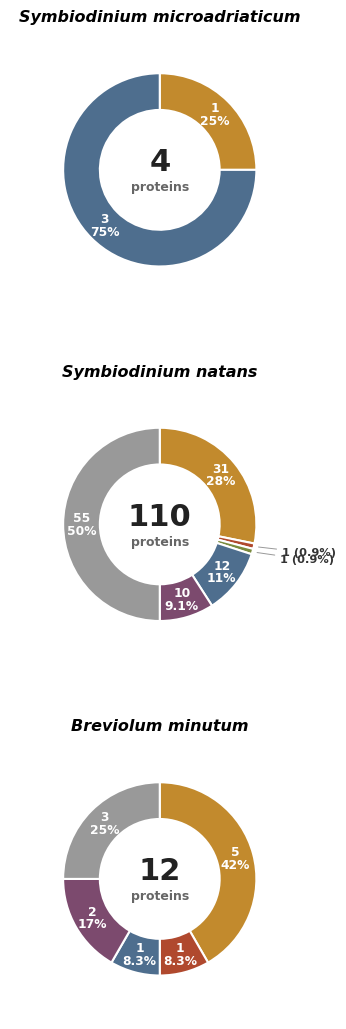

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/ALL_overlap_composition_donuts .pdf/.svg/.png
Figure size: 3.30 x 10.64 inches  (width = DATA_COL_W = 3.00)


In [ ]:
# ============================================================
# PANEL (B) — Functional composition donuts (one per strain, stacked)
#   v2: every non-zero slice carries its own "n (X%)" label.
#     • slices ≥8% → label inside, white, two lines (n / X%)
#     • slices <8% → label outside, dark, one line, leader line to slice
#   Slice fractions = protein_count / n_overlap  (each protein
#   contributes once via its primary Pfam category; CAT_ORDER tiebreak;
#   Pfam-less proteins → 'Other / uncategorised').
#   Donut hole shows the overlap n (matches panel (A) lens counts).
#   Width = DATA_COL_W (matches one Pfam panel column).
#
#   Run AFTER the panel (C) cell so the following are in scope:
#     merged, CAT_ORDER, PFAM_CAT_COLORS, parse_eggnog_pfam,
#     assign_category, SPECIES, n_overlap, DATA_COL_W, FIGDIR
# ============================================================

from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
import os

STACK_ORDER          = ["Smic", "Snat", "Bmin"]   # matches panel (A) order
INSIDE_THRESHOLD_PCT = 8.0                         # below this → outside label
DONUT_INNER_R        = 0.62                        # 1 - wedgeprops.width
DONUT_R              = 1.00

def primary_category(pfams):
    """Dominant Pfam category for one protein; CAT_ORDER tiebreak.
    No Pfams -> 'Other / uncategorised' (so slices sum to full n)."""
    if not pfams:
        return "Other / uncategorised"
    cnt = Counter(assign_category(p) for p in pfams)
    maxn = max(cnt.values())
    for c in CAT_ORDER:
        if cnt.get(c, 0) == maxn:
            return c
    return "Other / uncategorised"

def composition(strain):
    sub = merged[merged.strain == strain]
    out = {c: 0 for c in CAT_ORDER}
    for _, r in sub.iterrows():
        out[primary_category(parse_eggnog_pfam(r.get("final_Pfam")))] += 1
    return out

# ── figure dimensions ─────────────────────────────────────
DONUT_W   = DATA_COL_W
DONUT_H   = DATA_COL_W
HSPACE_IN = 0.55
TOP_IN, BOT_IN, LR_PAD_IN = 0.35, 0.20, 0.15

fig_w = DONUT_W + 2 * LR_PAD_IN
fig_h = 3 * DONUT_H + 2 * HSPACE_IN + TOP_IN + BOT_IN

fig_b = plt.figure(figsize=(fig_w, fig_h))
gs_b = gridspec.GridSpec(
    3, 1, height_ratios=[1, 1, 1], hspace=HSPACE_IN / DONUT_H,
    left=LR_PAD_IN / fig_w, right=1 - LR_PAD_IN / fig_w,
    top=1 - TOP_IN / fig_h, bottom=BOT_IN / fig_h,
)

for i, strain in enumerate(STACK_ORDER):
    ax = fig_b.add_subplot(gs_b[i])
    comp   = composition(strain)
    items  = [(c, comp[c]) for c in CAT_ORDER if comp[c] > 0]
    sizes  = [v for _, v in items]
    colors = [PFAM_CAT_COLORS[c] for c, _ in items]
    n_tot  = sum(sizes)

    if n_tot == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, "no overlap", transform=ax.transAxes,
                ha="center", va="center", color="#888")
        continue

    wedges, _ = ax.pie(
        sizes, colors=colors,
        startangle=90, counterclock=False,
        wedgeprops=dict(width=DONUT_R - DONUT_INNER_R,
                        edgecolor="white", linewidth=1.5),
    )

    # ── per-slice labels: count + % on every non-zero slice ──
    for w, v in zip(wedges, sizes):
        pct = v / n_tot * 100
        ang = 0.5 * (w.theta1 + w.theta2)
        rad = np.deg2rad(ang)
        pct_str = f"{pct:.0f}%" if pct >= 10 else f"{pct:.1f}%"

        if pct >= INSIDE_THRESHOLD_PCT:
            r_lab = 0.5 * (DONUT_R + DONUT_INNER_R)         # middle of ring
            ax.text(r_lab * np.cos(rad), r_lab * np.sin(rad),
                    f"{v}\n{pct_str}", ha="center", va="center",
                    fontsize=8.8, fontweight="bold", color="white",
                    linespacing=0.95, zorder=5)
        else:
            x_tip = 1.02 * np.cos(rad); y_tip = 1.02 * np.sin(rad)
            x_lab = 1.30 * np.cos(rad); y_lab = 1.30 * np.sin(rad)
            ha = "left" if x_lab > 0 else "right"
            ax.annotate(
                f"{v} ({pct_str})", xy=(x_tip, y_tip),
                xytext=(x_lab, y_lab), ha=ha, va="center",
                fontsize=8.2, fontweight="bold", color="#333",
                arrowprops=dict(arrowstyle="-", color="#999", lw=0.7),
                zorder=5, clip_on=False,
            )

    # ── donut hole: total n ───────────────────────────────
    ax.text(0, 0.08, f"{n_tot}", ha="center", va="center",
            fontsize=22, fontweight="bold", color="#222")
    ax.text(0, -0.18, "proteins", ha="center", va="center",
            fontsize=9, fontweight="bold", color="#666")

    ax.set_title(SPECIES[strain], fontsize=11.5, fontweight="bold",
                 fontstyle="italic", color="black", pad=6)
    # widen the axis a touch so outside labels aren't clipped
    ax.set_xlim(-1.55, 1.55); ax.set_ylim(-1.45, 1.45)
    ax.set_aspect("equal")

out_b = os.path.join(FIGDIR, "ALL_overlap_composition_donuts")
for ext, dpi in [("pdf", None), ("svg", None), ("png", 600)]:
    fig_b.savefig(f"{out_b}.{ext}", bbox_inches="tight",
                  **({"dpi": dpi} if dpi else {}))
plt.show()
print("Saved:", out_b, ".pdf/.svg/.png")
print(f"Figure size: {fig_w:.2f} x {fig_h:.2f} inches  "
      f"(width = DATA_COL_W = {DATA_COL_W:.2f})")

In [ ]:
# ============================================================
# DIAGNOSTIC — Pfam domains currently in 'Other / uncategorised'
#   Lists every Pfam in the overlap set that assign_category()
#   routes to 'Other / uncategorised', with per-strain protein
#   counts and an example eggNOG description for context.
#   Use this to top up CATEGORY_BY_ID in the panel (C) cell.
#
#   Run AFTER the panel (C) cell so the following are in scope:
#     merged, parse_eggnog_pfam, assign_category, clean_protein_id,
#     STRAINS, base
# ============================================================

import os
import pandas as pd

# ── build (protein, Pfam) long table for the overlap ──────
rows = []
for _, r in merged.iterrows():
    pid  = clean_protein_id(r["final_protein_id"])
    desc = r.get("final_eggnog_description") or ""
    gene = r.get("final_eggnog_gene_name") or ""
    for nm in set(parse_eggnog_pfam(r.get("final_Pfam"))):
        rows.append({
            "Pfam":   nm,
            "strain": r["strain"],
            "protein": pid,
            "gene":   gene if isinstance(gene, str) else "",
            "desc":   desc if isinstance(desc, str) else "",
        })
long = pd.DataFrame(rows).drop_duplicates(["Pfam", "strain", "protein"])

# ── keep only those currently classified as Other ─────────
long["category"] = long["Pfam"].map(assign_category)
other = long[long["category"] == "Other / uncategorised"].copy()

if other.empty:
    print("No overlap Pfams currently fall in 'Other / uncategorised'. Nothing to recategorise.")
else:
    def first_nonempty(s):
        for v in s:
            if isinstance(v, str) and v.strip() not in ("", "-"):
                return v.strip()
        return ""

    agg = (other.groupby("Pfam")
                 .agg(n_proteins=("protein", "nunique"),
                      example_gene=("gene", first_nonempty),
                      example_desc=("desc", first_nonempty),
                      strains_seen=("strain", lambda s: ",".join(sorted(set(s)))))
                 .reset_index())

    # per-strain protein-count breakdown
    by_strain = (other.groupby(["Pfam", "strain"])["protein"].nunique()
                       .unstack(fill_value=0)
                       .reindex(columns=STRAINS, fill_value=0))
    agg = agg.merge(by_strain, on="Pfam", how="left")

    agg = agg.sort_values(["n_proteins", "Pfam"],
                          ascending=[False, True]).reset_index(drop=True)

    # ── printed table ─────────────────────────────────────
    print(f"\n{len(agg)} Pfam domain(s) currently 'Other / uncategorised'  "
          f"(across {other['protein'].nunique()} unique proteins)\n")
    hdr = (f"{'Pfam':<22}  {'n':>3}  "
           f"{'Smic':>4} {'Snat':>4} {'Bmin':>4}   description (eggNOG)")
    print(hdr)
    print("-" * (len(hdr) + 30))
    for _, r in agg.iterrows():
        d = r["example_desc"]
        d = (d[:72] + "…") if len(d) > 72 else d
        print(f"{r['Pfam']:<22}  {r['n_proteins']:>3}  "
              f"{r['Smic']:>4} {r['Snat']:>4} {r['Bmin']:>4}   {d}")

    # ── save full table ───────────────────────────────────
    out_diag = os.path.join(base, "Publication", "data_pre",
                            "ALL_overlap_other_pfam_review.tsv")
    agg.to_csv(out_diag, sep="\t", index=False)
    print(f"\nSaved full review table: {out_diag}")

    # ── starter snippet for CATEGORY_BY_ID ────────────────
    print("\n# ── copy into CATEGORY_BY_ID and edit the category strings ──")
    for _, r in agg.iterrows():
        hint = r["example_desc"][:55]
        print(f'    "{r["Pfam"]}": "Other / uncategorised",   '
              f'# n={r["n_proteins"]}  {hint}')


9 Pfam domain(s) currently 'Other / uncategorised'  (across 6 unique proteins)

Pfam                      n  Smic Snat Bmin   description (eggNOG)
------------------------------------------------------------------------------------------------
DUF1501                   1     0    1    0   Protein of unknown function (DUF1501)
DUF1800                   1     0    1    0   Protein of unknown function (DUF1501)
DUF1966                   1     1    0    0   Alpha-amylase domain
DUF305                    1     0    1    0   Domain of unknown function (DUF305)
DUF4347                   1     0    1    0   Domain of unknown function (DUF4347)
Endotoxin_C               1     0    1    0   delta endotoxin, N-terminal domain
Endotoxin_N               1     0    1    0   delta endotoxin, N-terminal domain
SBBP                      1     0    1    0   Domain of unknown function (DUF4347)
YHYH                      1     0    1    0   

Saved full review table: /content/drive/MyDrive/UTokyo/Proteom

Inheriting scale from Panel A:  legend=[1, 0.5, 0.1]  BUBBLE_SCALE=700.0


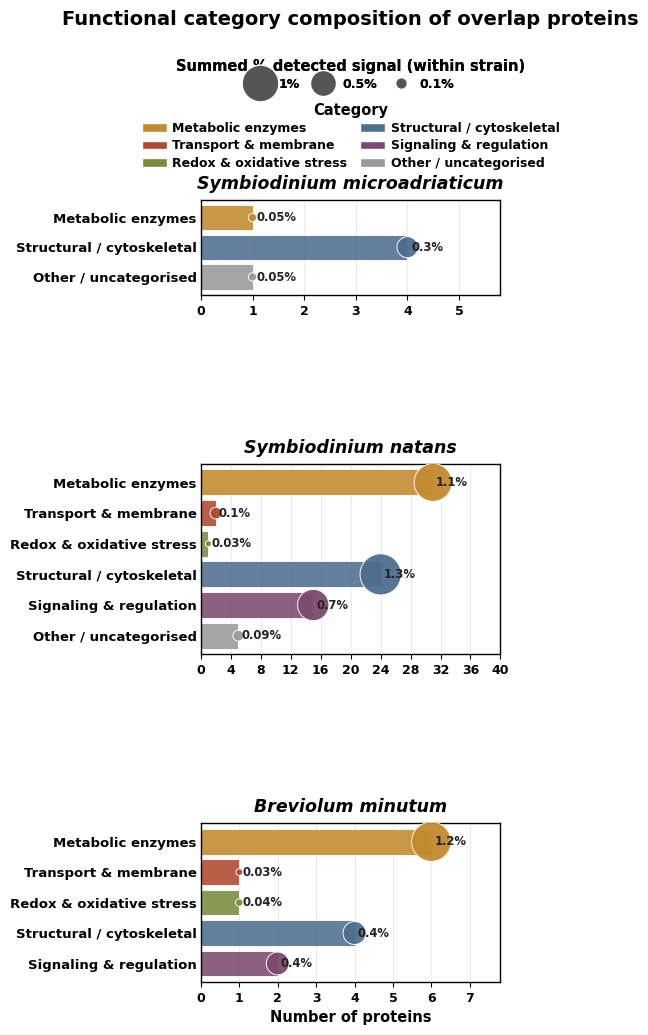

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/ALL_overlap_category_barplots .pdf/.svg/.png


In [4]:
# ============================================================
# PANEL (B) — Functional composition as category bar plots
#   Sum-per-category: each bar summarises the total abundance
#   share (within-strain fraction-of-total × 100) contributed by
#   every protein carrying at least one Pfam in that category.
#   One protein counted once per category, even with multiple Pfams.
#
#   Panel (A) — the per-Pfam plot — must run FIRST.
#   This cell inherits BUBBLE_SCALE, legend_vals and max_pct from
#   Panel (A) so bubble sizes are directly comparable between panels.
#   If those globals are missing, it falls back to a fresh preset.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

STACK_ORDER = ["Smic", "Snat", "Bmin"]

# ── build per-strain category summary (SUM aggregation) ─────
def category_bar_table(strain):
    sub = merged[merged.strain == strain].copy()
    sub["__key"] = sub["final_protein_id"].map(clean_protein_id)

    ab = abund.get(strain, {})
    rows = []

    for _, r in sub.iterrows():
        prot = r["__key"]

        if pd.isna(prot):
            continue

        pfams = set(parse_eggnog_pfam(r.get("final_Pfam")))

        # Ignore proteins without Pfam
        if not pfams:
            continue

        cats = [assign_category(pf) for pf in pfams]

        # One protein contributes once per category (deduplicated)
        for cat in sorted(
            set(cats),
            key=lambda x: CAT_ORDER.index(x) if x in CAT_ORDER else 999
        ):
            rows.append({
                "protein": prot,
                "category": cat,
                "abund_frac": ab.get(prot, 0.0)
            })

    if not rows:
        return pd.DataFrame(columns=["category", "n_proteins", "sum_abund_pct"])

    long = pd.DataFrame(rows).drop_duplicates(["protein", "category"])

    # SUM per category — matches Panel A's sum-per-Pfam encoding
    agg = (
        long.groupby("category")
            .agg(
                n_proteins=("protein", "nunique"),
                sum_abund=("abund_frac", "sum")
            )
            .reset_index()
    )

    # Fill in zero rows for missing categories
    full = pd.DataFrame({"category": CAT_ORDER})
    agg = full.merge(agg, on="category", how="left")

    agg["n_proteins"] = agg["n_proteins"].fillna(0).astype(int)
    agg["sum_abund"] = agg["sum_abund"].fillna(0.0)
    agg["sum_abund_pct"] = agg["sum_abund"] * 100

    agg["category"] = pd.Categorical(
        agg["category"],
        categories=CAT_ORDER,
        ordered=True
    )

    return agg.sort_values("category").reset_index(drop=True)


cat_tables = {s: category_bar_table(s) for s in STACK_ORDER}

cat_tables_plot = {
    s: cat_tables[s][cat_tables[s]["n_proteins"] > 0].copy()
    for s in STACK_ORDER
}

n_rows_plot = {
    s: max(1, len(cat_tables_plot[s]))
    for s in STACK_ORDER
}

# ── SHARED SCALE with Panel A ───────────────────────────────
# Panel A defines BUBBLE_SCALE, legend_vals and max_pct as module-level
# variables. Inherit them so that a 5% bubble in Panel A and a 5% bubble
# here render at the same visual area.
try:
    _ = BUBBLE_SCALE, legend_vals
    print(f"Inheriting scale from Panel A:  legend={legend_vals}  "
          f"BUBBLE_SCALE={BUBBLE_SCALE:.1f}")
except NameError:
    # Fallback: derive from this panel's data only. Panel A should be run first
    # in normal use; this branch keeps the cell runnable in isolation.
    max_pct_local = max(
        (t["sum_abund_pct"].max() for t in cat_tables_plot.values() if not t.empty),
        default=10.0
    )
    LEGEND_PRESETS = {
        1: [1, 0.5, 0.1],   2: [2, 1, 0.2],   3: [3, 1.5, 0.3],
        5: [5, 2, 0.5],     8: [8, 4, 1],     10: [10, 5, 1],
        12: [12, 6, 1],     15: [15, 8, 2],   20: [20, 10, 2],
        25: [25, 12, 3],    30: [30, 15, 3],  40: [40, 20, 5],
        50: [50, 25, 5],    75: [75, 40, 10], 100: [100, 50, 10]
    }
    legend_top  = next((v for v in sorted(LEGEND_PRESETS) if v >= max_pct_local), 100)
    legend_vals = LEGEND_PRESETS[legend_top]
    BUBBLE_SCALE = 700.0 / max(legend_vals)
    print(f"[!] Panel A globals missing — computed fresh: legend={legend_vals}  "
          f"BUBBLE_SCALE={BUBBLE_SCALE:.1f}")


def fmt_pct(p):
    if not np.isfinite(p) or p == 0:
        return "0%"
    if p < 0.1:
        return f"{p:.2f}%"
    return f"{p:.1f}%"


def fmt_legend_pct(v):
    return f"{v:g}%" if v >= 1 else f"{v:.1f}%"


def msize(v):
    return np.sqrt(max(v * BUBBLE_SCALE, 1.0))


# ── figure size: same width as one detailed Pfam panel ─────
BAR_W = DATA_COL_W

ROW_H     = 0.48
TOP_IN    = 1.95
BOT_IN    = 0.35
LR_PAD_IN = 0.18
HSPACE_IN = 0.55

fig_w = BAR_W + 2 * LR_PAD_IN

fig_h = (
    sum(n_rows_plot[s] * ROW_H for s in STACK_ORDER)
    + 2 * HSPACE_IN
    + TOP_IN
    + BOT_IN
)

fig_b = plt.figure(figsize=(fig_w, fig_h))

gs_b = gridspec.GridSpec(
    3, 1,
    height_ratios=[n_rows_plot[s] for s in STACK_ORDER],
    hspace=HSPACE_IN / ROW_H,
    left=LR_PAD_IN / fig_w,
    right=1 - LR_PAD_IN / fig_w,
    top=1 - TOP_IN / fig_h,
    bottom=BOT_IN / fig_h
)

# ── plot panels ─────────────────────────────────────────────
for i, strain in enumerate(STACK_ORDER):
    ax = fig_b.add_subplot(gs_b[i])
    tbl = cat_tables_plot[strain].copy()

    if tbl.empty:
        ax.axis("off")
        ax.text(0.5, 0.5, "no Pfam hits",
                transform=ax.transAxes, ha="center", va="center", color="#888")
        continue

    y = np.arange(len(tbl))[::-1]
    colors = [PFAM_CAT_COLORS[c] for c in tbl["category"].astype(str)]

    ax.barh(
        y,
        tbl["n_proteins"],
        height=0.85,
        color=colors,
        edgecolor="white",
        linewidth=0.7,
        alpha=0.88,
        zorder=2
    )

    bubble_pcts = tbl["sum_abund_pct"].values
    bubble_sizes = np.maximum(bubble_pcts * BUBBLE_SCALE, 18)

    ax.scatter(
        tbl["n_proteins"],
        y,
        s=bubble_sizes,
        c=colors,
        edgecolors="white",
        linewidths=0.7,
        alpha=0.95,
        zorder=3
    )

    xmax_i = max(1, int(tbl["n_proteins"].max()))
    xpad_i = max(1, int(np.ceil(xmax_i * 0.15)))
    label_offset = max(0.08, xpad_i * 0.08)

    for xi, yi, pct in zip(tbl["n_proteins"], y, bubble_pcts):
        ax.text(
            xi + label_offset,
            yi,
            fmt_pct(pct),
            ha="left", va="center",
            fontsize=8.4, fontweight="bold",
            color="#222", zorder=4, clip_on=False
        )

    ax.set_yticks(y)
    ax.set_yticklabels(
        tbl["category"].astype(str),
        fontsize=9.5, fontweight="bold"
    )
    ax.tick_params(axis="y", length=0, pad=3)
    ax.set_ylim(-0.6, len(tbl) - 0.4)
    ax.set_xlim(0, xmax_i + xpad_i * 1.8)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.tick_params(axis="x", labelbottom=True, labelsize=9)
    ax.grid(axis="x", linestyle="-", alpha=0.25, zorder=1)
    ax.set_axisbelow(True)

    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_linewidth(1.0)

    ax.set_title(
        SPECIES[strain],
        fontsize=12.5, fontweight="bold", fontstyle="italic",
        color="black", pad=8
    )

    if i == len(STACK_ORDER) - 1:
        ax.set_xlabel("Number of proteins",
                      fontsize=10.5, fontweight="bold")

# ── top title and legends ───────────────────────────────────
fig_b.suptitle(
    "Functional category composition of overlap proteins",
    fontsize=14.0, fontweight="bold", y=0.995
)

size_handles = [
    Line2D([0], [0], marker="o", linestyle="",
           markerfacecolor="#555", markeredgecolor="white",
           markersize=msize(v), label=fmt_legend_pct(v))
    for v in legend_vals
]

leg1 = fig_b.legend(
    handles=size_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=len(legend_vals),
    frameon=False,
    title="Summed % detected signal (within strain)",
    title_fontproperties={"weight": "bold", "size": 10.5},
    fontsize=9, columnspacing=0.9,
    handletextpad=0.5, borderpad=0.2, labelspacing=0.3
)
fig_b.add_artist(leg1)

cat_handles = [
    Patch(facecolor=PFAM_CAT_COLORS[c], edgecolor="white", label=c)
    for c in CAT_ORDER
]

fig_b.legend(
    handles=cat_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.912),
    ncol=2, frameon=False,
    title="Category",
    title_fontproperties={"weight": "bold", "size": 10.5},
    fontsize=9, columnspacing=1.0,
    handletextpad=0.45, labelspacing=0.35, borderpad=0.2
)

out_b = os.path.join(FIGDIR, "ALL_overlap_category_barplots")
for ext, dpi in [("pdf", None), ("svg", None), ("png", 600)]:
    fig_b.savefig(f"{out_b}.{ext}", bbox_inches="tight",
                  **({"dpi": dpi} if dpi else {}))

plt.show()
print("Saved:", out_b, ".pdf/.svg/.png")